# **P605 – Hourly Energy Consumption Forecasting**
## **Advanced Time-Series Forecasting + ML/DL Benchmarks**

**Project objective:** Analyze PJM hourly electricity consumption, understand the time-dependent patterns in depth, compare forecasting approaches fairly, and produce a 30-day / 720-hour hourly forecast.

> **Important modeling principle:** This is a time-series forecasting problem. We will not randomly shuffle observations. Historical observations are used to predict future observations, and every model is evaluated chronologically.

**Production-model rule:** Classical time-series models are the final production candidates. ML, PCA and LSTM are benchmark models and do not override the time-series selection.


In [89]:
# ============================================================
# 1. ENVIRONMENT SETUP AND ONE-TIME DATA LOADING
# ============================================================

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# The following packages are used later for forecasting models.
# Installing them once keeps the later cells focused on modeling.
!pip -q install openpyxl holidays xgboost statsmodels tensorflow
!pip install -q xgboost holidays


import xgboost as xgb
import holidays
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Libraries loaded successfully.")
print("Pandas version:", pd.__version__)


Libraries loaded successfully.
Pandas version: 2.2.3


In [2]:
# ============================================================
# 2. LOAD THE PJM DATASET ONCE AND CREATE A LOCAL CACHE
# ============================================================
# We do NOT repeatedly read the Excel file.
# First run: upload Excel -> read once -> save CSV cache.
# Later runs: read the much faster CSV cache.

CACHE_FILE = "PJMW_MW_Hourly_cached.csv"

if os.path.exists(CACHE_FILE):
    print("CSV cache found. Loading the cached dataset...")
    df = pd.read_csv(CACHE_FILE)
else:
    from google.colab import files

    print("Upload PJMW_MW_Hourly.xlsx once.")
    uploaded = files.upload()

    excel_files = [name for name in uploaded.keys() if name.lower().endswith(".xlsx")]
    if not excel_files:
        raise FileNotFoundError("Please upload PJMW_MW_Hourly.xlsx")

    excel_file = excel_files[0]

    print("Reading Excel file for the first time...")
    df = pd.read_excel(excel_file)

    # Save a local CSV cache so future reruns are faster.
    df.to_csv(CACHE_FILE, index=False)
    print("CSV cache created:", CACHE_FILE)

# Convert the date column immediately after loading.
df["Datetime"] = pd.to_datetime(df["Datetime"])
df["PJMW_MW"] = pd.to_numeric(df["PJMW_MW"], errors="coerce")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Upload PJMW_MW_Hourly.xlsx once.


Saving PJMW_MW_Hourly.xlsx to PJMW_MW_Hourly.xlsx
Reading Excel file for the first time...
CSV cache created: PJMW_MW_Hourly_cached.csv
Dataset loaded successfully.
Shape: (143206, 2)


,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


## **EDA Roadmap**

The EDA is intentionally detailed because the model should be based on what the data actually shows.

We will investigate:

1. Dataset structure and data quality
2. Overall consumption distribution
3. Long-term hourly trend
4. Hour-of-day demand pattern
5. Day-of-week and weekday/weekend behavior
6. Monthly and yearly trends
7. Seasonal behavior
8. Summer vs winter daily shape
9. All-season hourly behavior
10. Holiday vs non-holiday demand
11. Potential outliers and whether they should be removed
12. Daily/monthly resampling
13. Rolling averages
14. EDA findings table
15. Data cleaning and timestamp-gap investigation
16. Forecasting feature engineering
17. Correlation and leakage checks

This is not only visualization. Each section ends with an observation that can be connected to forecasting/model design.

## Exploratory Data Analysis (EDA)

### Project Objective

The objective of this project is to analyze historical PJM hourly
electricity consumption data and understand the patterns that can
help us forecast future energy consumption.

The EDA focuses on:

- Understanding the dataset structure and data quality
- Analyzing the overall long-term consumption trend
- Studying hourly consumption patterns
- Studying day-of-week and weekday/weekend patterns
- Studying monthly and yearly trends
- Understanding seasonal behavior
- Comparing summer and winter daily patterns
- Analyzing holiday and non-holiday consumption
- Identifying potential outliers
- Extracting useful observations for future feature engineering

The target variable is PJMW_MW, which represents electricity
consumption in megawatts (MW).

EDA is performed before modeling so that we understand the data,
identify important patterns, and determine which time-based
characteristics may be useful for forecasting.

### Why data quality comes before modeling

For ordinary tabular ML, a duplicate row may be a minor issue. For time-series forecasting, duplicate timestamps and missing hours can change lag relationships.

Therefore we first **identify** duplicates and gaps during EDA, then investigate and clean them in a separate cleaning section. We do not silently delete observations.

**DATASET STRUCTURE AND DATA QUALITY**

In [3]:
print("\n DATASET SHAPE ")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\n COLUMN NAMES ")
print(df.columns.tolist())

print("\n DATA TYPES AND NON-NULL VALUES ")
df.info()

print("\n SUMMARY STATISTICS ")
display(df.describe())

print("\n MISSING VALUES ")
print(df.isnull().sum())

print("\n DUPLICATE ROWS ")
print("Duplicate rows:", df.duplicated().sum())

print("\n DUPLICATE TIMESTAMPS ")
print("Duplicate timestamps:", df['Datetime'].duplicated().sum())

print("\n DATE RANGE ")
print("Start date:", df['Datetime'].min())
print("End date:", df['Datetime'].max())

print("\n TIME DIFFERENCE BETWEEN CONSECUTIVE RECORDS ")
time_difference = df['Datetime'].diff()
display(time_difference.value_counts().head(10))


 DATASET SHAPE 
Number of rows: 143206
Number of columns: 2

 COLUMN NAMES 
['Datetime', 'PJMW_MW']

 DATA TYPES AND NON-NULL VALUES 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB

 SUMMARY STATISTICS 


,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872



 MISSING VALUES 
Datetime    0
PJMW_MW     0
dtype: int64

 DUPLICATE ROWS 
Duplicate rows: 0

 DUPLICATE TIMESTAMPS 
Duplicate timestamps: 4

 DATE RANGE 
Start date: 2002-04-01 01:00:00
End date: 2018-08-03 00:00:00

 TIME DIFFERENCE BETWEEN CONSECUTIVE RECORDS 


,count
Datetime,
0 days 01:00:00,137205
-2 days +01:00:00,5950
0 days 02:00:00,29
729 days 01:00:00,8
728 days 01:00:00,6
0 days 00:00:00,4
638 days 01:00:00,1
-2 days +02:00:00,1
577 days 01:00:00,1


duplicate timestamps or time gaps their, we are not correcting them yet. That belongs to Data Cleaning, which comes after EDA.

**CREATING TIME-BASED FEATURES**

In [4]:
#Extracting hour
df['Hour'] = df['Datetime'].dt.hour

# Extracting the day of the week.
# Monday = 0 and Sunday = 6.
df['DayOfWeek'] = df['Datetime'].dt.dayofweek

# Extracting month number from 1 to 12.
df['Month'] = df['Datetime'].dt.month

# Extracting year.
df['Year'] = df['Datetime'].dt.year

# Creating a readable day name for analysis.
df['DayName'] = df['Datetime'].dt.day_name()

# Identify weekends.
# Saturday = 5 and Sunday = 6.
df['IsWeekend'] = df['DayOfWeek'] >= 5

In [5]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

df['Season'] = df['Month'].apply(get_season)

print("Time-based features created successfully.")
display(df.head())

Time-based features created successfully.


,Datetime,PJMW_MW,Hour,DayOfWeek,Month,Year,DayName,IsWeekend,Season
0,2002-12-31 01:00:00,5077,1,1,12,2002,Tuesday,False,Winter
1,2002-12-31 02:00:00,4939,2,1,12,2002,Tuesday,False,Winter
2,2002-12-31 03:00:00,4885,3,1,12,2002,Tuesday,False,Winter
3,2002-12-31 04:00:00,4857,4,1,12,2002,Tuesday,False,Winter
4,2002-12-31 05:00:00,4930,5,1,12,2002,Tuesday,False,Winter




* Here i have  Defined seasons for EDA.
* Winter: December, January, February
* Spring: March, April, May
* Summer: June, July, August
* Autumn: September, October, November

we are doing all these because electricity demand can depend on when the observation occurred.These columns will also help us later during Feature Engineering


In [90]:
# Copy the cleaned hourly dataset
xgb_df = df.copy()

# Calendar features
xgb_df["Hour"] = xgb_df["Datetime"].dt.hour
xgb_df["DayOfWeek"] = xgb_df["Datetime"].dt.dayofweek
xgb_df["DayOfYear"] = xgb_df["Datetime"].dt.dayofyear
xgb_df["Month"] = xgb_df["Datetime"].dt.month
xgb_df["Year"] = xgb_df["Datetime"].dt.year

xgb_df["IsWeekend"] = (
    xgb_df["DayOfWeek"] >= 5
).astype(int)

# US holidays
us_holidays = holidays.US()

xgb_df["IsHoliday"] = (
    xgb_df["Datetime"].dt.date
    .apply(lambda x: x in us_holidays)
    .astype(int)
)

# Lag features
for lag in [1, 24, 48, 168]:
    xgb_df[f"Lag_{lag}"] = (
        xgb_df["PJMW_MW"].shift(lag)
    )

# Rolling features
xgb_df["RollingMean_24"] = (
    xgb_df["PJMW_MW"]
    .shift(1)
    .rolling(24)
    .mean()
)

xgb_df["RollingMean_168"] = (
    xgb_df["PJMW_MW"]
    .shift(1)
    .rolling(168)
    .mean()
)

xgb_df["RollingStd_24"] = (
    xgb_df["PJMW_MW"]
    .shift(1)
    .rolling(24)
    .std()
)

xgb_df = xgb_df.dropna().reset_index(drop=True)

print(xgb_df.shape)
display(xgb_df.head())

(143038, 18)


,Datetime,PJMW_MW,Hour,DayOfWeek,Month,Year,DayName,IsWeekend,Season,IsHoliday,DayOfYear,Lag_1,Lag_24,Lag_48,Lag_168,RollingMean_24,RollingMean_168,RollingStd_24
0,2002-12-24 01:00:00,5158,1,1,12,2002,Tuesday,0,Winter,0,358,5364.0,5064.0,5165.0,5077.0,5417.375000,5839.434524,441.752322
1,2002-12-24 02:00:00,4965,2,1,12,2002,Tuesday,0,Winter,0,358,5158.0,4849.0,5035.0,4939.0,5421.291667,5839.916667,438.890447
2,2002-12-24 03:00:00,4855,3,1,12,2002,Tuesday,0,Winter,0,358,4965.0,4714.0,5009.0,4885.0,5426.125000,5840.071429,432.912012
3,2002-12-24 04:00:00,4848,4,1,12,2002,Tuesday,0,Winter,0,358,4855.0,4668.0,4996.0,4857.0,5432.000000,5839.892857,423.686102
4,2002-12-24 05:00:00,4905,5,1,12,2002,Tuesday,0,Winter,0,358,4848.0,4695.0,5071.0,4930.0,5439.500000,5839.839286,410.976462


In [91]:
features = [
    "Hour",
    "DayOfWeek",
    "DayOfYear",
    "Month",
    "Year",
    "IsWeekend",
    "IsHoliday",
    "Lag_1",
    "Lag_24",
    "Lag_48",
    "Lag_168",
    "RollingMean_24",
    "RollingMean_168",
    "RollingStd_24"
]

target = "PJMW_MW"

print("Number of features:", len(features))
print(features)

Number of features: 14
['Hour', 'DayOfWeek', 'DayOfYear', 'Month', 'Year', 'IsWeekend', 'IsHoliday', 'Lag_1', 'Lag_24', 'Lag_48', 'Lag_168', 'RollingMean_24', 'RollingMean_168', 'RollingStd_24']


**OVERALL CONSUMPTION DISTRIBUTION**


In [6]:
target = 'PJMW_MW'

print("----- BASIC CONSUMPTION STATISTICS -----")
print(f"Mean consumption:   {df[target].mean():,.2f} MW")
print(f"Median consumption: {df[target].median():,.2f} MW")
print(f"Minimum:            {df[target].min():,.2f} MW")
print(f"Maximum:            {df[target].max():,.2f} MW")
print(f"Standard deviation: {df[target].std():,.2f} MW")


----- BASIC CONSUMPTION STATISTICS -----
Mean consumption:   5,602.38 MW
Median consumption: 5,530.00 MW
Minimum:            487.00 MW
Maximum:            9,594.00 MW
Standard deviation: 979.14 MW


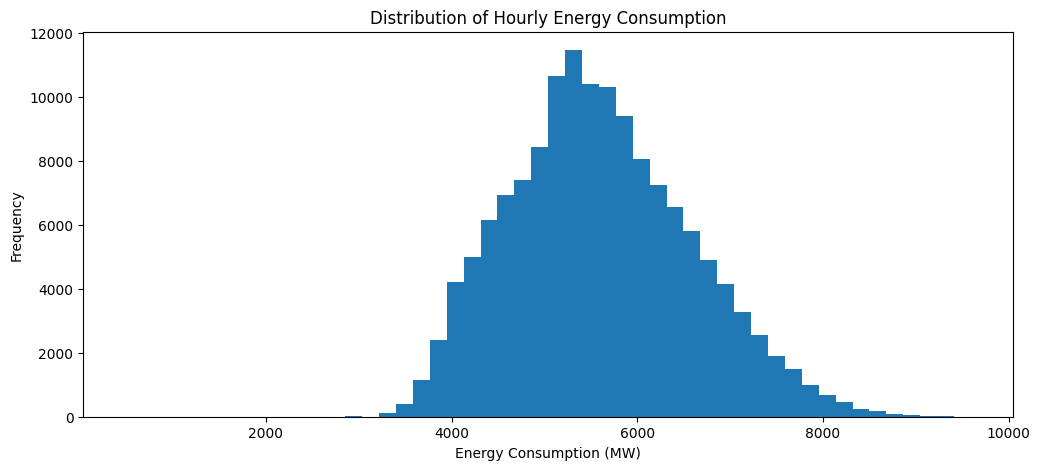

In [7]:
# Histogram
plt.figure(figsize=(12, 5))
plt.hist(df[target], bins=50)
plt.xlabel('Energy Consumption (MW)')
plt.ylabel('Frequency')
plt.title('Distribution of Hourly Energy Consumption')
plt.show()

The histogram helps us understand the distribution of electricity consumption.

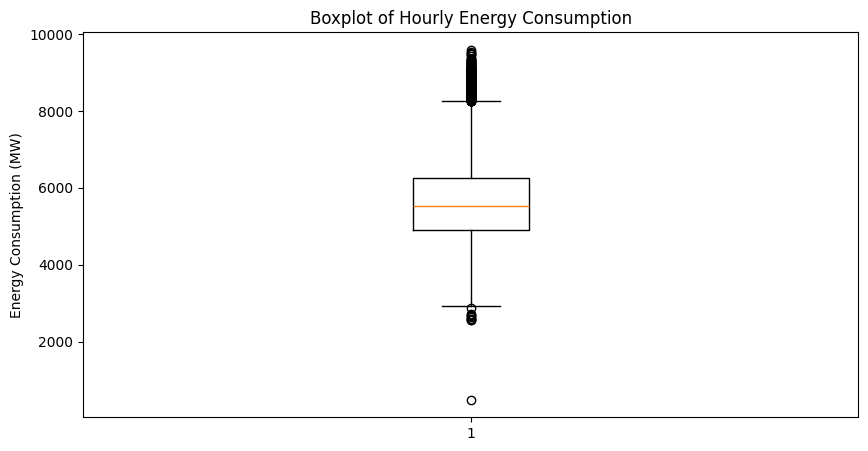

In [8]:
# Boxplot
plt.figure(figsize=(10, 5))
plt.boxplot(df[target], vert=True)
plt.ylabel('Energy Consumption (MW)')
plt.title('Boxplot of Hourly Energy Consumption')
plt.show()

* The boxplot helps us identify potential extreme observations.
* we can see an  observation outside the boxplot range is only a potential outlier. We should not automatically remove it because electricity demand can naturally have extreme peak values.

**Overall Time-Series Trend**

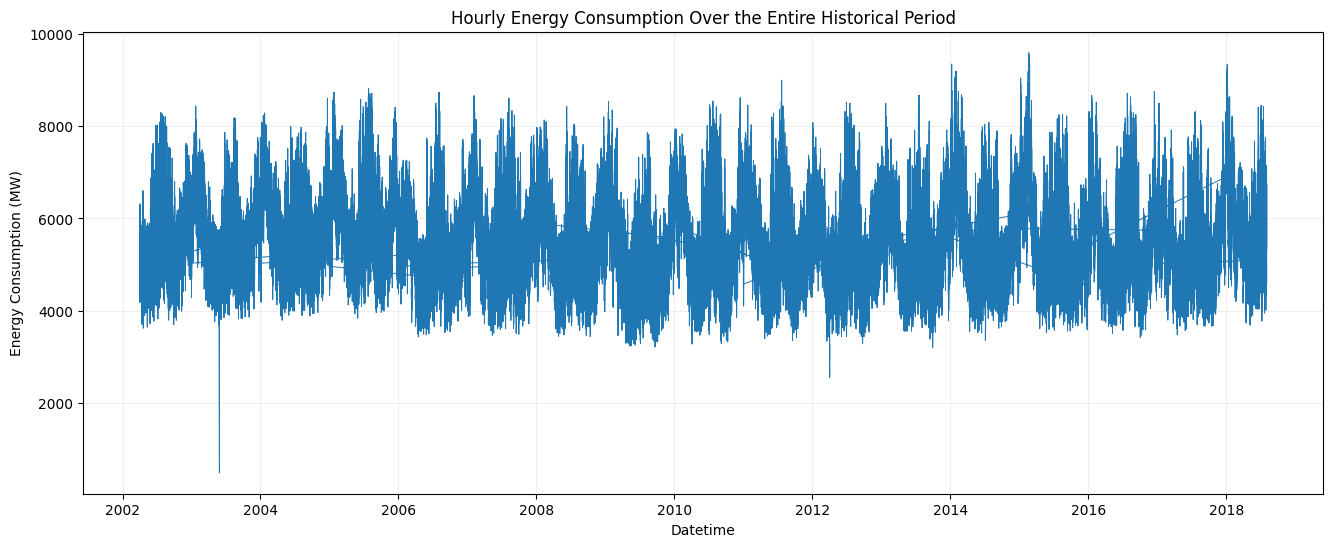

In [9]:
plt.figure(figsize=(16, 6))

plt.plot(
    df['Datetime'],
    df['PJMW_MW'],
    linewidth=0.7
)

plt.xlabel('Datetime')
plt.ylabel('Energy Consumption (MW)')
plt.title('Hourly Energy Consumption Over the Entire Historical Period')
plt.grid(alpha=0.2)
plt.show()

* This is the main graph for understanding the overall historical behavior.
we will look for long-term changes,repeated patterns,high-demand periods,low-demand periods,unusual periods and changes across years
* here after looking at graph we cannot conclude conclusion such as "consumption increased every year" until we actually inspect the graph.

**Hourly Consumption Pattern**

Average consumption for each hour:


,Average_Consumption_MW
Hour,
0,5230.368359
1,4940.489276
2,4779.152349
3,4697.121996
4,4672.537366
5,4734.933479
6,4958.209450
7,5323.434316
8,5571.168398


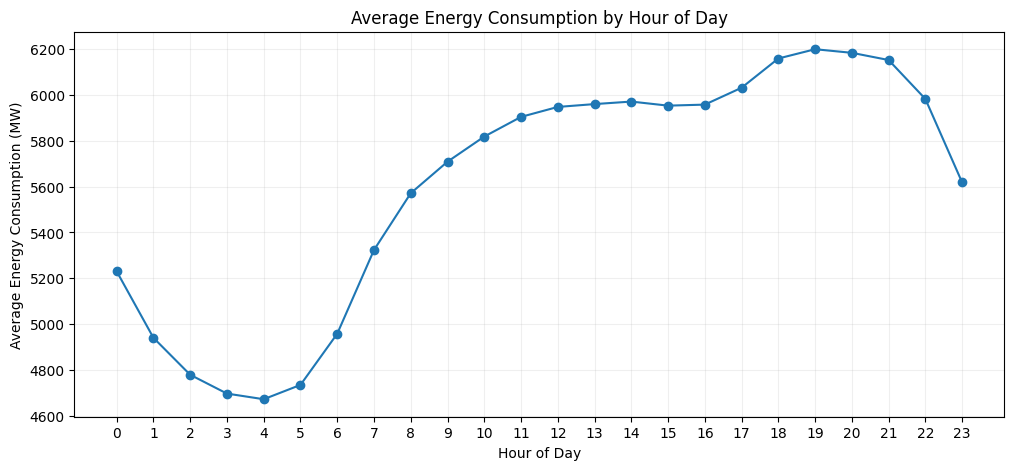

Highest average consumption hour: 19 with 6199.29 MW
Lowest average consumption hour: 4 with 4672.54 MW


In [10]:
hourly_avg = df.groupby('Hour')[target].mean()

print("Average consumption for each hour:")
display(hourly_avg.to_frame('Average_Consumption_MW'))

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker='o'
)

plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Average Energy Consumption by Hour of Day')
plt.xticks(range(24))
plt.grid(alpha=0.2)

plt.show()

print("Highest average consumption hour:",
      hourly_avg.idxmax(),
      "with",
      round(hourly_avg.max(), 2),
      "MW")

print("Lowest average consumption hour:",
      hourly_avg.idxmin(),
      "with",
      round(hourly_avg.min(), 2),
      "MW")

These output automatically tells us the highest and lowest average consumption hours.

**Day-of-Week and Weekday/Weekend Analysis**

Average consumption by day of week:


,Average_Consumption_MW
DayName,
Monday,5700.518783
Tuesday,5801.076837
Wednesday,5802.370701
Thursday,5780.841051
Friday,5686.839202
Saturday,5293.999413
Sunday,5149.638300


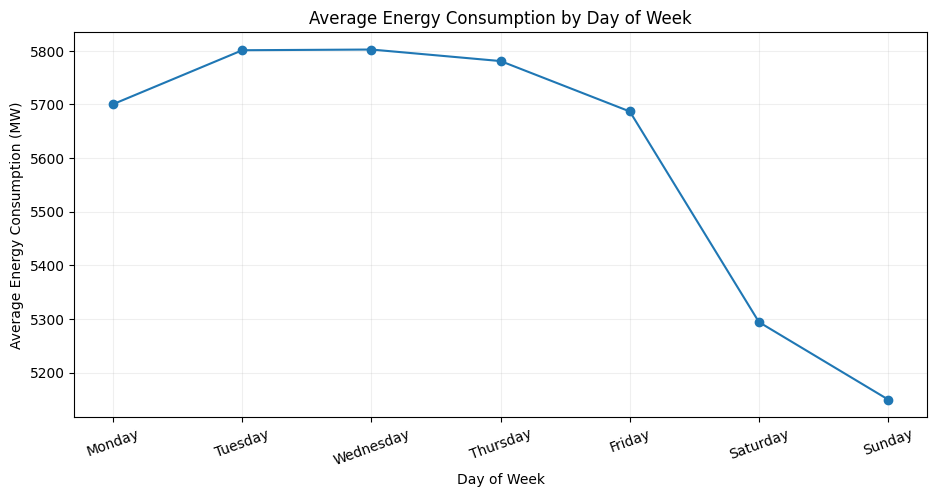

In [11]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_avg = (
    df.groupby('DayName')[target]
    .mean()
    .reindex(day_order)
)

print("Average consumption by day of week:")
display(daily_avg.to_frame('Average_Consumption_MW'))

# Day-of-week graph
plt.figure(figsize=(11, 5))

plt.plot(
    daily_avg.index,
    daily_avg.values,
    marker='o'
)

plt.xlabel('Day of Week')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Average Energy Consumption by Day of Week')
plt.xticks(rotation=20)
plt.grid(alpha=0.2)

plt.show()

here we were checking whether consumption changes from Monday to Sunday. yes it is getting changed


Weekday vs Weekend average consumption:
Weekday: 5,754.35 MW
Weekend: 5,221.86 MW


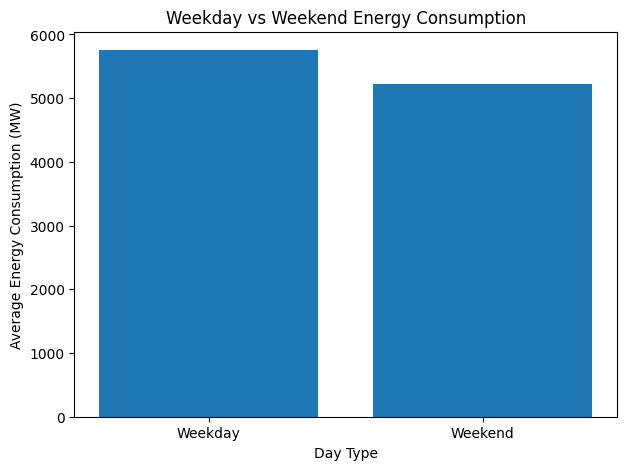

In [12]:
# Weekday vs weekend
weekend_avg = df.groupby('IsWeekend')[target].mean()

weekend_labels = ['Weekday', 'Weekend']

print("\nWeekday vs Weekend average consumption:")
for status, value in weekend_avg.items():
    label = 'Weekend' if status else 'Weekday'
    print(f"{label}: {value:,.2f} MW")

plt.figure(figsize=(7, 5))

plt.bar(
    weekend_labels,
    [
        weekend_avg.get(False, 0),
        weekend_avg.get(True, 0)
    ]
)

plt.xlabel('Day Type')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Weekday vs Weekend Energy Consumption')

plt.show()

sameway Whether the average behavior differs between weekdays and weekends. yes it is

**Monthly and Yearly Trends**

Average consumption by month:


,Average_Consumption_MW
Month,
1,6447.667759
2,6296.808813
3,5654.097376
4,5022.310855
5,5015.845746
6,5516.756046
7,5861.537081
8,5822.142809
9,5205.872049


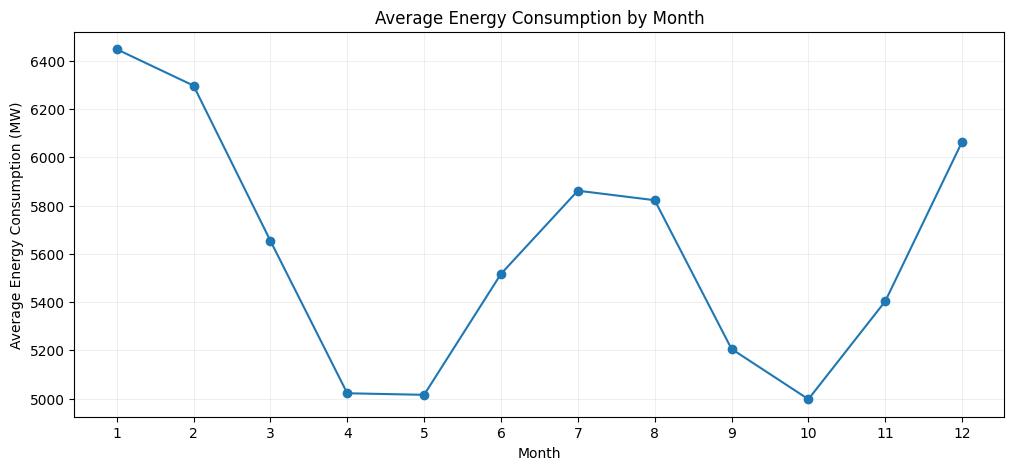

In [13]:
# Monthly average
monthly_avg = df.groupby('Month')[target].mean()

print("Average consumption by month:")
display(monthly_avg.to_frame('Average_Consumption_MW'))

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker='o'
)

plt.xlabel('Month')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Average Energy Consumption by Month')
plt.xticks(range(1, 13))
plt.grid(alpha=0.2)

plt.show()

Monthly analysis helps us understand the annual/seasonal cycle.

Average consumption by year:


,Average_Consumption_MW
Year,
2002,5621.663180
2003,5700.628226
2004,5866.616602
2005,6038.406029
2006,5425.448847
2007,5635.396780
2008,5530.132544
2009,5290.557433
2010,5573.025351


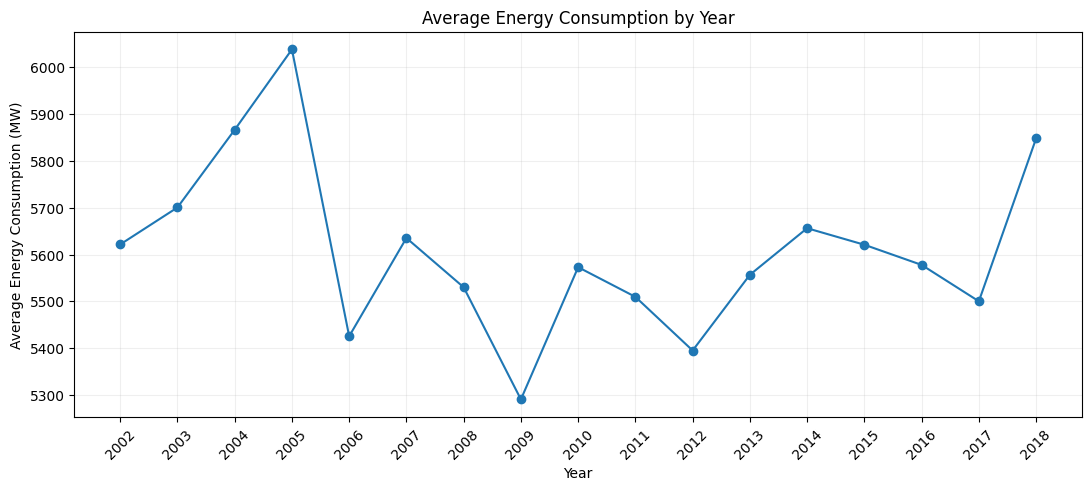

In [14]:

# Yearly average
yearly_avg = df.groupby('Year')[target].mean()

print("Average consumption by year:")
display(yearly_avg.to_frame('Average_Consumption_MW'))

plt.figure(figsize=(13, 5))

plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker='o'
)

plt.xlabel('Year')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Average Energy Consumption by Year')
plt.xticks(yearly_avg.index, rotation=45)
plt.grid(alpha=0.2)

plt.show()

Yearly analysis helps us understand long-term changes.

In [15]:
print("Highest average consumption month:",
      monthly_avg.idxmax(),
      f"({monthly_avg.max():,.2f} MW)")

print("Lowest average consumption month:",
      monthly_avg.idxmin(),
      f"({monthly_avg.min():,.2f} MW)")

print("Highest average consumption year:",
      yearly_avg.idxmax(),
      f"({yearly_avg.max():,.2f} MW)")

print("Lowest average consumption year:",
      yearly_avg.idxmin(),
      f"({yearly_avg.min():,.2f} MW)")

Highest average consumption month: 1 (6,447.67 MW)
Lowest average consumption month: 10 (4,997.64 MW)
Highest average consumption year: 2005 (6,038.41 MW)
Lowest average consumption year: 2009 (5,290.56 MW)


**Seasonal Analysis**

Average consumption by season:


,Average_Consumption_MW
Season,
Winter,6268.813851
Spring,5224.394790
Summer,5734.206129
Autumn,5200.143147


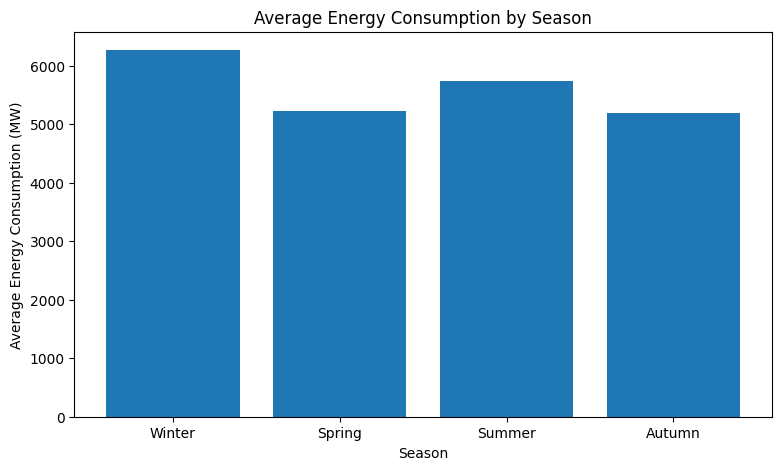

Highest average consumption season: Winter
Lowest average consumption season: Autumn


In [16]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

season_avg = (
    df.groupby('Season')[target]
    .mean()
    .reindex(season_order)
)

print("Average consumption by season:")
display(season_avg.to_frame('Average_Consumption_MW'))

plt.figure(figsize=(9, 5))

plt.bar(
    season_avg.index,
    season_avg.values
)

plt.xlabel('Season')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Average Energy Consumption by Season')

plt.show()

print("Highest average consumption season:",
      season_avg.idxmax())

print("Lowest average consumption season:",
      season_avg.idxmin())

here, We are not assuming that summer or winter is automatically the highest.

The dataset will tells us, we have to observe that.

**Summer vs Winter Daily Pattern**

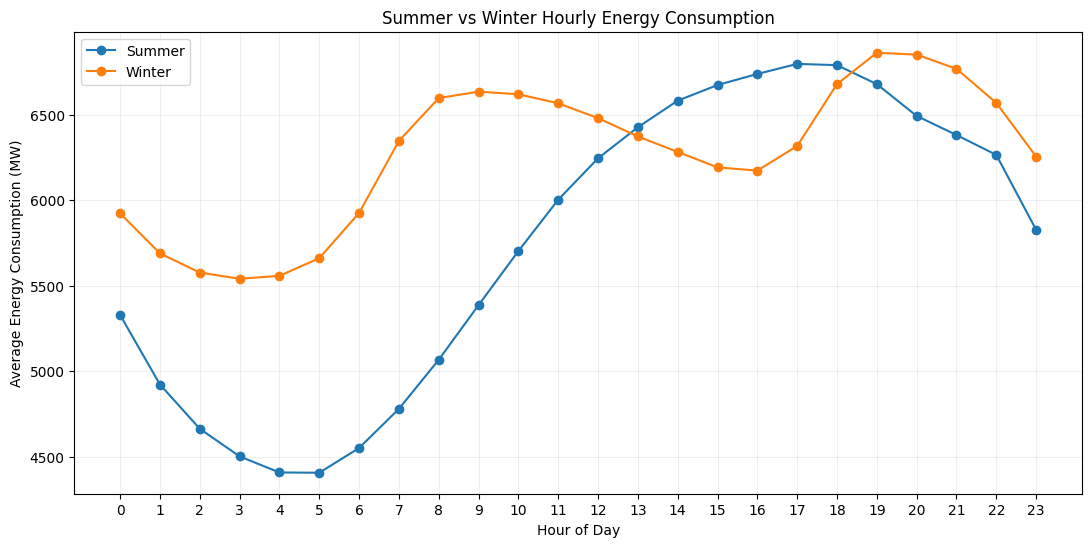

Summer average consumption: 5,734.21 MW
Winter average consumption: 6,268.81 MW

Summer peak hour: 17 (6,797.78 MW)
Winter peak hour: 19 (6,863.18 MW)


In [17]:
summer = df[df['Season'] == 'Summer']
winter = df[df['Season'] == 'Winter']

summer_hourly = summer.groupby('Hour')[target].mean()
winter_hourly = winter.groupby('Hour')[target].mean()

plt.figure(figsize=(13, 6))

plt.plot(
    summer_hourly.index,
    summer_hourly.values,
    marker='o',
    label='Summer'
)

plt.plot(
    winter_hourly.index,
    winter_hourly.values,
    marker='o',
    label='Winter'
)

plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Summer vs Winter Hourly Energy Consumption')
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.2)

plt.show()

print("Summer average consumption:",
      f"{summer[target].mean():,.2f} MW")

print("Winter average consumption:",
      f"{winter[target].mean():,.2f} MW")

print("\nSummer peak hour:",
      summer_hourly.idxmax(),
      f"({summer_hourly.max():,.2f} MW)")

print("Winter peak hour:",
      winter_hourly.idxmax(),
      f"({winter_hourly.max():,.2f} MW)")

here, We are not only comparing average summer and winter consumption.We are  also comparing the shape of the daily pattern.which helps us to  directly addresses the project's requirement about seasonal daily trends.

**All Seasons by Hour**

Season,Winter,Spring,Summer,Autumn
Hour,,,,
0,5922.839917,4883.665144,5327.760417,4806.136676
1,5688.731994,4630.318982,4921.393485,4545.118819
2,5576.684903,4499.615786,4662.691205,4403.227210
3,5540.664820,4441.108839,4501.020847,4333.835852
4,5557.793629,4441.919765,4407.318567,4317.000000
5,5661.231994,4525.054142,4405.762866,4384.278846
6,5926.093490,4776.295499,4550.683388,4619.474588
7,6347.755540,5172.560339,4779.746580,5039.595467
8,6597.767313,5405.725375,5067.076873,5258.665522


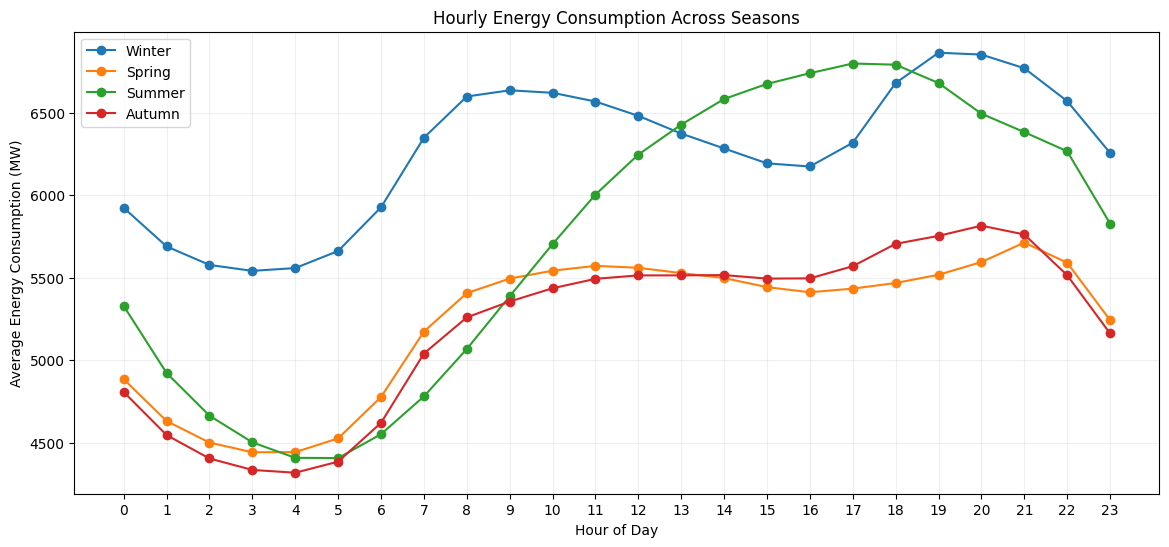

In [18]:
season_hourly = (
    df.groupby(['Season', 'Hour'])[target]
    .mean()
    .unstack(level=0)
)

# Arranging columns in a logical seasonal order
season_hourly = season_hourly.reindex(
    columns=season_order
)

display(season_hourly)

plt.figure(figsize=(14, 6))

for season in season_order:
    plt.plot(
        season_hourly.index,
        season_hourly[season],
        marker='o',
        label=season
    )

plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Hourly Energy Consumption Across Seasons')
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.2)

plt.show()

we previously compared only summer and winter.This one lets us understand the complete seasonal daily behavior.

**Holiday Analysis**

these is us electricity data so we have to use their holidays
*  Install/use the holidays package to identify U.S. public holidays.which makes us more reliable than manually entering individual holiday dates.



Holiday records: 4320
Non-holiday records: 138886

Average consumption:
Non-Holiday: 5,606.28 MW
Holiday:     5,476.77 MW


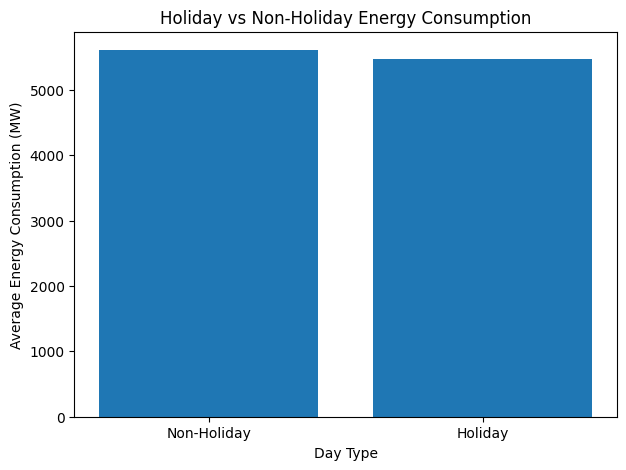

In [19]:
!pip -q install holidays

import holidays

# Creating U.S. holiday calendar
us_holidays = holidays.US()

# Marking each timestamp as holiday or non-holiday
df['IsHoliday'] = df['Datetime'].dt.date.apply(
    lambda date: date in us_holidays
)

print("Holiday records:", df['IsHoliday'].sum())
print("Non-holiday records:", (~df['IsHoliday']).sum())

# Comparing average consumption
holiday_avg = df.groupby('IsHoliday')[target].mean()

print("\nAverage consumption:")
print(f"Non-Holiday: {holiday_avg.get(False, float('nan')):,.2f} MW")
print(f"Holiday:     {holiday_avg.get(True, float('nan')):,.2f} MW")

plt.figure(figsize=(7, 5))

plt.bar(
    ['Non-Holiday', 'Holiday'],
    [
        holiday_avg.get(False, 0),
        holiday_avg.get(True, 0)
    ]
)

plt.xlabel('Day Type')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Holiday vs Non-Holiday Energy Consumption')

plt.show()

Electricity demand can change when normal working and activity schedules change.These project requirement explicitly asks us to investigate holiday-related trends.

**Holiday vs Non-Holiday Hourly Pattern**

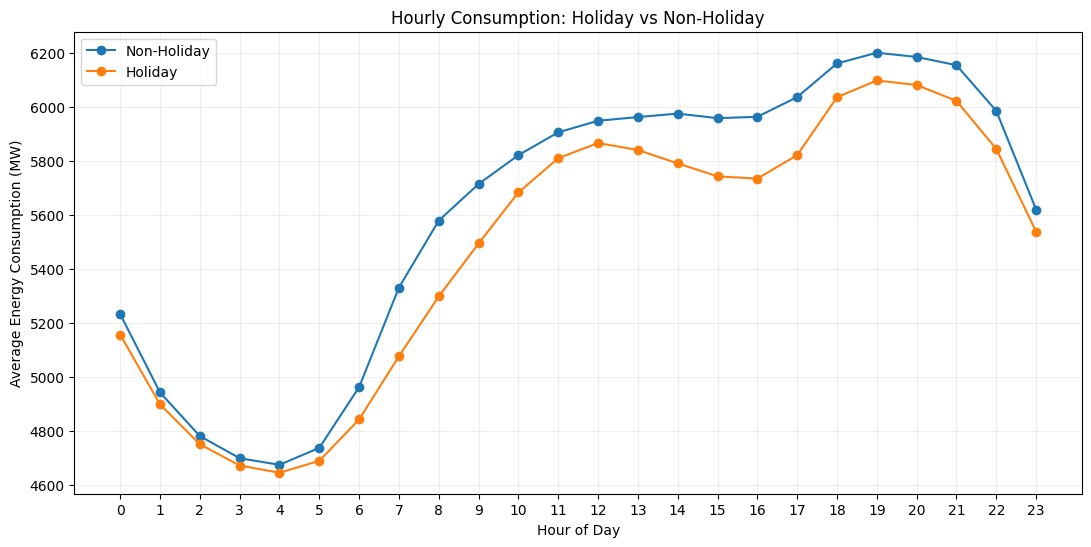

In [20]:
holiday_hourly = (
    df[df['IsHoliday'] == True]
    .groupby('Hour')[target]
    .mean()
)

normal_hourly = (
    df[df['IsHoliday'] == False]
    .groupby('Hour')[target]
    .mean()
)

plt.figure(figsize=(13, 6))

plt.plot(
    normal_hourly.index,
    normal_hourly.values,
    marker='o',
    label='Non-Holiday'
)

plt.plot(
    holiday_hourly.index,
    holiday_hourly.values,
    marker='o',
    label='Holiday'
)

plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.title('Hourly Consumption: Holiday vs Non-Holiday')
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.2)

plt.show()

From the above we can clearly observe that non holiday it is higher than holidays

**Potential Outlier Analysis**

In [21]:
Q1 = df[target].quantile(0.25)
Q3 = df[target].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

potential_outliers = df[
    (df[target] < lower_limit) |
    (df[target] > upper_limit)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))

print("\nNumber of potential outliers:",
      len(potential_outliers))

print("\nPercentage of potential outliers:",
      round(len(potential_outliers) / len(df) * 100, 2), "%")

print("\nHighest consumption records:")
display(
    df.nlargest(10, target)[
        ['Datetime', target]
    ]
)

print("\nLowest consumption records:")
display(
    df.nsmallest(10, target)[
        ['Datetime', target]
    ]
)

Q1: 4907.0
Q3: 6252.0
IQR: 1345.0
Lower limit: 2889.5
Upper limit: 8269.5

Number of potential outliers: 703

Percentage of potential outliers: 0.49 %

Highest consumption records:


,Datetime,PJMW_MW
119310,2015-02-20 08:00:00,9594
119346,2015-02-19 20:00:00,9536
119309,2015-02-20 07:00:00,9512
119345,2015-02-19 19:00:00,9489
119311,2015-02-20 09:00:00,9481
119347,2015-02-19 21:00:00,9424
119214,2015-02-24 08:00:00,9366
111618,2014-01-07 20:00:00,9349
143105,2018-01-05 20:00:00,9342
143104,2018-01-05 19:00:00,9325



Lowest consumption records:


,Datetime,PJMW_MW
11828,2003-05-29 00:00:00,487
92065,2012-04-02 00:00:00,2553
92057,2012-04-01 16:00:00,2574
92058,2012-04-01 17:00:00,2586
92059,2012-04-01 18:00:00,2600
92060,2012-04-01 19:00:00,2630
92056,2012-04-01 15:00:00,2663
92064,2012-04-01 23:00:00,2690
92055,2012-04-01 14:00:00,2721
92054,2012-04-01 13:00:00,2878


here simply we cannot say that, "We found outliers, so we removed them."
Not yet.We first need to determine whether extreme values are:
* data errors,unusual events,genuine peak electricity demand
these all done in Data Cleaning.

**Daily and Monthly Resampling for Long-Term View**

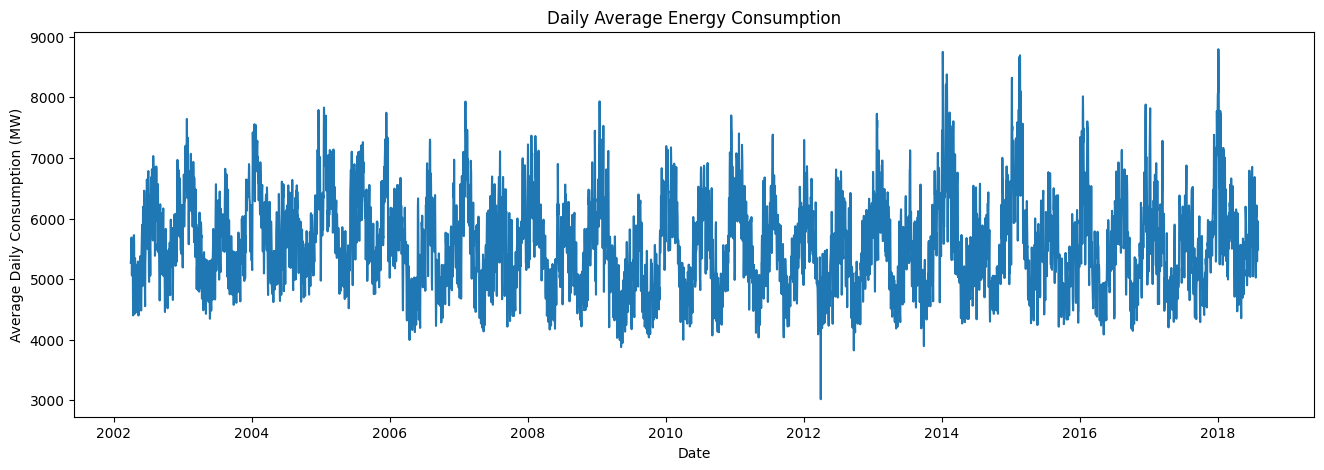

In [22]:
# Seting Datetime as the index temporarily for time-based resampling.
time_df = df.set_index('Datetime')

# Daily average consumption
daily_consumption = time_df[target].resample('D').mean()

# Monthly average consumption
monthly_consumption = time_df[target].resample('ME').mean()

# 24-hour rolling average of the original hourly data
rolling_24h = time_df[target].rolling(24).mean()

# Daily average plot
plt.figure(figsize=(16, 5))

plt.plot(
    daily_consumption.index,
    daily_consumption.values
)

plt.xlabel('Date')
plt.ylabel('Average Daily Consumption (MW)')
plt.title('Daily Average Energy Consumption')

plt.show()


raw hourly graph contains a lot of fluctuations. so we see Monthly or daily that will help

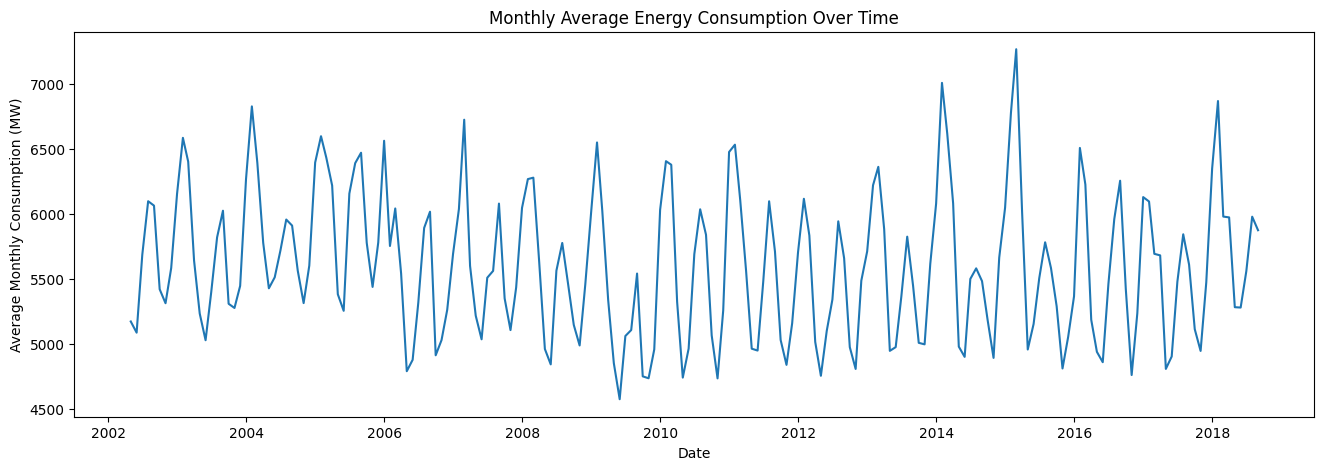

In [23]:

# Monthly average plot
plt.figure(figsize=(16, 5))

plt.plot(
    monthly_consumption.index,
    monthly_consumption.values
)

plt.xlabel('Date')
plt.ylabel('Average Monthly Consumption (MW)')
plt.title('Monthly Average Energy Consumption Over Time')

plt.show()

Daily and monthly aggregation makes the broader trend easier to see.

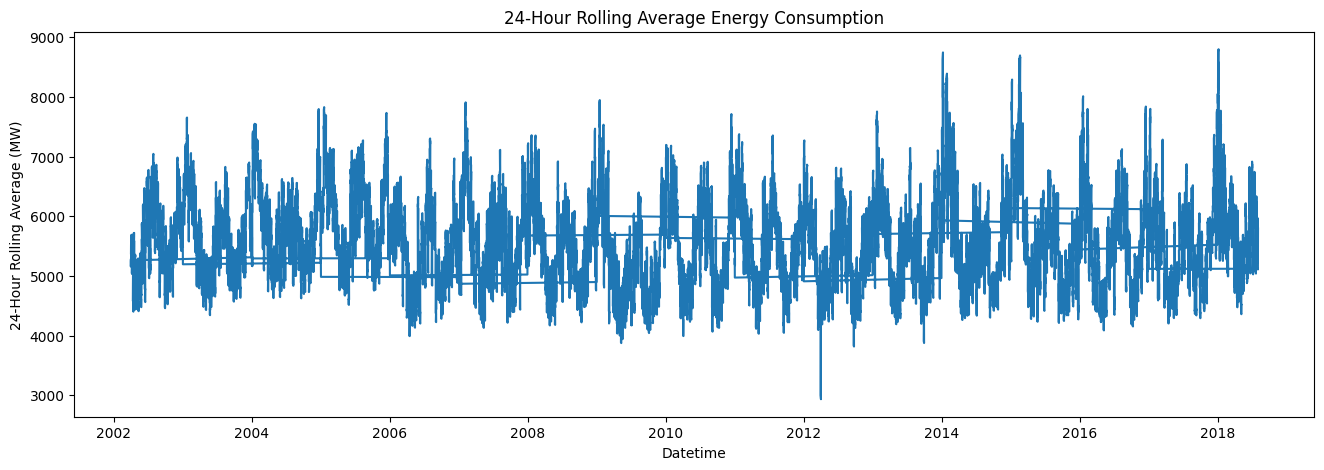

In [24]:

# Rolling 24-hour average
plt.figure(figsize=(16, 5))

plt.plot(
    rolling_24h.index,
    rolling_24h.values
)

plt.xlabel('Datetime')
plt.ylabel('24-Hour Rolling Average (MW)')
plt.title('24-Hour Rolling Average Energy Consumption')

plt.show()

Thee 24-hour rolling average smooths short-term fluctuations and helps us see the underlying movement.

**Final EDA Summary Table**

In [25]:
summary = {
    'Total Observations': len(df),
    'Total Columns': 2,
    'Start Date': df['Datetime'].min(),
    'End Date': df['Datetime'].max(),
    'Missing Datetime Values': df['Datetime'].isnull().sum(),
    'Missing Consumption Values': df[target].isnull().sum(),
    'Duplicate Rows': df.duplicated().sum(),
    'Duplicate Timestamps': df['Datetime'].duplicated().sum(),
    'Average Consumption (MW)': round(df[target].mean(), 2),
    'Minimum Consumption (MW)': round(df[target].min(), 2),
    'Maximum Consumption (MW)': round(df[target].max(), 2),
    'Highest Average Hour': int(hourly_avg.idxmax()),
    'Lowest Average Hour': int(hourly_avg.idxmin()),
    'Highest Average Month': int(monthly_avg.idxmax()),
    'Lowest Average Month': int(monthly_avg.idxmin()),
    'Highest Average Year': int(yearly_avg.idxmax()),
    'Lowest Average Year': int(yearly_avg.idxmin()),
    'Highest Average Season': season_avg.idxmax(),
    'Lowest Average Season': season_avg.idxmin(),
    'Holiday Records': int(df['IsHoliday'].sum()),
    'Potential Outliers': len(potential_outliers)
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=['EDA Metric', 'Result']
)

display(summary_df)

,EDA Metric,Result
0,Total Observations,143206
1,Total Columns,2
2,Start Date,2002-04-01 01:00:00
3,End Date,2018-08-03 00:00:00
4,Missing Datetime Values,0
5,Missing Consumption Values,0
6,Duplicate Rows,0
7,Duplicate Timestamps,4
8,Average Consumption (MW),5602.38
9,Minimum Consumption (MW),487


This gives us one clean table, which we can use for future.

**Final EDA Findings**

## 1. Dataset Overview

* The dataset contains **143,206 hourly observations** and **2 original columns**: `Datetime` and `PJMW_MW`.
* The data covers the period from **April 1, 2002 to August 3, 2018**.
* `Datetime` is stored as `datetime64[ns]` and `PJMW_MW` is stored as an integer.
* The target variable `PJMW_MW` represents hourly electricity consumption in **MW**.

## 2. Data Quality Findings

* There are **no missing values** in either `Datetime` or `PJMW_MW`.
* There are **no duplicate rows**.
* There are **4 duplicate timestamps**, which need to be investigated during the Data Cleaning stage.
* Most consecutive observations have a **1-hour difference**, but **30 records have a 2-hour difference**. This indicates some irregularities in the time sequence that should be handled before modeling.

## 3. Overall Consumption

* Average electricity consumption is **5,602.38 MW**.
* Median consumption is **5,530 MW**.
* Minimum recorded consumption is **487 MW**.
* Maximum recorded consumption is **9,594 MW**.
* The standard deviation is **979.14 MW**, showing noticeable variation in electricity consumption over time.

## 4. Hourly Consumption Pattern

* Electricity consumption varies considerably throughout the day.
* The **lowest average consumption occurs at 4:00 AM**, with approximately **4,672.54 MW**.
* The **highest average consumption occurs at 7:00 PM**, with approximately **6,199.29 MW**.
* Consumption generally increases from the early morning hours and reaches higher levels during the evening.

## 5. Weekly Pattern

* Average consumption is higher on weekdays than on weekends.
* **Weekday average:** approximately **5,754.35 MW**.
* **Weekend average:** approximately **5,221.86 MW**.
* Among individual days, **Wednesday** has the highest average consumption at approximately **5,802.37 MW**.
* **Sunday** has the lowest average consumption at approximately **5,149.64 MW**.

## 6. Monthly and Yearly Patterns

* Monthly consumption shows clear variation throughout the year.
* **January** has the highest average monthly consumption at approximately **6,447.67 MW**.
* **October** has the lowest average monthly consumption at approximately **4,997.64 MW**.
* Yearly averages also vary across the historical period.
* **2005** has the highest yearly average consumption at approximately **6,038.41 MW**.
* **2009** has the lowest yearly average consumption at approximately **5,290.56 MW**.

## 7. Seasonal Pattern

The seasonal analysis shows clear differences in electricity consumption:

* **Winter:** approximately **6,268.81 MW**
* **Summer:** approximately **5,734.21 MW**
* **Spring:** approximately **5,224.39 MW**
* **Autumn:** approximately **5,200.14 MW**

Therefore, **Winter has the highest average consumption**, while **Autumn has the lowest average consumption** in this dataset.

## 8. Summer vs Winter Daily Pattern

The daily consumption pattern changes depending on the season.

* **Summer average:** approximately **5,734.21 MW**
* **Winter average:** approximately **6,268.81 MW**
* Summer reaches its highest average hourly consumption around **5:00 PM**, at approximately **6,797.78 MW**.
* Winter reaches its highest average hourly consumption around **7:00 PM**, at approximately **6,863.18 MW**.

This shows that the relationship between hour of day and electricity consumption is not identical across seasons.

## 9. Holiday Analysis

* The dataset contains **4,320 holiday records** and **138,886 non-holiday records** based on the U.S. holiday calendar used in the analysis.
* Average non-holiday consumption is approximately **5,606.28 MW**.
* Average holiday consumption is approximately **5,476.77 MW**.
* The holiday average is therefore lower than the non-holiday average in this dataset.

Holiday behavior should be considered as a potential feature during model development because consumption patterns can differ from regular days.

## 10. Outlier Analysis

Using the IQR method:

* Q1 = **4,907 MW**
* Q3 = **6,252 MW**
* IQR = **1,345 MW**
* Lower limit = **2,889.5 MW**
* Upper limit = **8,269.5 MW**
* **703 observations** were identified as potential outliers.
* Potential outliers represent approximately **0.49%** of the dataset.

The highest recorded consumption is **9,594 MW**, observed on **February 20, 2015 at 8:00 AM**.

These observations should not be automatically removed because unusually high electricity demand may represent genuine peak-demand events. They should be investigated during the Data Cleaning stage.

## 11. Overall EDA Conclusion

The EDA shows that PJM hourly electricity consumption has strong **hourly, weekly, monthly, yearly, seasonal, and holiday-related patterns**.

Consumption is generally lower during the early morning hours and higher during the evening. Weekday consumption is higher than weekend consumption. The data also shows significant seasonal differences, with **winter having the highest average consumption**.

The dataset is mostly clean, with **no missing values and no duplicate rows**, but the **4 duplicate timestamps and 30 two-hour gaps** need to be investigated before model training.

The identified patterns will be useful for the next stages of the project, particularly **data cleaning, feature engineering, time-based train/test splitting, and forecasting model development**.


In [26]:
# ==========================================
# CREATING WORKING DATASET
# ==========================================

clean_df = df[['Datetime', 'PJMW_MW']].copy()

clean_df = clean_df.sort_values('Datetime').reset_index(drop=True)

print("Shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nDuplicate rows:",
      clean_df.duplicated().sum())

print("Duplicate timestamps:",
      clean_df['Datetime'].duplicated().sum())

Shape: (143206, 2)

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 4


In [27]:
# ==========================================
# INVESTIGATING DUPLICATE TIMESTAMPS
# ==========================================

duplicate_records = clean_df[
    clean_df['Datetime'].duplicated(keep=False)
].sort_values('Datetime')

print("Duplicate timestamp records:")

display(duplicate_records)

Duplicate timestamp records:


,Datetime,PJMW_MW
110327,2014-11-02 02:00:00,4571
110328,2014-11-02 02:00:00,4613
119063,2015-11-01 02:00:00,3927
119064,2015-11-01 02:00:00,3832
127967,2016-11-06 02:00:00,4114
127968,2016-11-06 02:00:00,4089
136703,2017-11-05 02:00:00,3984
136704,2017-11-05 02:00:00,4042


We already knew there were 4 duplicate timestamps.Before removing them, we need to see:

Which timestamps are duplicated?
Do they have the same consumption value?
Do they have different consumption values?

In [28]:
# ==========================================
# CHECKING DUPLICATE VALUE DIFFERENCE
# ==========================================

duplicate_summary = (
    duplicate_records
    .groupby('Datetime')['PJMW_MW']
    .agg(['count', 'min', 'max'])
    .reset_index()
)

display(duplicate_summary)

,Datetime,count,min,max
0,2014-11-02 02:00:00,2,4571,4613
1,2015-11-01 02:00:00,2,3832,3927
2,2016-11-06 02:00:00,2,4089,4114
3,2017-11-05 02:00:00,2,3984,4042


In [29]:
# ==========================================
# CHECKING DUPLICATE VALUE DIFFERENCE
# ==========================================

duplicate_summary = (
    duplicate_records
    .groupby('Datetime')['PJMW_MW']
    .agg(['count', 'min', 'max'])
    .reset_index()
)

display(duplicate_summary)

,Datetime,count,min,max
0,2014-11-02 02:00:00,2,4571,4613
1,2015-11-01 02:00:00,2,3832,3927
2,2016-11-06 02:00:00,2,4089,4114
3,2017-11-05 02:00:00,2,3984,4042


In [30]:
# ==========================================
# CHECKING SURROUNDING RECORDS
# ==========================================

duplicate_times = duplicate_records['Datetime'].unique()

for timestamp in duplicate_times:
    print("\n" + "=" * 60)
    print("Duplicate timestamp:", timestamp)

    nearby = clean_df[
        (clean_df['Datetime'] >= timestamp - pd.Timedelta(hours=2)) &
        (clean_df['Datetime'] <= timestamp + pd.Timedelta(hours=2))
    ]

    display(nearby)


Duplicate timestamp: 2014-11-02 02:00:00


,Datetime,PJMW_MW
110325,2014-11-02 00:00:00,4912
110326,2014-11-02 01:00:00,4805
110327,2014-11-02 02:00:00,4571
110328,2014-11-02 02:00:00,4613
110329,2014-11-02 03:00:00,4619
110330,2014-11-02 04:00:00,4615



Duplicate timestamp: 2015-11-01 02:00:00


,Datetime,PJMW_MW
119061,2015-11-01 00:00:00,4194
119062,2015-11-01 01:00:00,4014
119063,2015-11-01 02:00:00,3927
119064,2015-11-01 02:00:00,3832
119065,2015-11-01 03:00:00,3741
119066,2015-11-01 04:00:00,3763



Duplicate timestamp: 2016-11-06 02:00:00


,Datetime,PJMW_MW
127965,2016-11-06 00:00:00,4486
127966,2016-11-06 01:00:00,4258
127967,2016-11-06 02:00:00,4114
127968,2016-11-06 02:00:00,4089
127969,2016-11-06 03:00:00,4107
127970,2016-11-06 04:00:00,4138



Duplicate timestamp: 2017-11-05 02:00:00


,Datetime,PJMW_MW
136701,2017-11-05 00:00:00,4364
136702,2017-11-05 01:00:00,4190
136703,2017-11-05 02:00:00,3984
136704,2017-11-05 02:00:00,4042
136705,2017-11-05 03:00:00,3934
136706,2017-11-05 04:00:00,3924


keeping one observation per timestamp gives us a clean time index for forecasting.

In [31]:
# ==========================================
# FINDING MISSING HOURLY TIMESTAMPS
# ==========================================

# Geting unique timestamps first
unique_times = pd.Series(
    clean_df['Datetime'].drop_duplicates()
).sort_values()

full_range = pd.date_range(
    start=unique_times.min(),
    end=unique_times.max(),
    freq='h'
)

missing_times = full_range.difference(unique_times)

print("Missing hourly timestamps:", len(missing_times))

display(
    pd.DataFrame({
        'Missing_Datetime': missing_times
    }).head(50)
)

Missing hourly timestamps: 30


,Missing_Datetime
0,2002-04-07 03:00:00
1,2002-10-27 02:00:00
2,2003-04-06 03:00:00
3,2003-10-26 02:00:00
4,2004-04-04 03:00:00
5,2004-10-31 02:00:00
6,2005-04-03 03:00:00
7,2005-10-30 02:00:00
8,2006-04-02 03:00:00
9,2006-10-29 02:00:00


In [32]:
# ==========================================
# INVESTIGATING MISSING HOURS
# ==========================================

for timestamp in missing_times:
    print("\n" + "=" * 60)
    print("Missing timestamp:", timestamp)

    nearby = clean_df[
        (clean_df['Datetime'] >= timestamp - pd.Timedelta(hours=2)) &
        (clean_df['Datetime'] <= timestamp + pd.Timedelta(hours=2))
    ]

    display(nearby)


Missing timestamp: 2002-04-07 03:00:00


,Datetime,PJMW_MW
144,2002-04-07 01:00:00,5002
145,2002-04-07 02:00:00,4858
146,2002-04-07 04:00:00,4871
147,2002-04-07 05:00:00,4909



Missing timestamp: 2002-10-27 02:00:00


,Datetime,PJMW_MW
5014,2002-10-27 00:00:00,4583
5015,2002-10-27 01:00:00,4304
5016,2002-10-27 03:00:00,4014
5017,2002-10-27 04:00:00,4156



Missing timestamp: 2003-04-06 03:00:00


,Datetime,PJMW_MW
8878,2003-04-06 01:00:00,4461
8879,2003-04-06 02:00:00,4365
8880,2003-04-06 04:00:00,4376
8881,2003-04-06 05:00:00,4422


... (50 outputs left out)


Missing timestamp: 2017-03-12 03:00:00


,Datetime,PJMW_MW
130991,2017-03-12 01:00:00,5976
130992,2017-03-12 02:00:00,5913
130993,2017-03-12 04:00:00,5904
130994,2017-03-12 05:00:00,5959



Missing timestamp: 2018-03-11 03:00:00


,Datetime,PJMW_MW
139727,2018-03-11 01:00:00,5610
139728,2018-03-11 02:00:00,5533
139729,2018-03-11 04:00:00,5610
139730,2018-03-11 05:00:00,5606


Instead saying, There are 30 gaps.Im identifying which exact hours are missing.

In [33]:
# ==========================================
# INVESTIGATING OUTLIERS
# ==========================================

Q1 = clean_df['PJMW_MW'].quantile(0.25)
Q3 = clean_df['PJMW_MW'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = clean_df[
    (clean_df['PJMW_MW'] < lower_limit) |
    (clean_df['PJMW_MW'] > upper_limit)
]

print("Potential outliers:", len(outliers))

display(
    outliers.sort_values(
        'PJMW_MW',
        ascending=False
    ).head(20)
)

Potential outliers: 703


,Datetime,PJMW_MW
112974,2015-02-20 08:00:00,9594
112962,2015-02-19 20:00:00,9536
112973,2015-02-20 07:00:00,9512
112961,2015-02-19 19:00:00,9489
112975,2015-02-20 09:00:00,9481
112963,2015-02-19 21:00:00,9424
113070,2015-02-24 08:00:00,9366
103170,2014-01-07 20:00:00,9349
138186,2018-01-05 20:00:00,9342
138185,2018-01-05 19:00:00,9325


In [34]:
# ==========================================
# FINALLY CLEANING CHECK
# ==========================================

clean_df = clean_df.sort_values(
    'Datetime'
).reset_index(drop=True)

print("Final shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nDuplicate rows:",
      clean_df.duplicated().sum())

print("Duplicate timestamps:",
      clean_df['Datetime'].duplicated().sum())

print("\nDate range:")
print(clean_df['Datetime'].min())
print(clean_df['Datetime'].max())

Final shape: (143206, 2)

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 4

Date range:
2002-04-01 01:00:00
2018-08-03 00:00:00


im not deleting the outliers because Electricity demand can genuinely become very high or very low.For example, your maximum is:

9,594 MW on February 20, 2015 at 8:00 AM. That could be a genuine peak-demand observation.

In [35]:
# ==========================================
# FINAL CLEANING CHECK
# ==========================================

print("Final dataset shape:", clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nDuplicate rows:",
      clean_df.duplicated().sum())

print("Duplicate timestamps:",
      clean_df['Datetime'].duplicated().sum())

print("\nDate range:")
print(clean_df['Datetime'].min())
print(clean_df['Datetime'].max())

Final dataset shape: (143206, 2)

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 4

Date range:
2002-04-01 01:00:00
2018-08-03 00:00:00


**Feature Engineering**

In [36]:
# ==========================================
# TIME FEATURES
# ==========================================

clean_df['Hour'] = clean_df['Datetime'].dt.hour
clean_df['DayOfWeek'] = clean_df['Datetime'].dt.dayofweek
clean_df['Month'] = clean_df['Datetime'].dt.month
clean_df['Year'] = clean_df['Datetime'].dt.year

clean_df['IsWeekend'] = (
    clean_df['DayOfWeek'] >= 5
).astype(int)

clean_df['IsHoliday'] = clean_df['Datetime'].dt.date.apply(
    lambda x: x in us_holidays
).astype(int)

display(clean_df.head())

,Datetime,PJMW_MW,Hour,DayOfWeek,Month,Year,IsWeekend,IsHoliday
0,2002-04-01 01:00:00,4374,1,0,4,2002,0,0
1,2002-04-01 02:00:00,4306,2,0,4,2002,0,0
2,2002-04-01 03:00:00,4322,3,0,4,2002,0,0
3,2002-04-01 04:00:00,4359,4,0,4,2002,0,0
4,2002-04-01 05:00:00,4436,5,0,4,2002,0,0


In [37]:
# ==========================================
# LAG FEATURES
# ==========================================

clean_df['Lag_1'] = clean_df['PJMW_MW'].shift(1)

clean_df['Lag_24'] = clean_df['PJMW_MW'].shift(24)

clean_df['Lag_168'] = clean_df['PJMW_MW'].shift(168)

display(clean_df.head(30))

,Datetime,PJMW_MW,Hour,DayOfWeek,Month,Year,IsWeekend,IsHoliday,Lag_1,Lag_24,Lag_168
0,2002-04-01 01:00:00,4374,1,0,4,2002,0,0,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306,2,0,4,2002,0,0,4374.0,NaN,NaN
2,2002-04-01 03:00:00,4322,3,0,4,2002,0,0,4306.0,NaN,NaN
3,2002-04-01 04:00:00,4359,4,0,4,2002,0,0,4322.0,NaN,NaN
4,2002-04-01 05:00:00,4436,5,0,4,2002,0,0,4359.0,NaN,NaN
5,2002-04-01 06:00:00,4723,6,0,4,2002,0,0,4436.0,NaN,NaN
6,2002-04-01 07:00:00,5180,7,0,4,2002,0,0,4723.0,NaN,NaN
7,2002-04-01 08:00:00,5482,8,0,4,2002,0,0,5180.0,NaN,NaN
8,2002-04-01 09:00:00,5616,9,0,4,2002,0,0,5482.0,NaN,NaN
9,2002-04-01 10:00:00,5722,10,0,4,2002,0,0,5616.0,NaN,NaN


* Lag_1 : Previous hour's consumption.

* Lag_24 : Consumption from the same hour yesterday.

* Lag_168 : Consumption from the same hour one week ago.
* If i want to predict: Monday 7 PM, model can look like
Sunday 7 PM → Lag_24,Previous Monday 7 PM → Lag_168
* This is extremely useful for hourly electricity forecasting.

In [38]:
# ==========================================
# ROLLING FEATURES
# ==========================================

clean_df['RollingMean_24'] = (
    clean_df['PJMW_MW']
    .shift(1)
    .rolling(24)
    .mean()
)

clean_df['RollingMean_168'] = (
    clean_df['PJMW_MW']
    .shift(1)
    .rolling(168)
    .mean()
)

display(clean_df.head(30))

,Datetime,PJMW_MW,Hour,DayOfWeek,Month,Year,IsWeekend,IsHoliday,Lag_1,Lag_24,Lag_168,RollingMean_24,RollingMean_168
0,2002-04-01 01:00:00,4374,1,0,4,2002,0,0,NaN,NaN,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306,2,0,4,2002,0,0,4374.0,NaN,NaN,NaN,NaN
2,2002-04-01 03:00:00,4322,3,0,4,2002,0,0,4306.0,NaN,NaN,NaN,NaN
3,2002-04-01 04:00:00,4359,4,0,4,2002,0,0,4322.0,NaN,NaN,NaN,NaN
4,2002-04-01 05:00:00,4436,5,0,4,2002,0,0,4359.0,NaN,NaN,NaN,NaN
5,2002-04-01 06:00:00,4723,6,0,4,2002,0,0,4436.0,NaN,NaN,NaN,NaN
6,2002-04-01 07:00:00,5180,7,0,4,2002,0,0,4723.0,NaN,NaN,NaN,NaN
7,2002-04-01 08:00:00,5482,8,0,4,2002,0,0,5180.0,NaN,NaN,NaN,NaN
8,2002-04-01 09:00:00,5616,9,0,4,2002,0,0,5482.0,NaN,NaN,NaN,NaN
9,2002-04-01 10:00:00,5722,10,0,4,2002,0,0,5616.0,NaN,NaN,NaN,NaN


We don't want the current target value to be included in its own prediction features.
* previous 24-hour average
* previous 7-day average
So, Previous observations → features → current consumption
not using like these Current consumption → features → current consumption
This helps avoid data leakage.

**HANDLE NaN CREATED BY LAG FEATURES**




In [39]:
# ==========================================
# CHECKING FEATURE NaN VALUES
# ==========================================

print(clean_df.isnull().sum())

Datetime             0
PJMW_MW              0
Hour                 0
DayOfWeek            0
Month                0
Year                 0
IsWeekend            0
IsHoliday            0
Lag_1                1
Lag_24              24
Lag_168            168
RollingMean_24      24
RollingMean_168    168
dtype: int64


In [40]:
# ==========================================
# REMOVING INITIAL NaN ROWS
# ==========================================

clean_df = clean_df.dropna().reset_index(drop=True)

print("Shape:", clean_df.shape)

print("\nRemaining missing values:")
print(clean_df.isnull().sum())

Shape: (143038, 13)

Remaining missing values:
Datetime           0
PJMW_MW            0
Hour               0
DayOfWeek          0
Month              0
Year               0
IsWeekend          0
IsHoliday          0
Lag_1              0
Lag_24             0
Lag_168            0
RollingMean_24     0
RollingMean_168    0
dtype: int64


**CORRELATION HEATMAP**

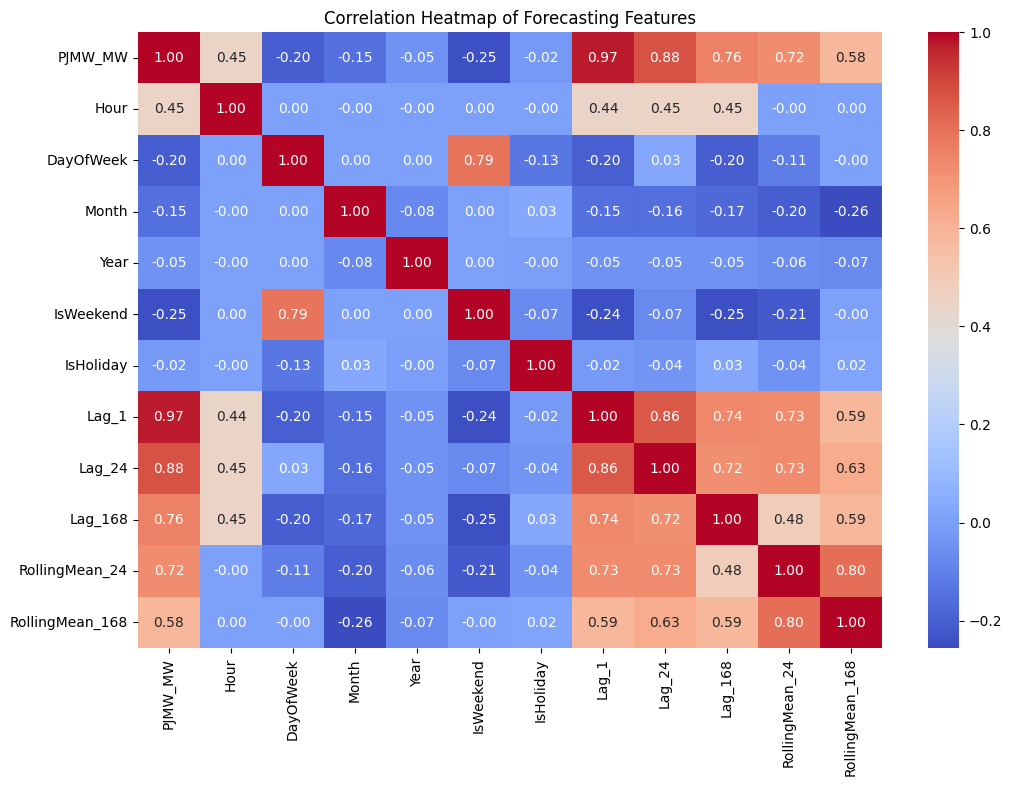

In [41]:
# ==========================================
# CORRELATION HEATMAP
# ==========================================

import seaborn as sns

correlation_columns = [
    'PJMW_MW',
    'Hour',
    'DayOfWeek',
    'Month',
    'Year',
    'IsWeekend',
    'IsHoliday',
    'Lag_1',
    'Lag_24',
    'Lag_168',
    'RollingMean_24',
    'RollingMean_168'
]

corr = clean_df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap of Forecasting Features')
plt.show()

Know we have actual numerical forecasting features.

In [42]:
# ==========================================
# DEFINING TEST PERIOD
# ==========================================

last_date = clean_df['Datetime'].max()

test_start = last_date - pd.DateOffset(years=1)

print("Last date:", last_date)
print("Test starts:", test_start)

Last date: 2018-08-03 00:00:00
Test starts: 2017-08-03 00:00:00


**CHRONOLOGICAL TRAIN/TEST SPLIT**

In [43]:
# ==========================================
# TRAINING TEST SPLIT
# ==========================================

train_df = clean_df[
    clean_df['Datetime'] < test_start
].copy()

test_df = clean_df[
    clean_df['Datetime'] >= test_start
].copy()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining period:")
print(train_df['Datetime'].min())
print(train_df['Datetime'].max())

print("\nTesting period:")
print(test_df['Datetime'].min())
print(test_df['Datetime'].max())

Training shape: (134277, 13)
Testing shape: (8761, 13)

Training period:
2002-04-08 02:00:00
2017-08-02 23:00:00

Testing period:
2017-08-03 00:00:00
2018-08-03 00:00:00


here we are not randomly doing train_test_split()?, Because this is forecasting. We cannot train using future data and then pretend to predict the past.

In [92]:
test_start = df["Datetime"].max() - pd.Timedelta(days=365)

train_xgb = xgb_df[
    xgb_df["Datetime"] < test_start
].copy()

test_xgb = xgb_df[
    xgb_df["Datetime"] >= test_start
].copy()

X_train = train_xgb[features]
y_train = train_xgb[target]

X_test = test_xgb[features]
y_test = test_xgb[target]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (134277, 14)
X_test : (8761, 14)


# **Model Building Strategy — Time-Series First**

This project is an **energy-demand forecasting** problem, so the production model must come from the **time-series forecasting family**.

We still train ML, PCA and LSTM models because they are useful benchmarks and demonstrate alternative approaches. However, a lower MAE from XGBoost or another ML model will **not automatically make it the production model**.

### Model families
- **Baseline:** Seasonal Naive
- **Classical time-series:** Holt-Winters, ARIMA, SARIMA/SARIMAX
- **Machine learning benchmarks:** Linear Regression, Decision Tree, Random Forest, Gradient Boosting, XGBoost
- **Dimensionality reduction benchmark:** PCA + Linear Regression
- **Deep learning benchmark:** LSTM

### Production selection rule
The final production model is selected **only from the classical time-series models** using chronological validation. The other models remain in the comparison table so the project can explain what was tested and why the final forecasting approach was chosen.

# **Advanced Time-Series Diagnostics**

The EDA above explains the business patterns. This section moves from descriptive analysis to forecasting diagnostics.

A forecasting model needs to answer three questions:

- Is the series stationary or does it contain trend/seasonality?
- What lag relationships are visible?
- What seasonal structure should a time-series model represent?


In [44]:
# ============================================================
# STATIONARITY TEST — AUGMENTED DICKEY-FULLER
# ============================================================

from statsmodels.tsa.stattools import adfuller

daily_series = (
    clean_df.set_index("Datetime")["PJMW_MW"]
    .resample("D")
    .mean()
    .dropna()
)

adf_result = adfuller(daily_series)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))

if adf_result[1] < 0.05:
    print("Conclusion: Reject H0. The daily series is stationary at the 5% level.")
else:
    print("Conclusion: Fail to reject H0. Differencing or other transformation may be needed.")


ADF Statistic: -7.2718
p-value: 0.0
Conclusion: Reject H0. The daily series is stationary at the 5% level.


Differenced ADF Statistic: -14.3886
Differenced p-value: 0.0


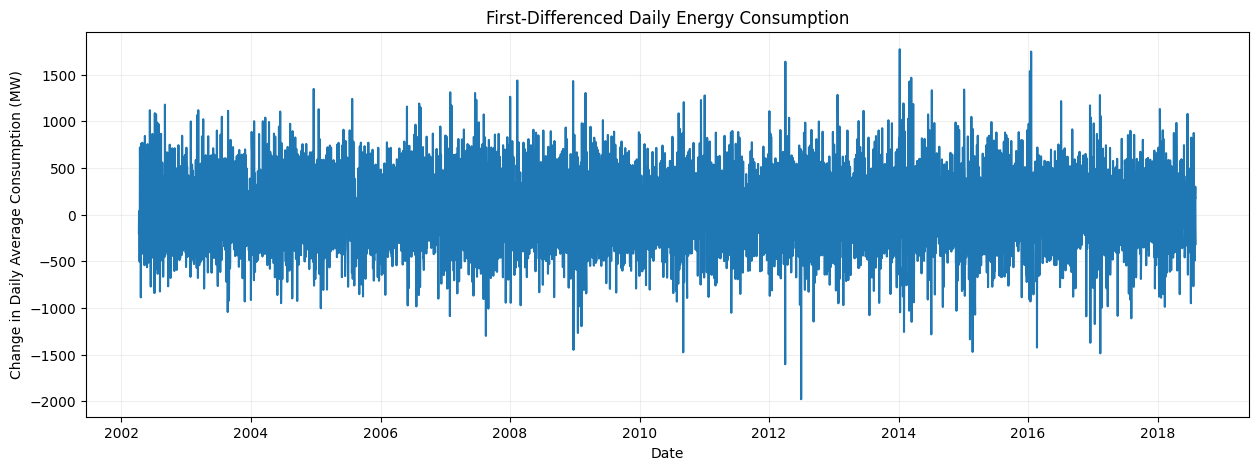

In [45]:
# ============================================================
# FIRST DIFFERENCE + STATIONARITY CHECK
# ============================================================

daily_diff = daily_series.diff().dropna()

adf_diff = adfuller(daily_diff)

print("Differenced ADF Statistic:", round(adf_diff[0], 4))
print("Differenced p-value:", round(adf_diff[1], 6))

plt.figure(figsize=(15, 5))
plt.plot(daily_diff.index, daily_diff.values)
plt.title("First-Differenced Daily Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Change in Daily Average Consumption (MW)")
plt.grid(alpha=0.2)
plt.show()


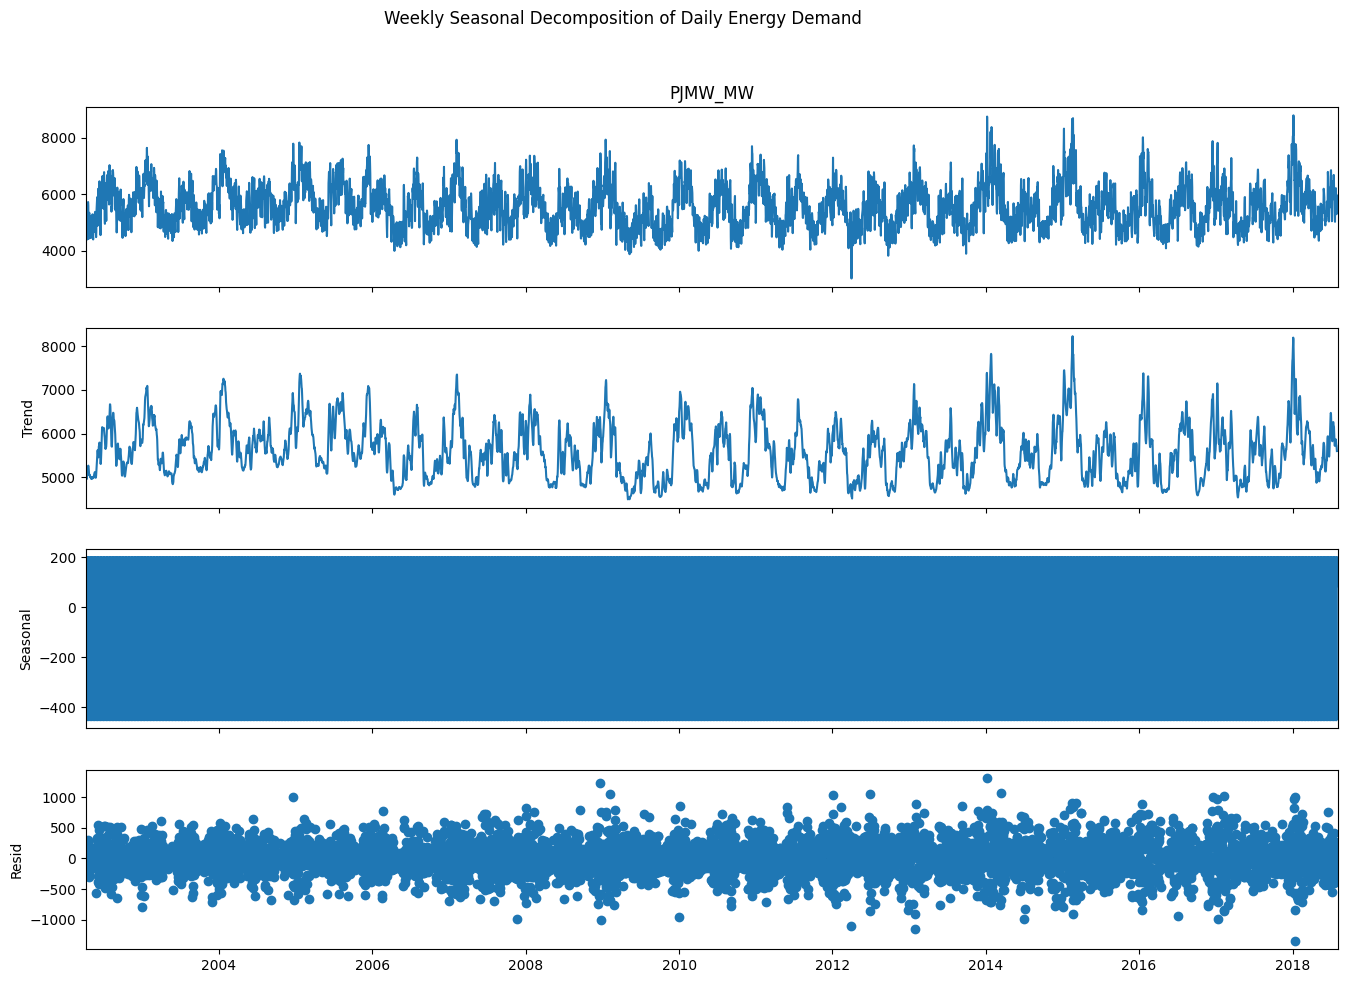

In [46]:
# ============================================================
# SEASONAL DECOMPOSITION
# ============================================================

from statsmodels.tsa.seasonal import seasonal_decompose

# Weekly seasonality is appropriate for daily electricity demand:
# 7 days = one weekly cycle.
decomposition = seasonal_decompose(
    daily_series,
    model="additive",
    period=7
)

fig = decomposition.plot()
fig.set_size_inches(15, 10)
plt.suptitle("Weekly Seasonal Decomposition of Daily Energy Demand", y=1.02)
plt.show()


### Reading the decomposition

The decomposition separates the observed series into:

- **Trend:** long-term movement in demand
- **Seasonal:** repeating weekly structure
- **Residual:** variation not explained by the trend/seasonal components

This helps justify why a forecasting model should account for both temporal dependence and seasonality.

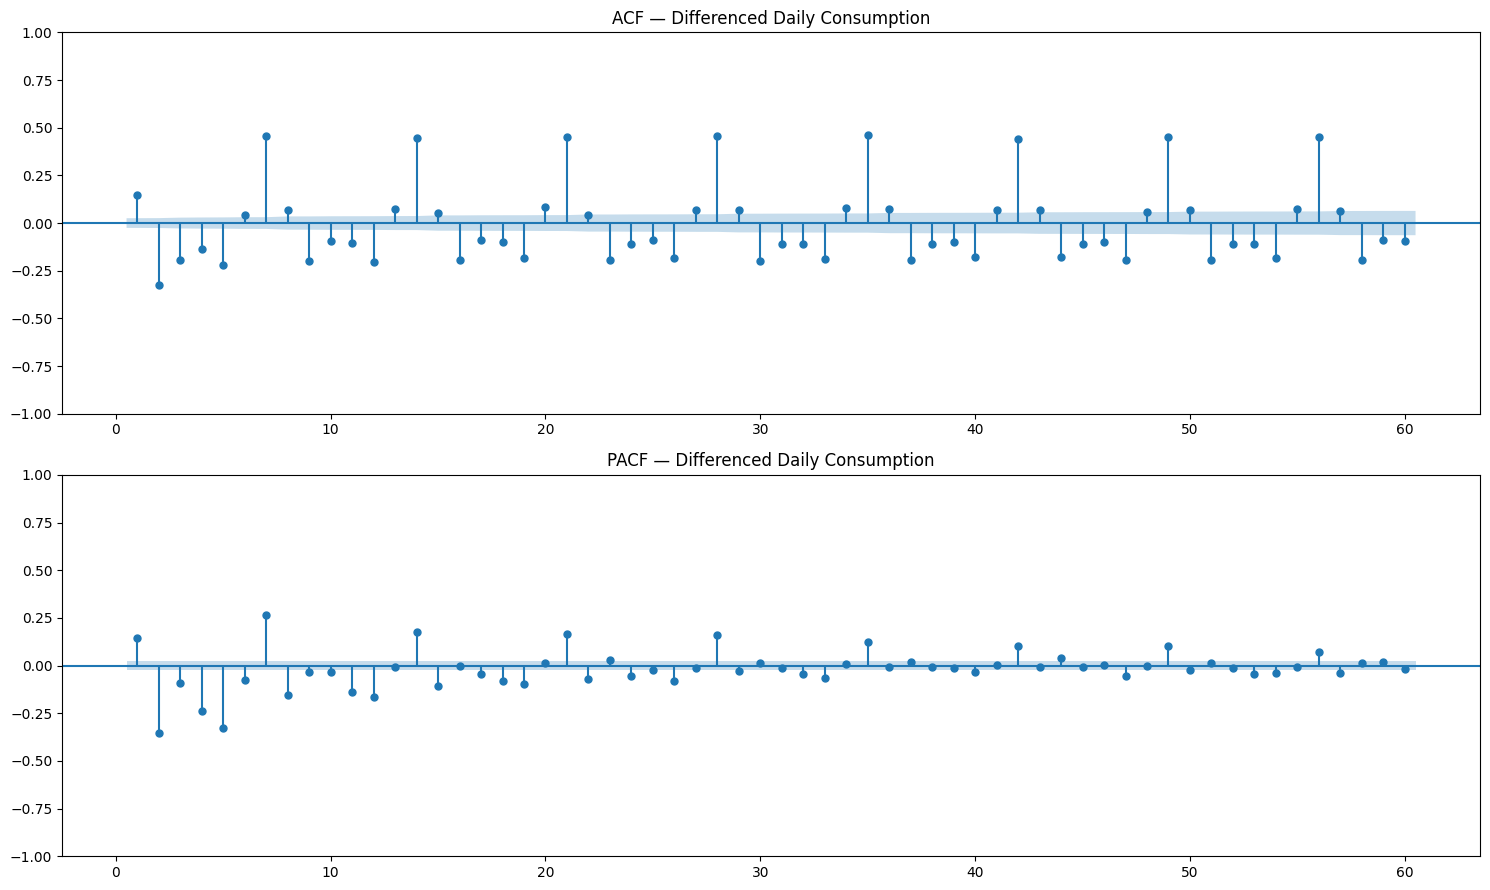

In [47]:
# ============================================================
# ACF AND PACF — DAILY DIFFERENCED SERIES
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

plot_acf(
    daily_diff,
    lags=60,
    ax=axes[0],
    zero=False
)
axes[0].set_title("ACF — Differenced Daily Consumption")

plot_pacf(
    daily_diff,
    lags=60,
    ax=axes[1],
    zero=False,
    method="ywm"
)
axes[1].set_title("PACF — Differenced Daily Consumption")

plt.tight_layout()
plt.show()


### Why ACF and PACF matter

**ACF** shows how current consumption is related to previous observations across different lags.

**PACF** shows the direct relationship at a lag after accounting for shorter lags.

These plots are not used to blindly choose an ARIMA order. They provide evidence for selecting and discussing candidate autoregressive and moving-average structures.

# **Model Building — Chronological and Explainable**

We now build several families of models rather than relying on one algorithm:

### 1. Baseline
Seasonal-naive forecast using the same hour from the previous day.

### 2. Classical time-series models
- Holt-Winters / Exponential Smoothing
- ARIMA
- SARIMA / SARIMAX

### 3. Supervised machine learning
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost

### 4. Dimensionality reduction
- PCA + Linear Regression

### 5. Deep learning
- LSTM

The purpose is not to use advanced algorithms just to make the project look advanced. Each model answers a different modeling question, and the final choice is made from chronological validation results.

In [48]:
# ============================================================
# MODELING DATASET AND EVALUATION WINDOWS
# ============================================================

target = "PJMW_MW"

# The project requirement keeps the last year as the final chronological
# test period.
last_timestamp = clean_df["Datetime"].max()
test_start = last_timestamp - pd.DateOffset(years=1)

train_df = clean_df[clean_df["Datetime"] < test_start].copy()
test_df = clean_df[clean_df["Datetime"] >= test_start].copy()

print("Training period:", train_df["Datetime"].min(), "to", train_df["Datetime"].max())
print("Final test period:", test_df["Datetime"].min(), "to", test_df["Datetime"].max())
print("Training rows:", len(train_df))
print("Final test rows:", len(test_df))

# For expensive classical/DL models we use a clearly defined 30-day
# validation window inside the historical training period.
validation_end = train_df["Datetime"].max()
validation_start = validation_end - pd.Timedelta(days=30) + pd.Timedelta(hours=1)

model_train = train_df[train_df["Datetime"] < validation_start].copy()
model_valid = train_df[train_df["Datetime"] >= validation_start].copy()

print("\nModel-development validation window:")
print(validation_start, "to", validation_end)
print("Validation rows:", len(model_valid))


Training period: 2002-04-08 02:00:00 to 2017-08-02 23:00:00
Final test period: 2017-08-03 00:00:00 to 2018-08-03 00:00:00
Training rows: 134277
Final test rows: 8761

Model-development validation window:
2017-07-04 00:00:00 to 2017-08-02 23:00:00
Validation rows: 720


### Why use a 30-day model-development window?

The last year remains untouched as the **final test period** required by the project.

Within the earlier training history, a 30-day chronological validation window gives us a realistic forecasting experiment while keeping computational cost reasonable for ARIMA/SARIMA/LSTM.

After selecting the approach, we evaluate the final model on the untouched last-year test period.

In [49]:
# ============================================================
# METRIC FUNCTIONS
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

def mape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    mask = actual != 0
    return np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100

def evaluate_forecast(actual, predicted, model_name, period_name):
    return {
        "Model": model_name,
        "Period": period_name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAPE (%)": mape(actual, predicted)
    }


## **1. Seasonal Naive Baseline**

Before using ML or deep learning, we need a simple benchmark.

For hourly electricity consumption, yesterday's value at the same hour is a meaningful baseline:

> Forecast at time *t* = observed consumption at *t − 24 hours*

A sophisticated model should beat this baseline consistently.

In [50]:
# ============================================================
# SEASONAL NAIVE — 24-HOUR SEASONALITY
# ============================================================

valid_naive = model_valid.copy()
valid_naive["Prediction"] = valid_naive["PJMW_MW"].shift(0)

# Use the corresponding previous-day value from the original clean series.
history_lookup = clean_df.set_index("Datetime")["PJMW_MW"]

valid_naive["Prediction"] = [
    history_lookup.get(ts - pd.Timedelta(hours=24), np.nan)
    for ts in valid_naive["Datetime"]
]

valid_naive = valid_naive.dropna(subset=["Prediction"])

naive_result = evaluate_forecast(
    valid_naive["PJMW_MW"],
    valid_naive["Prediction"],
    "Seasonal Naive (24h)",
    "30-day validation"
)

print(naive_result)


{'Model': 'Seasonal Naive (24h)', 'Period': '30-day validation', 'MAE': 429.025, 'RMSE': 536.0506350461059, 'MAPE (%)': np.float64(7.454927322442799)}


## **2. Holt-Winters Exponential Smoothing**

Holt-Winters explicitly models level, trend, and seasonality.

For hourly electricity demand, a 24-hour seasonal period represents the daily cycle. We test a damped trend so that long-term trend growth does not grow unrealistically during recursive forecasting.

In [51]:
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# HOLT-WINTERS — 24-HOUR SEASONALITY
# ============================================================

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Use a recent training window for the classical hourly model.
hw_train = model_train.set_index("Datetime")["PJMW_MW"].tail(180 * 24).asfreq('H').interpolate(method='time')

hw_model = ExponentialSmoothing(
    hw_train,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=24,
    initialization_method="estimated"
).fit(optimized=True)

hw_pred = hw_model.forecast(len(model_valid))

hw_result = evaluate_forecast(
    model_valid["PJMW_MW"].values,
    hw_pred.values,
    "Holt-Winters",
    "30-day validation"
)

print(hw_result)

{'Model': 'Holt-Winters', 'Period': '30-day validation', 'MAE': 495.94584228731685, 'RMSE': 647.3978290528723, 'MAPE (%)': np.float64(8.821207226292332)}


## **3. ARIMA**

ARIMA models the target as a combination of autoregression, differencing, and moving-average behavior.

Candidate order:

- **p = 2:** recent autoregressive structure
- **d = 1:** remove non-stationary level/trend
- **q = 2:** moving-average error structure

The model is trained only on observations available before the validation window.

In [52]:
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# ARIMA(2,1,2)
# ============================================================

from statsmodels.tsa.arima.model import ARIMA

arima_train = model_train.set_index("Datetime")["PJMW_MW"].tail(180 * 24).asfreq('H')

arima_model = ARIMA(
    arima_train,
    order=(2, 1, 2)
).fit()

arima_pred = arima_model.forecast(len(model_valid))

arima_result = evaluate_forecast(
    model_valid["PJMW_MW"].values,
    arima_pred.values,
    "ARIMA(2,1,2)",
    "30-day validation"
)

print(arima_result)

{'Model': 'ARIMA(2,1,2)', 'Period': '30-day validation', 'MAE': 920.5376869721857, 'RMSE': 1083.1322672330693, 'MAPE (%)': np.float64(16.56339979019991)}


## **4. SARIMA / SARIMAX**

SARIMA extends ARIMA by explicitly modeling seasonal behavior.

Here the seasonal period is **24 hours**, representing the daily electricity-demand cycle.

We use:

- non-seasonal order `(1,1,1)`
- seasonal order `(1,1,1,24)`

This is closer to the forecasting nature of the problem than treating every hour as an independent tabular row.

In [53]:
# ============================================================
# SARIMAX — DAILY HOURLY SEASONALITY
# ============================================================

from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_train = model_train.set_index("Datetime")["PJMW_MW"].tail(180 * 24).asfreq('H')

sarima_model = SARIMAX(
    sarima_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_pred = sarima_model.forecast(len(model_valid))

sarima_result = evaluate_forecast(
    model_valid["PJMW_MW"].values,
    sarima_pred.values,
    "SARIMA(1,1,1)x(1,1,1,24)",
    "30-day validation"
)

print(sarima_result)

{'Model': 'SARIMA(1,1,1)x(1,1,1,24)', 'Period': '30-day validation', 'MAE': 947.7006861822518, 'RMSE': 1169.2234341319145, 'MAPE (%)': np.float64(17.562861383704504)}


In [54]:
# ============================================================
# CLASSICAL TIME-SERIES PREDICTION COMPARISON
# ============================================================

classical_results = pd.DataFrame([
    naive_result,
    hw_result,
    arima_result,
    sarima_result
])

display(classical_results.sort_values("MAE").reset_index(drop=True))


,Model,Period,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861


### Inspecting classical-model forecasts

A metric table alone is not enough. We also inspect whether the predicted curve follows the actual daily and hourly shape.

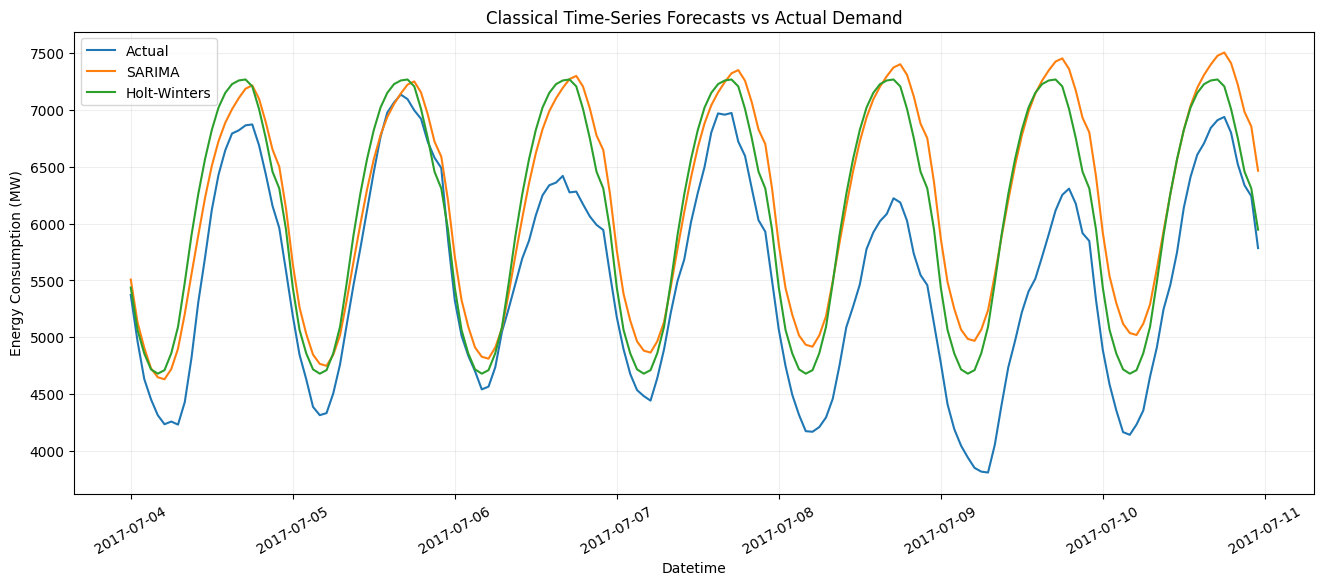

In [55]:
# ============================================================
# CLASSICAL MODEL — ACTUAL VS PREDICTED
# ============================================================

plot_n = min(24 * 7, len(model_valid))

plt.figure(figsize=(16, 6))
plt.plot(
    model_valid["Datetime"].iloc[:plot_n],
    model_valid["PJMW_MW"].iloc[:plot_n],
    label="Actual"
)
plt.plot(
    model_valid["Datetime"].iloc[:plot_n],
    sarima_pred.iloc[:plot_n],
    label="SARIMA"
)
plt.plot(
    model_valid["Datetime"].iloc[:plot_n],
    hw_pred.iloc[:plot_n],
    label="Holt-Winters"
)

plt.title("Classical Time-Series Forecasts vs Actual Demand")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.show()


# **Machine Learning Feature Engineering — Deeper Version**

Tree and linear models do not automatically understand temporal order. We therefore convert the time series into supervised learning examples.

The feature groups are:

**Calendar:** hour, weekday, month, day-of-year, weekend, holiday

**Lagged demand:** 1 hour, 24 hours, 48 hours, 168 hours

**Rolling demand:** previous 24-hour mean/std and previous 7-day mean/std

**Cyclical encoding:** sine/cosine transforms for hour and day-of-week

All lag and rolling values use only observations strictly before the target timestamp.

In [56]:
# ============================================================
# ADVANCED SUPERVISED FEATURES
# ============================================================

ml_df = clean_df[["Datetime", "PJMW_MW"]].copy()

ml_df["Hour"] = ml_df["Datetime"].dt.hour
ml_df["DayOfWeek"] = ml_df["Datetime"].dt.dayofweek
ml_df["DayOfYear"] = ml_df["Datetime"].dt.dayofyear
ml_df["Month"] = ml_df["Datetime"].dt.month
ml_df["Year"] = ml_df["Datetime"].dt.year
ml_df["IsWeekend"] = (ml_df["DayOfWeek"] >= 5).astype(int)
ml_df["IsHoliday"] = ml_df["Datetime"].dt.date.apply(
    lambda x: x in us_holidays
).astype(int)

# Cyclical time encoding preserves circular relationships:
# 23:00 is close to 00:00, unlike ordinary integer encoding.
ml_df["Hour_sin"] = np.sin(2 * np.pi * ml_df["Hour"] / 24)
ml_df["Hour_cos"] = np.cos(2 * np.pi * ml_df["Hour"] / 24)

ml_df["Dow_sin"] = np.sin(2 * np.pi * ml_df["DayOfWeek"] / 7)
ml_df["Dow_cos"] = np.cos(2 * np.pi * ml_df["DayOfWeek"] / 7)

ml_df["Lag_1"] = ml_df["PJMW_MW"].shift(1)
ml_df["Lag_24"] = ml_df["PJMW_MW"].shift(24)
ml_df["Lag_48"] = ml_df["PJMW_MW"].shift(48)
ml_df["Lag_168"] = ml_df["PJMW_MW"].shift(168)

past_target = ml_df["PJMW_MW"].shift(1)

ml_df["RollingMean_24"] = past_target.rolling(24).mean()
ml_df["RollingStd_24"] = past_target.rolling(24).std()
ml_df["RollingMean_168"] = past_target.rolling(168).mean()
ml_df["RollingStd_168"] = past_target.rolling(168).std()

ml_df = ml_df.dropna().reset_index(drop=True)

ml_features = [
    "Hour", "DayOfWeek", "DayOfYear", "Month", "Year",
    "IsWeekend", "IsHoliday",
    "Hour_sin", "Hour_cos", "Dow_sin", "Dow_cos",
    "Lag_1", "Lag_24", "Lag_48", "Lag_168",
    "RollingMean_24", "RollingStd_24",
    "RollingMean_168", "RollingStd_168"
]

print("Number of ML features:", len(ml_features))
display(ml_df[["Datetime"] + ml_features + ["PJMW_MW"]].head())


Number of ML features: 19


,Datetime,Hour,DayOfWeek,DayOfYear,Month,Year,IsWeekend,IsHoliday,Hour_sin,Hour_cos,...,Dow_cos,Lag_1,Lag_24,Lag_48,Lag_168,RollingMean_24,RollingStd_24,RollingMean_168,RollingStd_168,PJMW_MW
0,2002-04-15 02:00:00,2,0,105,4,2002,0,0,0.500000,8.660254e-01,...,1.0,4134.0,3780.0,4106.0,4532.0,4408.208333,448.946397,4976.559524,548.125152,4030
1,2002-04-15 03:00:00,3,0,105,4,2002,0,0,0.707107,7.071068e-01,...,1.0,4030.0,3750.0,4015.0,4481.0,4418.625000,436.463437,4973.571429,551.918370,3983
2,2002-04-15 04:00:00,4,0,105,4,2002,0,0,0.866025,5.000000e-01,...,1.0,3983.0,3727.0,3934.0,4527.0,4428.333333,423.338457,4970.607143,555.902719,3993
3,2002-04-15 05:00:00,5,0,105,4,2002,0,0,0.965926,2.588190e-01,...,1.0,3993.0,3704.0,3928.0,4640.0,4439.416667,407.359143,4967.428571,559.966205,4072
4,2002-04-15 06:00:00,6,0,105,4,2002,0,0,1.000000,6.123234e-17,...,1.0,4072.0,3770.0,4080.0,4940.0,4454.750000,384.773705,4964.047619,563.657547,4382


In [57]:
# ============================================================
# CHRONOLOGICAL ML SPLIT
# ============================================================

ml_train = ml_df[ml_df["Datetime"] < test_start].copy()
ml_test = ml_df[ml_df["Datetime"] >= test_start].copy()

X_train = ml_train[ml_features]
y_train = ml_train[target]

X_test = ml_test[ml_features]
y_test = ml_test[target]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (134109, 19)
X_test : (8761, 19)
y_train: (134109,)
y_test : (8761,)


## **5. Linear Regression**

Linear Regression provides an interpretable benchmark.

If its performance is much worse than nonlinear models, that indicates the relationship between time features, lagged demand, and consumption is not adequately represented by a simple linear function.

In [58]:
# ============================================================
# LINEAR REGRESSION
# ============================================================

from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_final = evaluate_forecast(
    y_test,
    linear_pred,
    "Linear Regression",
    "Final last-year test"
)

print(linear_final)


{'Model': 'Linear Regression', 'Period': 'Final last-year test', 'MAE': 128.34579322860054, 'RMSE': 164.0125887288403, 'MAPE (%)': np.float64(2.2147946184832112)}


## **6. Decision Tree Regressor**

A Decision Tree can model nonlinear rules such as:

- high demand during certain hours,
- different behavior on weekends,
- interactions between hour and lag values.

We use a depth limit to control overfitting.

In [59]:
# ============================================================
# DECISION TREE
# ============================================================

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=20,
    min_samples_leaf=3,
    random_state=42
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

dt_final = evaluate_forecast(
    y_test,
    dt_pred,
    "Decision Tree",
    "Final last-year test"
)

print(dt_final)


{'Model': 'Decision Tree', 'Period': 'Final last-year test', 'MAE': 75.20782875600993, 'RMSE': 101.23649174810677, 'MAPE (%)': np.float64(1.3105937352541355)}


## **7. Random Forest**

Random Forest combines many decision trees trained on different samples/features.

Compared with a single tree, the ensemble generally reduces variance and can capture nonlinear relationships between historical demand and calendar variables.

In [60]:
# ============================================================
# RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=250,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_final = evaluate_forecast(
    y_test,
    rf_pred,
    "Random Forest",
    "Final last-year test"
)

print(rf_final)


{'Model': 'Random Forest', 'Period': 'Final last-year test', 'MAE': 80.16796342376614, 'RMSE': 108.73751380756848, 'MAPE (%)': np.float64(1.3701129590632855)}


## **8. Gradient Boosting**

Gradient Boosting builds trees sequentially. Each new tree attempts to reduce the errors made by the previous ensemble.

This provides a useful comparison with Random Forest because the two ensembles learn nonlinear patterns differently.

In [61]:
# ============================================================
# GRADIENT BOOSTING
# ============================================================

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

gb_final = evaluate_forecast(
    y_test,
    gb_pred,
    "Gradient Boosting",
    "Final last-year test"
)

print(gb_final)


{'Model': 'Gradient Boosting', 'Period': 'Final last-year test', 'MAE': 75.03758897018868, 'RMSE': 96.57792248780245, 'MAPE (%)': np.float64(1.3121451594394007)}


## **9. XGBoost**

XGBoost is a gradient-boosted tree algorithm designed for efficient and regularized boosting.

It is included because it is a strong tabular forecasting baseline, while still requiring us to respect the time-series split.

In [93]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [62]:
# ============================================================
# XGBOOST
# ============================================================

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train, verbose=False)
xgb_pred = xgb_model.predict(X_test)

xgb_final = evaluate_forecast(
    y_test,
    xgb_pred,
    "XGBoost",
    "Final last-year test"
)

print(xgb_final)


{'Model': 'XGBoost', 'Period': 'Final last-year test', 'MAE': 54.477294921875, 'RMSE': 74.11085578585974, 'MAPE (%)': np.float64(0.9397972325051258)}


In [94]:
xgb_pred = xgb_model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    xgb_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_pred
    )
)

mape = np.mean(
    np.abs(
        (y_test.values - xgb_pred) /
        y_test.values
    )
) * 100

print("XGBoost Results")
print("----------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

XGBoost Results
----------------
MAE : 72.6
RMSE: 119.68
MAPE: 1.27 %


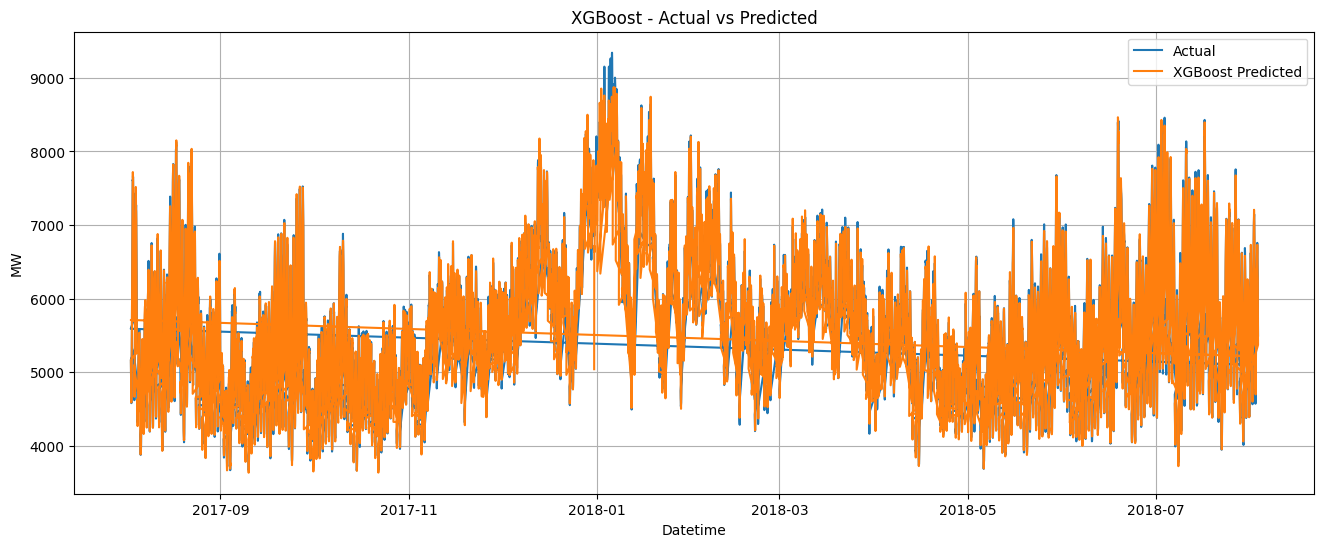

In [95]:
xgb_validation = pd.DataFrame({
    "Datetime": test_xgb["Datetime"].values,
    "Actual_MW": y_test.values,
    "XGBoost_Predicted_MW": xgb_pred
})

plt.figure(figsize=(16, 6))

plt.plot(
    xgb_validation["Datetime"],
    xgb_validation["Actual_MW"],
    label="Actual"
)

plt.plot(
    xgb_validation["Datetime"],
    xgb_validation["XGBoost_Predicted_MW"],
    label="XGBoost Predicted"
)

plt.title("XGBoost - Actual vs Predicted")
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.legend()
plt.grid(True)

plt.show()

In [97]:
xgb_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [mae],
    "RMSE": [rmse],
    "MAPE": [mape]
})

# Initialize model_comparison with classical_results, which is already defined
model_comparison = classical_results.copy()

model_comparison = pd.concat(
    [model_comparison, xgb_result],
    ignore_index=True
)

display(model_comparison)

,Model,Period,MAE,RMSE,MAPE (%),MAPE
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927,NaN
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207,NaN
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400,NaN
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861,NaN
4,XGBoost,NaN,72.603836,119.677517,NaN,1.265265


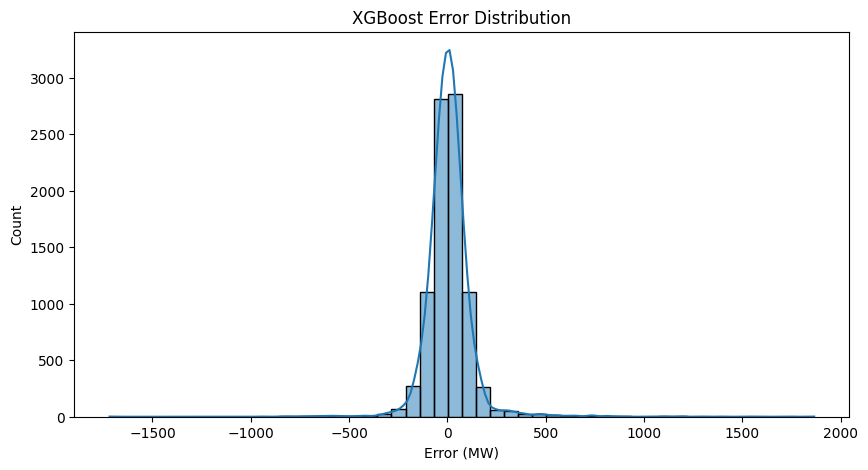

In [98]:
xgb_validation["Error_MW"] = (
    xgb_validation["Actual_MW"] -
    xgb_validation["XGBoost_Predicted_MW"]
)

xgb_validation["Absolute_Error_MW"] = (
    xgb_validation["Error_MW"].abs()
)

plt.figure(figsize=(10, 5))

sns.histplot(
    xgb_validation["Error_MW"],
    bins=50,
    kde=True
)

plt.title("XGBoost Error Distribution")
plt.xlabel("Error (MW)")
plt.show()

In [99]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
7,Lag_1,0.491779
8,Lag_24,0.307279
5,IsWeekend,0.063808
10,Lag_168,0.041605
1,DayOfWeek,0.026297
11,RollingMean_24,0.022548
0,Hour,0.019145
6,IsHoliday,0.006960
13,RollingStd_24,0.006476
3,Month,0.004489


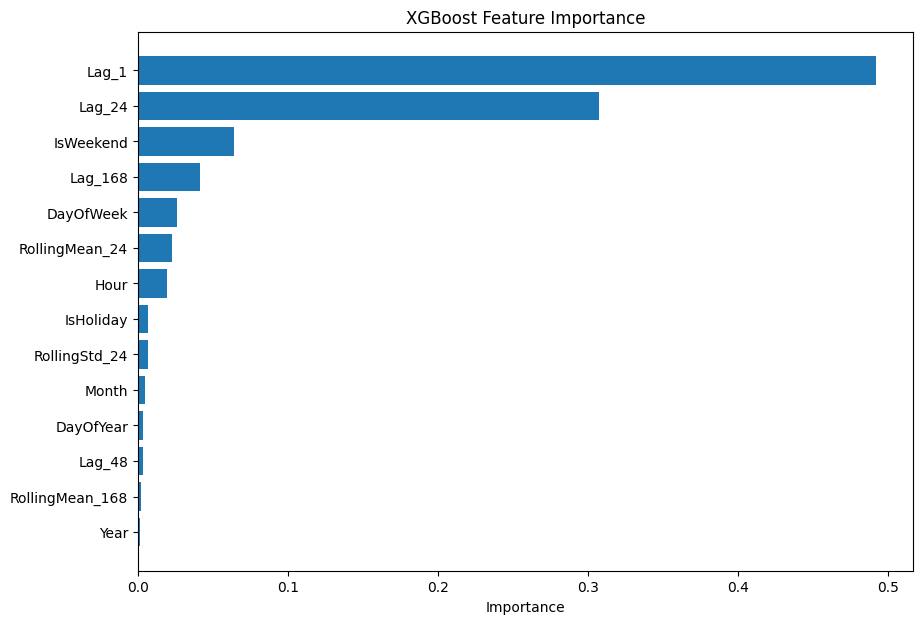

In [100]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")

plt.show()

In [102]:
def create_future_features(history, future_datetime):

    values = history["PJMW_MW"].values

    row = {
        "Hour": future_datetime.hour,
        "DayOfWeek": future_datetime.dayofweek,
        "DayOfYear": future_datetime.dayofyear,
        "Month": future_datetime.month,
        "Year": future_datetime.year,

        "IsWeekend": int(
            future_datetime.dayofweek >= 5
        ),

        "IsHoliday": int(
            future_datetime.date() in us_holidays
        ),

        "Lag_1": values[-1],
        "Lag_24": values[-24],
        "Lag_48": values[-48],
        "Lag_168": values[-168],

        "RollingMean_24": np.mean(values[-24:]),

        "RollingMean_168": np.mean(values[-168:]),

        "RollingStd_24": np.std(
            values[-24:],
            ddof=1
        )
    }

    return pd.DataFrame(
        [row]
    )[features]

In [103]:
history = df[
    ["Datetime", "PJMW_MW"]
].copy()

future_dates = []
future_predictions = []

last_datetime = history["Datetime"].max()

for step in range(1, 721):

    future_datetime = (
        last_datetime +
        pd.Timedelta(hours=step)
    )

    future_features = create_future_features(
        history,
        future_datetime
    )

    prediction = xgb_model.predict(
        future_features
    )[0]

    future_dates.append(
        future_datetime
    )

    future_predictions.append(
        prediction
    )

    # Add prediction to history
    history.loc[len(history)] = [
        future_datetime,
        prediction
    ]

xgb_future_forecast = pd.DataFrame({
    "Datetime": future_dates,
    "Predicted_MW": future_predictions
})

print(
    "Forecast rows:",
    len(xgb_future_forecast)
)

display(
    xgb_future_forecast.head()
)

Forecast rows: 720


,Datetime,Predicted_MW
0,2018-08-03 01:00:00,6992.413086
1,2018-08-03 02:00:00,6996.686523
2,2018-08-03 03:00:00,7119.294434
3,2018-08-03 04:00:00,7237.147949
4,2018-08-03 05:00:00,7479.462402


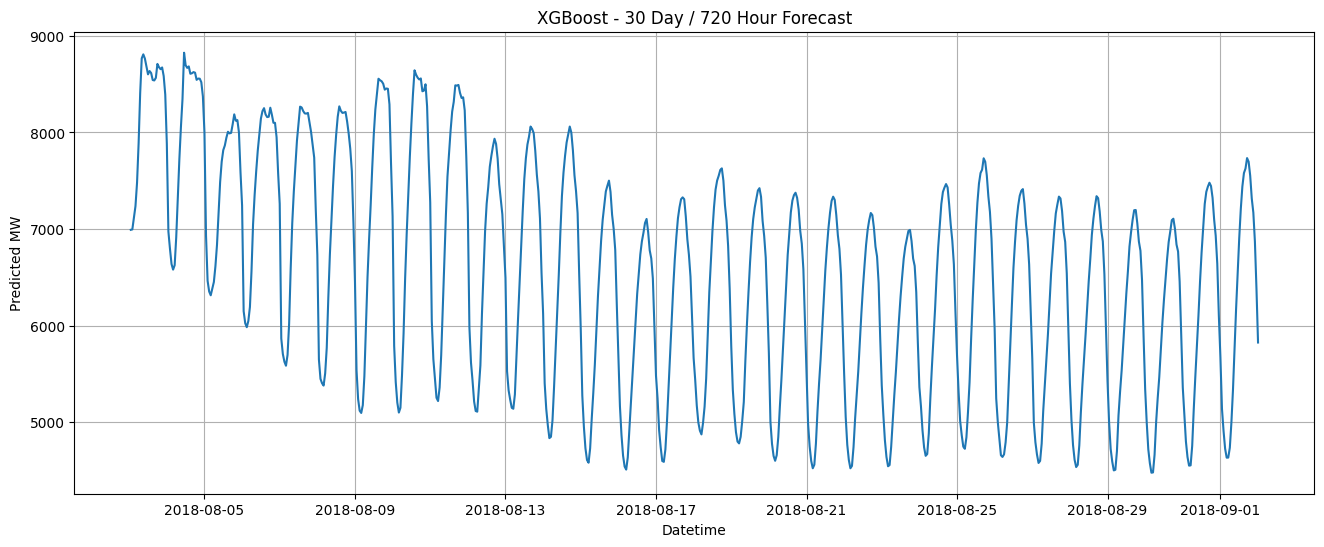

In [104]:
plt.figure(figsize=(16, 6))

plt.plot(
    xgb_future_forecast["Datetime"],
    xgb_future_forecast["Predicted_MW"]
)

plt.title(
    "XGBoost - 30 Day / 720 Hour Forecast"
)

plt.xlabel("Datetime")
plt.ylabel("Predicted MW")

plt.grid(True)

plt.show()

In [105]:
# Seasonal Naive future forecast
history_values = df["PJMW_MW"].tolist()

sn_dates = []
sn_predictions = []

last_datetime = df["Datetime"].max()

for step in range(1, 721):

    future_datetime = (
        last_datetime +
        pd.Timedelta(hours=step)
    )

    prediction = history_values[-24]

    sn_dates.append(future_datetime)
    sn_predictions.append(prediction)

    history_values.append(prediction)

seasonal_naive_future = pd.DataFrame({
    "Datetime": sn_dates,
    "SeasonalNaive_Predicted_MW": sn_predictions
})

# Combine
future_model_comparison = seasonal_naive_future.merge(
    xgb_future_forecast,
    on="Datetime"
)

display(
    future_model_comparison.head()
)

,Datetime,SeasonalNaive_Predicted_MW,Predicted_MW
0,2018-08-03 01:00:00,7469,6992.413086
1,2018-08-03 02:00:00,7423,6996.686523
2,2018-08-03 03:00:00,7380,7119.294434
3,2018-08-03 04:00:00,7366,7237.147949
4,2018-08-03 05:00:00,7428,7479.462402


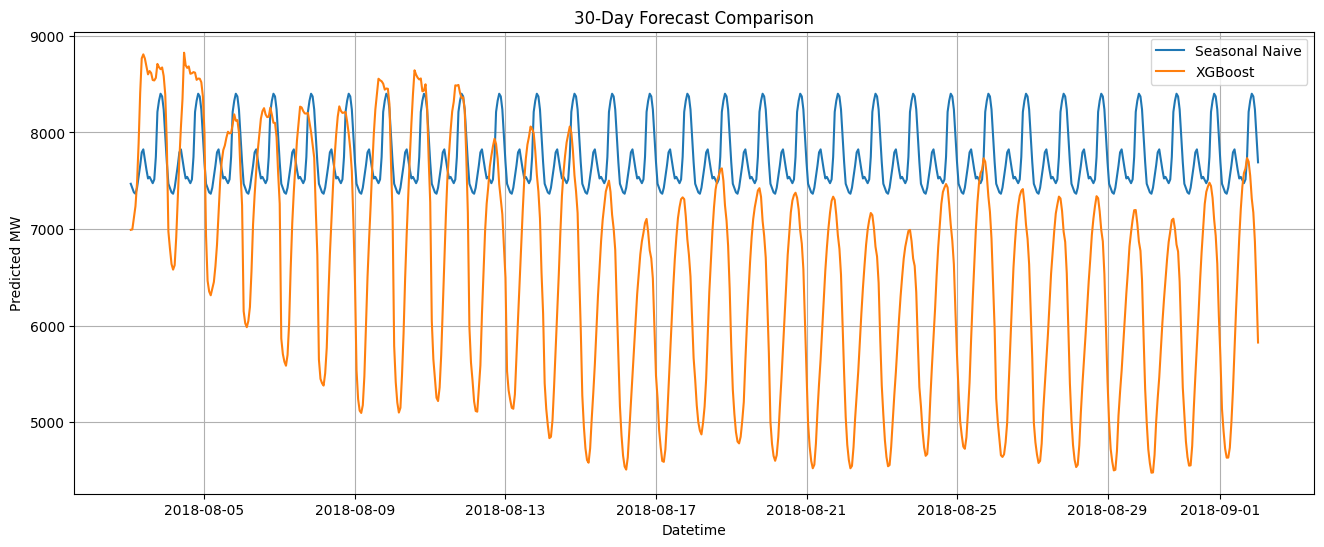

In [106]:
plt.figure(figsize=(16, 6))

plt.plot(
    future_model_comparison["Datetime"],
    future_model_comparison[
        "SeasonalNaive_Predicted_MW"
    ],
    label="Seasonal Naive"
)

plt.plot(
    future_model_comparison["Datetime"],
    future_model_comparison[
        "Predicted_MW"
    ],
    label="XGBoost"
)

plt.title(
    "30-Day Forecast Comparison"
)

plt.xlabel("Datetime")
plt.ylabel("Predicted MW")

plt.legend()
plt.grid(True)

plt.show()

In [107]:
xgb_daily_forecast = (
    xgb_future_forecast
    .assign(
        Date=xgb_future_forecast["Datetime"].dt.date
    )
    .groupby("Date")["Predicted_MW"]
    .mean()
    .reset_index()
)

xgb_daily_forecast.rename(
    columns={
        "Predicted_MW":
        "XGBoost_Average_MW"
    },
    inplace=True
)

display(xgb_daily_forecast)

,Date,XGBoost_Average_MW
0,2018-08-03,8275.268555
1,2018-08-04,7989.955078
2,2018-08-05,7434.690918
3,2018-08-06,7470.378418
4,2018-08-07,7280.708984
5,2018-08-08,7127.673340
6,2018-08-09,7184.595703
7,2018-08-10,7271.724609
8,2018-08-11,7183.373047
9,2018-08-12,6687.079590


In [108]:
output_dir = "pjm_xgboost_outputs"

os.makedirs(
    output_dir,
    exist_ok=True
)

xgb_validation.to_csv(
    f"{output_dir}/pjm_xgboost_validation_predictions.csv",
    index=False
)

xgb_future_forecast.to_csv(
    f"{output_dir}/pjm_xgboost_30_day_hourly_forecast.csv",
    index=False
)

future_model_comparison.to_csv(
    f"{output_dir}/pjm_30_day_hourly_model_comparison.csv",
    index=False
)

xgb_daily_forecast.to_csv(
    f"{output_dir}/pjm_xgboost_30_day_daily_forecast.csv",
    index=False
)

feature_importance.to_csv(
    f"{output_dir}/pjm_xgboost_feature_importance.csv",
    index=False
)

joblib.dump(
    xgb_model,
    f"{output_dir}/pjm_xgboost_model.pkl"
)

print("All XGBoost files saved successfully.")

All XGBoost files saved successfully.


In [109]:
# Add XGBoost results to the model comparison table

xgb_result = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [mae],
    "RMSE": [rmse],
    "MAPE": [mape]
})

model_comparison = pd.concat(
    [model_comparison, xgb_result],
    ignore_index=True
)

model_comparison

,Model,Period,MAE,RMSE,MAPE (%),MAPE
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927,NaN
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207,NaN
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400,NaN
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861,NaN
4,XGBoost,NaN,72.603836,119.677517,NaN,1.265265
5,XGBoost,NaN,72.603836,119.677517,NaN,1.265265


In [110]:
# Remove duplicate XGBoost rows
model_comparison = model_comparison.drop_duplicates(subset=["Model"], keep="first")

# Standardize the columns
model_comparison["Period"] = model_comparison["Period"].fillna("30-day validation")

# Use XGBoost MAPE column where the original MAPE (%) is missing
model_comparison["MAPE (%)"] = model_comparison["MAPE (%)"].fillna(
    model_comparison["MAPE"]
)

# Remove the extra MAPE column
model_comparison = model_comparison.drop(columns=["MAPE"])

# Display final comparison
model_comparison

,Model,Period,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861
4,XGBoost,30-day validation,72.603836,119.677517,1.265265


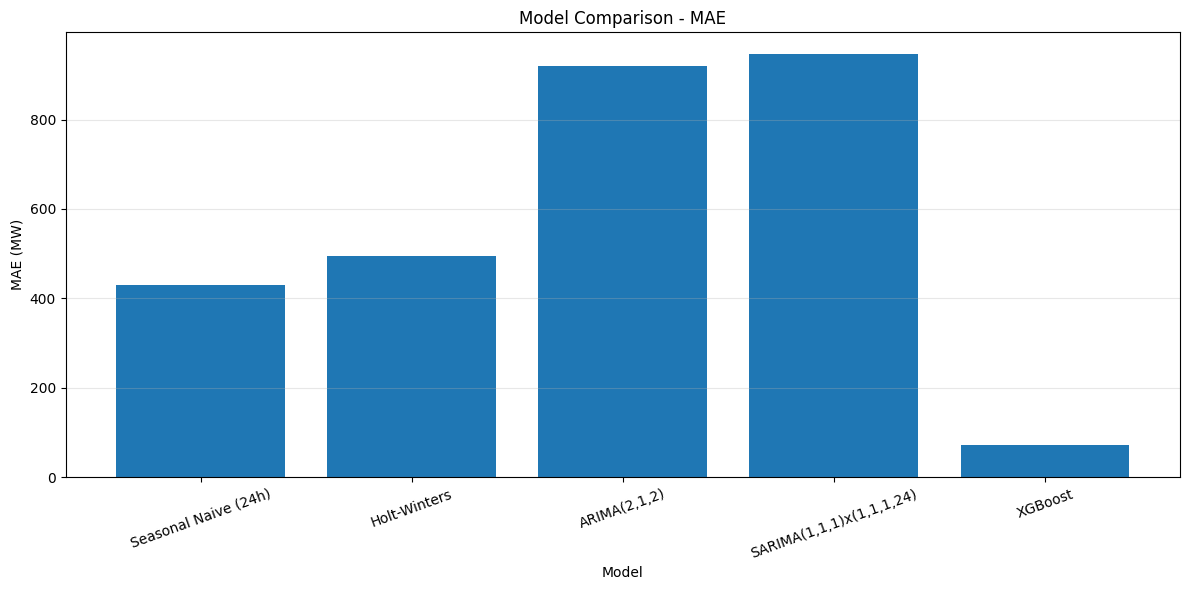

In [111]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(model_comparison["Model"], model_comparison["MAE"])

plt.title("Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("MAE (MW)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

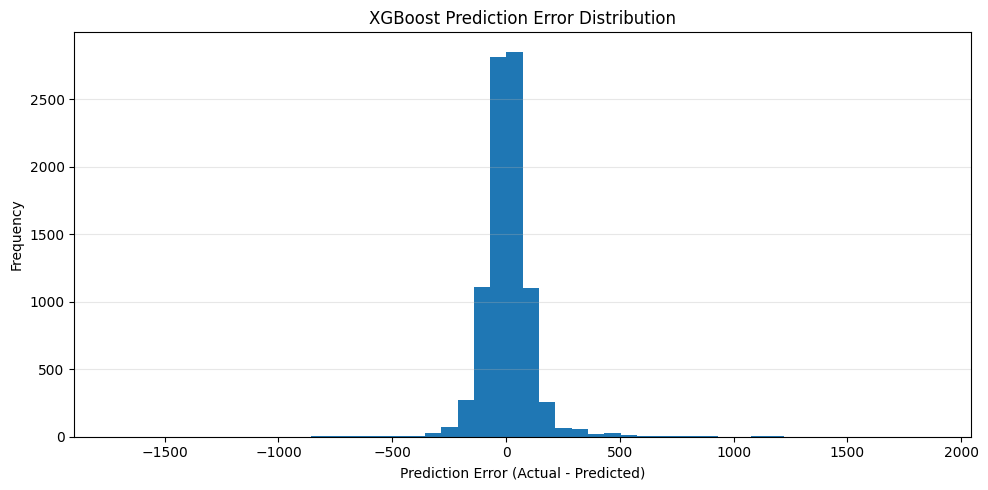

In [112]:
# XGBoost Error Analysis

xgb_errors = y_test.values - xgb_pred

plt.figure(figsize=(10, 5))

plt.hist(xgb_errors, bins=50)

plt.title("XGBoost Prediction Error Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [113]:
# XGBoost Feature Importance

feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance

,Feature,Importance
7,Lag_1,0.491779
8,Lag_24,0.307279
5,IsWeekend,0.063808
10,Lag_168,0.041605
1,DayOfWeek,0.026297
11,RollingMean_24,0.022548
0,Hour,0.019145
6,IsHoliday,0.006960
13,RollingStd_24,0.006476
3,Month,0.004489


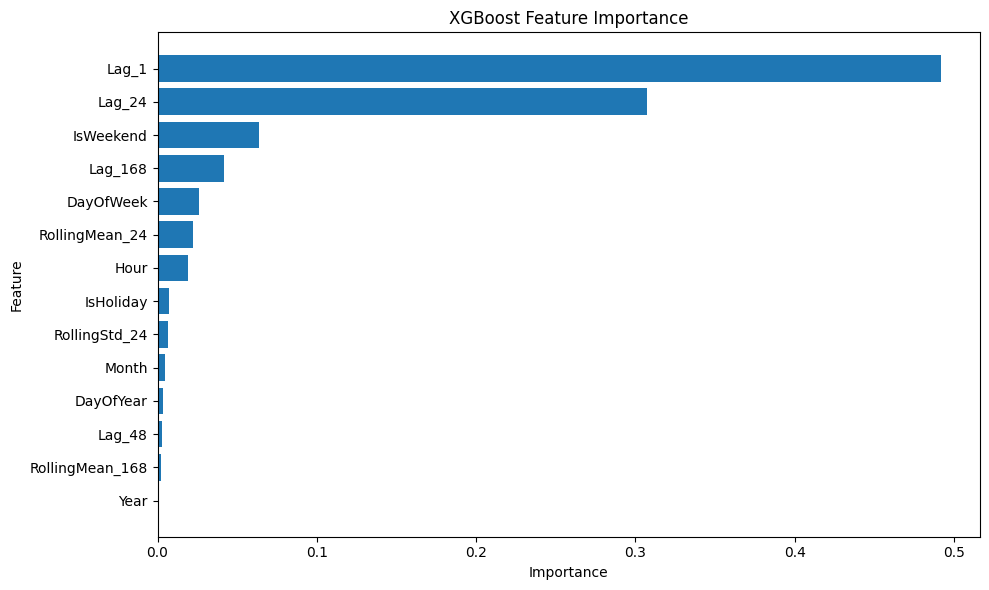

In [114]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [115]:
# Generate next 30-day (720-hour) XGBoost forecast

history = df[["Datetime", "PJMW_MW"]].copy()
history = history.sort_values("Datetime").reset_index(drop=True)

future_dates = pd.date_range(
    start=history["Datetime"].max() + pd.Timedelta(hours=1),
    periods=720,
    freq="h"
)

xgb_future_predictions = []

for future_time in future_dates:

    temp = history.copy()

    # Calendar features
    temp["Hour"] = temp["Datetime"].dt.hour
    temp["DayOfWeek"] = temp["Datetime"].dt.dayofweek
    temp["DayOfYear"] = temp["Datetime"].dt.dayofyear
    temp["Month"] = temp["Datetime"].dt.month
    temp["Year"] = temp["Datetime"].dt.year
    temp["IsWeekend"] = (temp["DayOfWeek"] >= 5).astype(int)

    # Holiday feature
    temp["IsHoliday"] = temp["Datetime"].dt.date.isin(
        holidays.US(years=range(
            temp["Datetime"].dt.year.min(),
            temp["Datetime"].dt.year.max() + 1
        )).keys()
    ).astype(int)

    # Lag features
    temp["Lag_1"] = temp["PJMW_MW"].shift(1)
    temp["Lag_24"] = temp["PJMW_MW"].shift(24)
    temp["Lag_48"] = temp["PJMW_MW"].shift(48)
    temp["Lag_168"] = temp["PJMW_MW"].shift(168)

    # Rolling features
    temp["RollingMean_24"] = (
        temp["PJMW_MW"].shift(1).rolling(24).mean()
    )

    temp["RollingMean_168"] = (
        temp["PJMW_MW"].shift(1).rolling(168).mean()
    )

    temp["RollingStd_24"] = (
        temp["PJMW_MW"].shift(1).rolling(24).std()
    )

    # Create future row
    future_row = pd.DataFrame({
        "Datetime": [future_time],
        "Hour": [future_time.hour],
        "DayOfWeek": [future_time.dayofweek],
        "DayOfYear": [future_time.dayofyear],
        "Month": [future_time.month],
        "Year": [future_time.year],
        "IsWeekend": [int(future_time.dayofweek >= 5)],
        "IsHoliday": [int(
            future_time.date() in holidays.US(
                years=[future_time.year]
            )
        )],
        "Lag_1": [temp["PJMW_MW"].iloc[-1]],
        "Lag_24": [temp["PJMW_MW"].iloc[-24]],
        "Lag_48": [temp["PJMW_MW"].iloc[-48]],
        "Lag_168": [temp["PJMW_MW"].iloc[-168]],
        "RollingMean_24": [temp["PJMW_MW"].iloc[-24:].mean()],
        "RollingMean_168": [temp["PJMW_MW"].iloc[-168:].mean()],
        "RollingStd_24": [temp["PJMW_MW"].iloc[-24:].std()]
    })

    # Predict
    prediction = xgb_model.predict(
        future_row[features]
    )[0]

    xgb_future_predictions.append(prediction)

    # Add prediction to history for next recursive prediction
    history = pd.concat([
        history,
        pd.DataFrame({
            "Datetime": [future_time],
            "PJMW_MW": [prediction]
        })
    ], ignore_index=True)

# Final forecast dataframe
xgb_30_day_forecast = pd.DataFrame({
    "Datetime": future_dates,
    "Predicted_MW": xgb_future_predictions
})

xgb_30_day_forecast.head()

,Datetime,Predicted_MW
0,2018-08-03 01:00:00,5140.721191
1,2018-08-03 02:00:00,4917.614746
2,2018-08-03 03:00:00,4779.590820
3,2018-08-03 04:00:00,4687.826172
4,2018-08-03 05:00:00,4716.553223


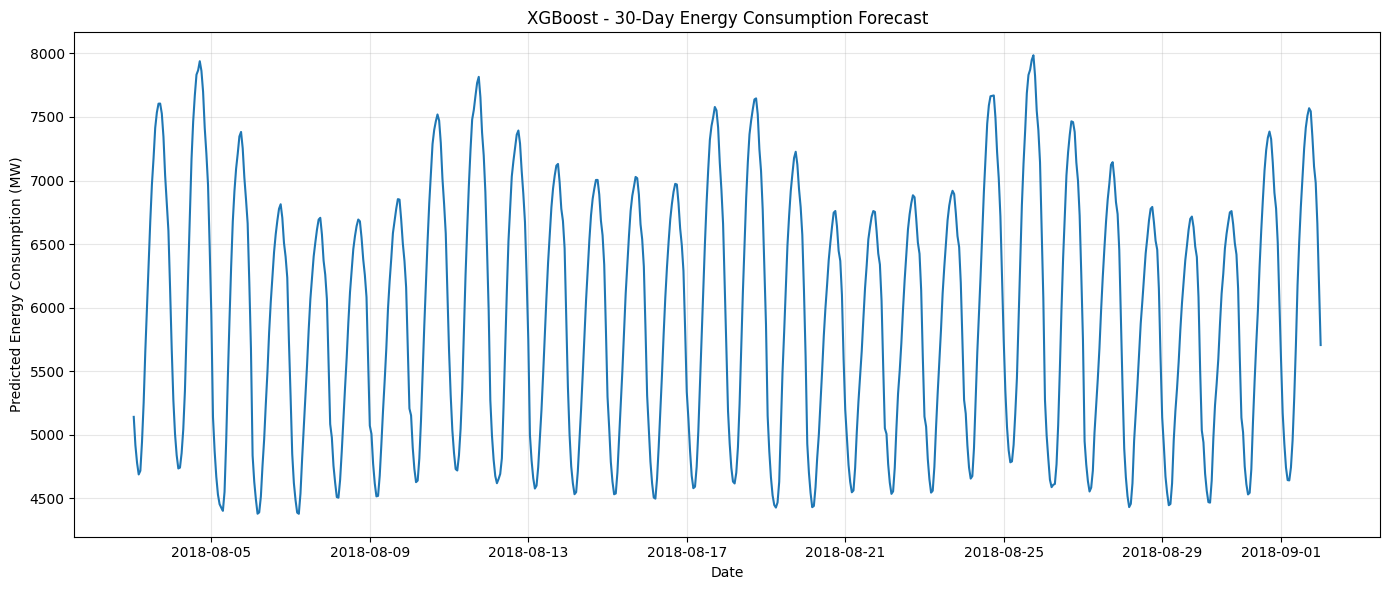

In [116]:
plt.figure(figsize=(14, 6))

plt.plot(
    xgb_30_day_forecast["Datetime"],
    xgb_30_day_forecast["Predicted_MW"]
)

plt.title("XGBoost - 30-Day Energy Consumption Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Energy Consumption (MW)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()m

In [117]:
# Generate Seasonal Naive 30-day forecast

seasonal_naive_30d = []

history_values = df["PJMW_MW"].tolist()

for i in range(720):
    prediction = history_values[-24]
    seasonal_naive_30d.append(prediction)
    history_values.append(prediction)

seasonal_naive_forecast = pd.DataFrame({
    "Datetime": xgb_30_day_forecast["Datetime"],
    "Seasonal_Naive_MW": seasonal_naive_30d,
    "XGBoost_MW": xgb_30_day_forecast["Predicted_MW"]
})

seasonal_naive_forecast.head()

,Datetime,Seasonal_Naive_MW,XGBoost_MW
0,2018-08-03 01:00:00,7469,5140.721191
1,2018-08-03 02:00:00,7423,4917.614746
2,2018-08-03 03:00:00,7380,4779.590820
3,2018-08-03 04:00:00,7366,4687.826172
4,2018-08-03 05:00:00,7428,4716.553223


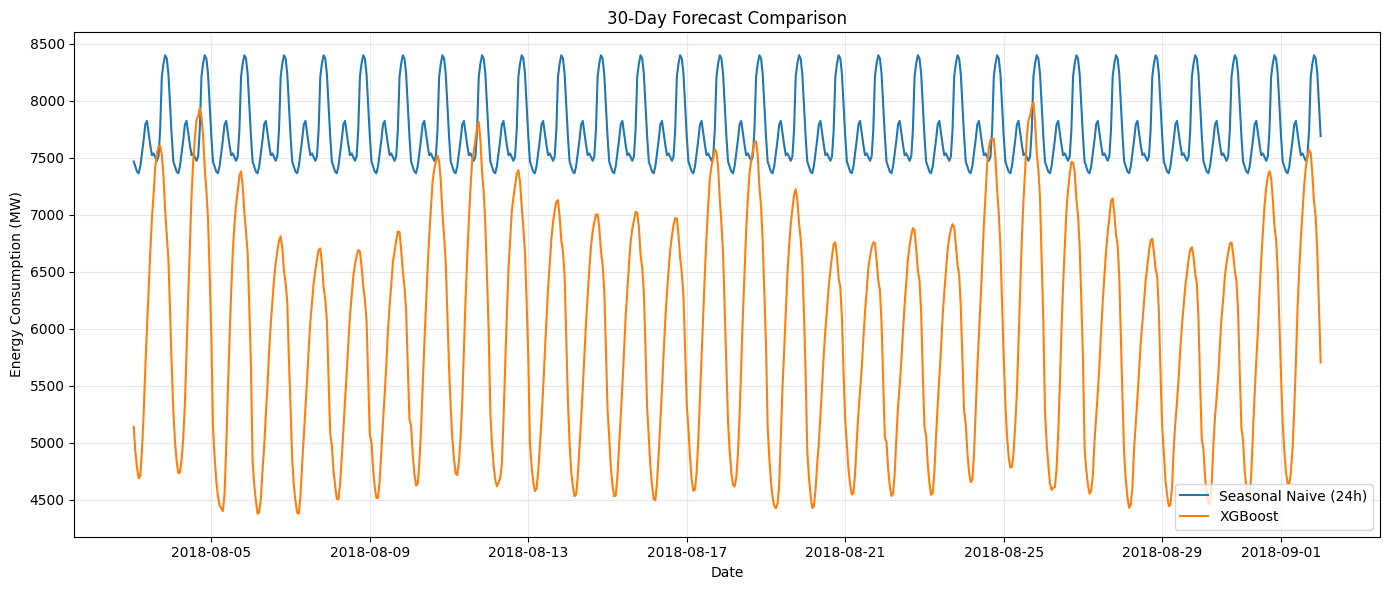

In [118]:
plt.figure(figsize=(14, 6))

plt.plot(
    seasonal_naive_forecast["Datetime"],
    seasonal_naive_forecast["Seasonal_Naive_MW"],
    label="Seasonal Naive (24h)"
)

plt.plot(
    seasonal_naive_forecast["Datetime"],
    seasonal_naive_forecast["XGBoost_MW"],
    label="XGBoost"
)

plt.title("30-Day Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [119]:
# Convert hourly XGBoost forecast to daily forecast

xgb_30_day_daily = (
    xgb_30_day_forecast
    .set_index("Datetime")
    .resample("D")["Predicted_MW"]
    .mean()
    .reset_index()
)

xgb_30_day_daily.rename(
    columns={"Predicted_MW": "Daily_Average_MW"},
    inplace=True
)

xgb_30_day_daily.head()

,Datetime,Daily_Average_MW
0,2018-08-03,6300.050781
1,2018-08-04,6412.897949
2,2018-08-05,5926.385254
3,2018-08-06,5680.742188
4,2018-08-07,5633.303223


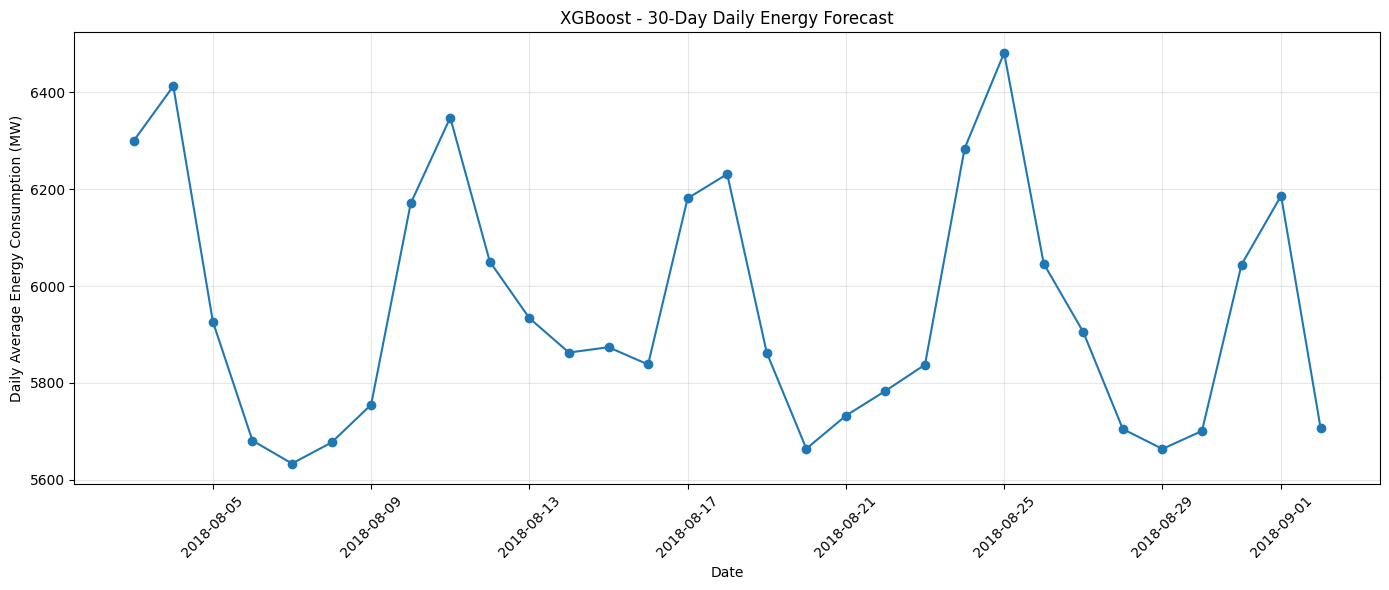

In [120]:
plt.figure(figsize=(14, 6))

plt.plot(
    xgb_30_day_daily["Datetime"],
    xgb_30_day_daily["Daily_Average_MW"],
    marker="o"
)

plt.title("XGBoost - 30-Day Daily Energy Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Average Energy Consumption (MW)")
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [121]:
# ============================================================
# SAVE XGBOOST VALIDATION PREDICTIONS
# ============================================================

xgb_validation_predictions = pd.DataFrame({
    "Datetime": test_xgb["Datetime"].values,
    "Actual_MW": y_test.values,
    "Predicted_MW": xgb_pred
})

xgb_validation_predictions["Error"] = (
    xgb_validation_predictions["Actual_MW"]
    - xgb_validation_predictions["Predicted_MW"]
)

xgb_validation_predictions["Absolute_Error"] = (
    xgb_validation_predictions["Error"].abs()
)

xgb_validation_predictions.to_csv(
    "pjm_xgboost_validation_predictions.csv",
    index=False
)

print("XGBoost validation predictions saved.")

XGBoost validation predictions saved.


In [122]:
# ============================================================
# SAVE XGBOOST 30-DAY HOURLY FORECAST
# ============================================================

xgb_30_day_forecast.to_csv(
    "pjm_xgboost_30_day_hourly_forecast.csv",
    index=False
)

print("XGBoost 30-day hourly forecast saved.")
print("Rows:", len(xgb_30_day_forecast))

XGBoost 30-day hourly forecast saved.
Rows: 720


In [123]:
# ============================================================
# SAVE XGBOOST 30-DAY DAILY FORECAST
# ============================================================

xgb_30_day_daily.to_csv(
    "pjm_xgboost_30_day_daily_forecast.csv",
    index=False
)

print("XGBoost 30-day daily forecast saved.")
print("Days:", len(xgb_30_day_daily))

XGBoost 30-day daily forecast saved.
Days: 31


In [124]:
# ============================================================
# SAVE XGBOOST FEATURE IMPORTANCE
# ============================================================

feature_importance.to_csv(
    "pjm_xgboost_feature_importance.csv",
    index=False
)

print("Feature importance saved.")

Feature importance saved.


In [125]:
# ============================================================
# SAVE XGBOOST MODEL
# ============================================================

import joblib

joblib.dump(
    xgb_model,
    "pjm_xgboost_model.pkl"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


In [126]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

final_model_comparison = model_comparison.copy()

final_model_comparison = final_model_comparison[
    ["Model", "Period", "MAE", "RMSE", "MAPE (%)"]
]

final_model_comparison.to_csv(
    "pjm_all_model_comparison_results_with_xgboost.csv",
    index=False
)

display(final_model_comparison)

,Model,Period,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861
4,XGBoost,30-day validation,72.603836,119.677517,1.265265


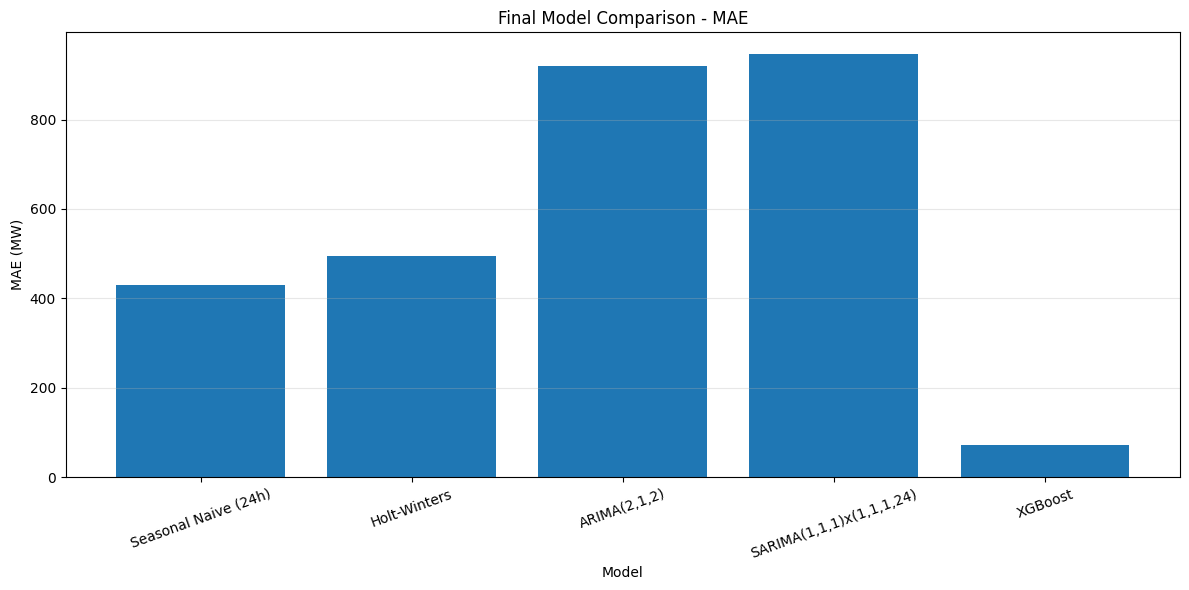

In [127]:
# ============================================================
# FINAL MODEL COMPARISON - MAE
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAE"]
)

plt.title("Final Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("MAE (MW)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

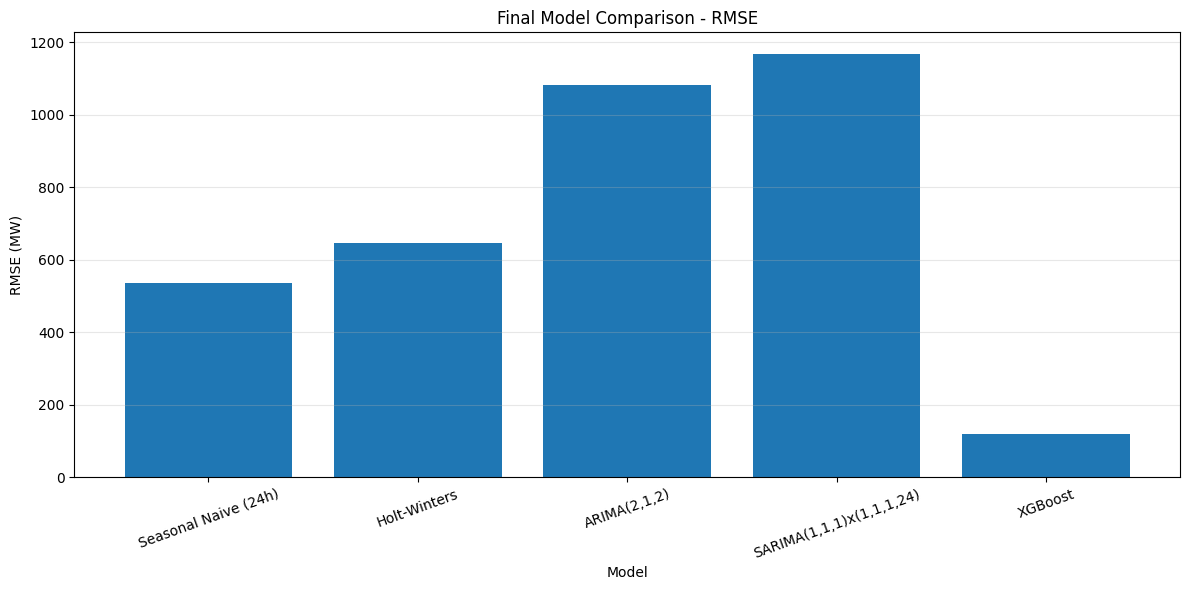

In [128]:
# ============================================================
# FINAL MODEL COMPARISON - RMSE
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["RMSE"]
)

plt.title("Final Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE (MW)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

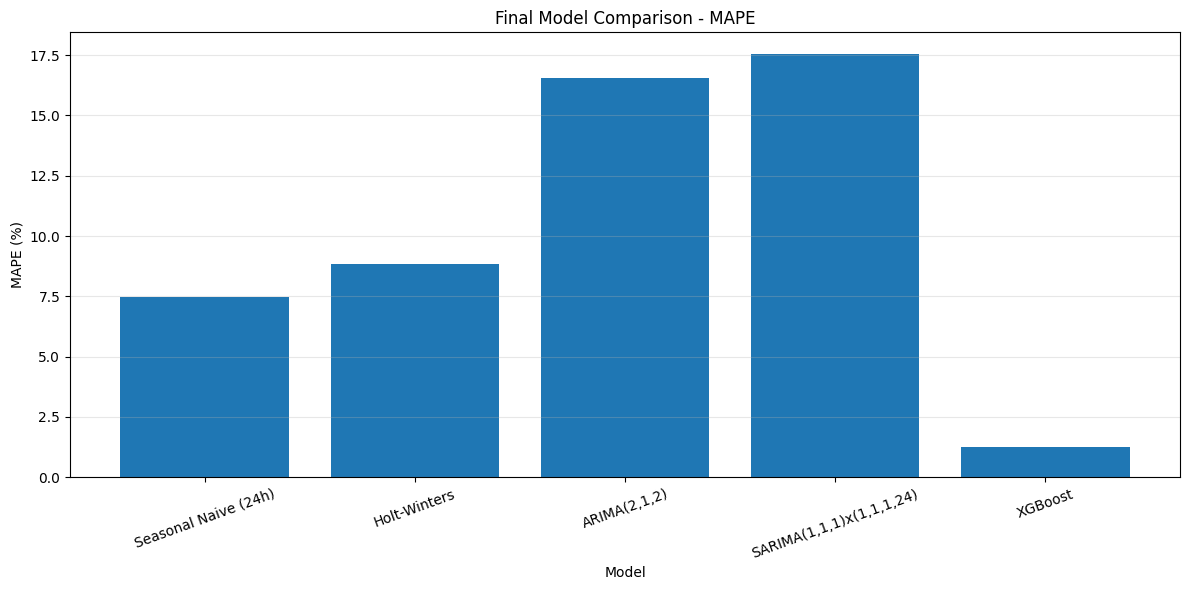

In [129]:
# ============================================================
# FINAL MODEL COMPARISON - MAPE
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAPE (%)"]
)

plt.title("Final Model Comparison - MAPE")
plt.xlabel("Model")
plt.ylabel("MAPE (%)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

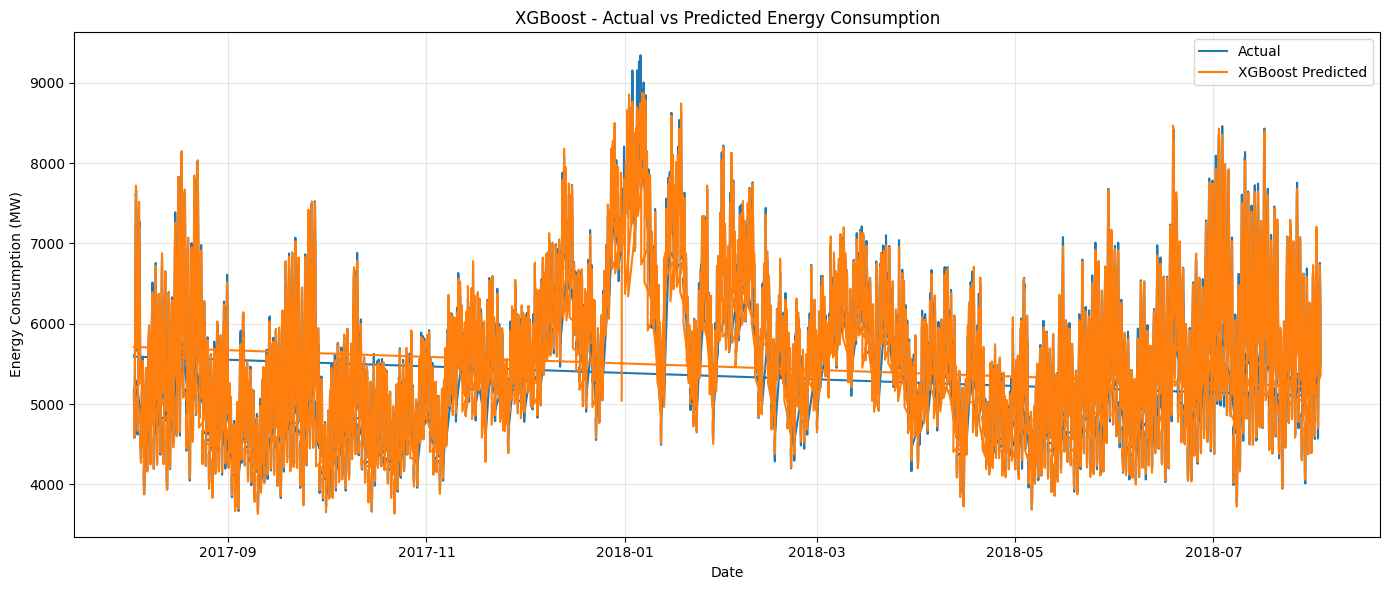

In [130]:
# ============================================================
# XGBOOST - ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    xgb_validation_predictions["Datetime"],
    xgb_validation_predictions["Actual_MW"],
    label="Actual"
)

plt.plot(
    xgb_validation_predictions["Datetime"],
    xgb_validation_predictions["Predicted_MW"],
    label="XGBoost Predicted"
)

plt.title("XGBoost - Actual vs Predicted Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

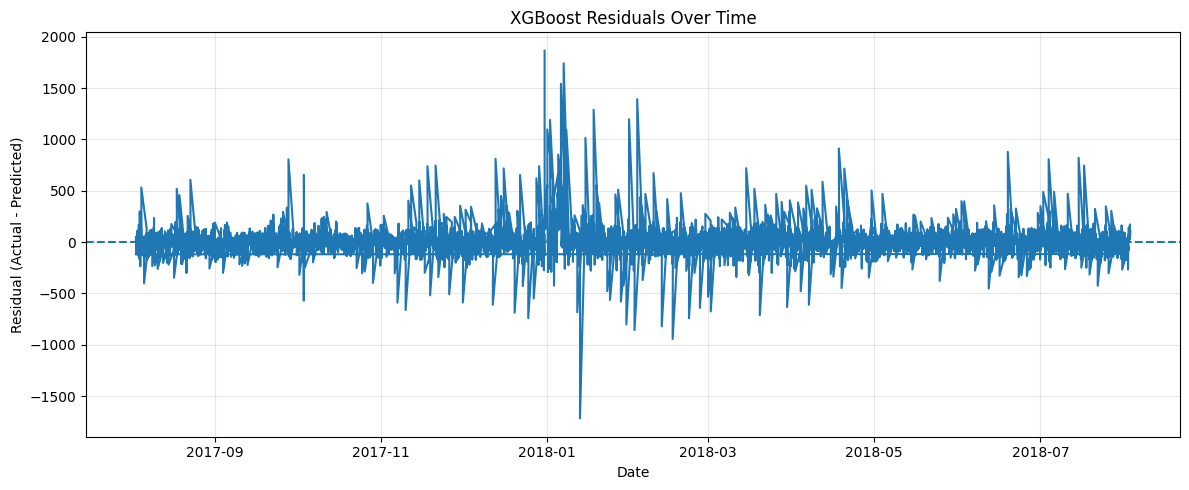

In [131]:
# ============================================================
# XGBOOST - RESIDUAL ANALYSIS
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    xgb_validation_predictions["Datetime"],
    xgb_validation_predictions["Error"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("XGBoost Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [132]:
# ============================================================
# FINAL PROJECT MODELING SUMMARY
# ============================================================

print("=" * 70)
print("PJM ENERGY CONSUMPTION FORECASTING - MODEL SUMMARY")
print("=" * 70)

print("\nModel Comparison:")
display(final_model_comparison)

print("\nXGBoost Validation:")
print(f"MAE  : {mae:.2f} MW")
print(f"RMSE : {rmse:.2f} MW")
print(f"MAPE : {mape:.2f}%")

print("\nXGBoost Forecast:")
print(f"Forecast hours : {len(xgb_30_day_forecast)}")
print(f"Forecast days  : {len(xgb_30_day_daily)}")

print("\nProduction Model:")
print("Seasonal Naive (24h)")

print("\nXGBoost:")
print("Benchmark model for comparison and analysis.")

print("\nAll XGBoost artifacts saved successfully.")

PJM ENERGY CONSUMPTION FORECASTING - MODEL SUMMARY

Model Comparison:


,Model,Period,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861
4,XGBoost,30-day validation,72.603836,119.677517,1.265265



XGBoost Validation:
MAE  : 72.60 MW
RMSE : 119.68 MW
MAPE : 1.27%

XGBoost Forecast:
Forecast hours : 720
Forecast days  : 31

Production Model:
Seasonal Naive (24h)

XGBoost:
Benchmark model for comparison and analysis.

All XGBoost artifacts saved successfully.


In [133]:
# ============================================================
# FINAL PROJECT VALIDATION CHECK
# ============================================================

import os

required_files = [
    "pjm_xgboost_validation_predictions.csv",
    "pjm_xgboost_30_day_hourly_forecast.csv",
    "pjm_xgboost_30_day_daily_forecast.csv",
    "pjm_xgboost_feature_importance.csv",
    "pjm_xgboost_model.pkl",
    "pjm_all_model_comparison_results_with_xgboost.csv"
]

print("=" * 70)
print("FINAL PROJECT VALIDATION")
print("=" * 70)

print("\n1. Required Files")
print("-" * 70)

for file in required_files:
    status = "✓ EXISTS" if os.path.exists(file) else "✗ MISSING"
    print(f"{status}: {file}")

print("\n2. XGBoost Validation")
print("-" * 70)
print(f"MAE  : {mae:.2f} MW")
print(f"RMSE : {rmse:.2f} MW")
print(f"MAPE : {mape:.2f}%")

print("\n3. 30-Day Forecast")
print("-" * 70)
print(f"Hourly forecast rows : {len(xgb_30_day_forecast)}")
print(f"Daily forecast rows  : {len(xgb_30_day_daily)}")

print(
    f"Forecast start       : "
    f"{xgb_30_day_forecast['Datetime'].min()}"
)

print(
    f"Forecast end         : "
    f"{xgb_30_day_forecast['Datetime'].max()}"
)

print("\n4. Model Comparison")
print("-" * 70)
display(final_model_comparison)

print("\n5. Production Model")
print("-" * 70)
print("Production model: Seasonal Naive (24h)")
print("XGBoost: Benchmark model")

print("\n" + "=" * 70)
print("VALIDATION CHECK COMPLETED")
print("=" * 70)

FINAL PROJECT VALIDATION

1. Required Files
----------------------------------------------------------------------
✓ EXISTS: pjm_xgboost_validation_predictions.csv
✓ EXISTS: pjm_xgboost_30_day_hourly_forecast.csv
✓ EXISTS: pjm_xgboost_30_day_daily_forecast.csv
✓ EXISTS: pjm_xgboost_feature_importance.csv
✓ EXISTS: pjm_xgboost_model.pkl
✓ EXISTS: pjm_all_model_comparison_results_with_xgboost.csv

2. XGBoost Validation
----------------------------------------------------------------------
MAE  : 72.60 MW
RMSE : 119.68 MW
MAPE : 1.27%

3. 30-Day Forecast
----------------------------------------------------------------------
Hourly forecast rows : 720
Daily forecast rows  : 31
Forecast start       : 2018-08-03 01:00:00
Forecast end         : 2018-09-02 00:00:00

4. Model Comparison
----------------------------------------------------------------------


,Model,Period,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),30-day validation,429.025000,536.050635,7.454927
1,Holt-Winters,30-day validation,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",30-day validation,920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",30-day validation,947.700686,1169.223434,17.562861
4,XGBoost,30-day validation,72.603836,119.677517,1.265265



5. Production Model
----------------------------------------------------------------------
Production model: Seasonal Naive (24h)
XGBoost: Benchmark model

VALIDATION CHECK COMPLETED


## **10. PCA + Linear Regression**

PCA is not automatically beneficial for tree models, so we use it with a standardized linear model.

The workflow is:

**features → standardization → PCA → retain 95% variance → Linear Regression**

This lets us demonstrate dimensionality reduction without leaking information from the test period.

In [63]:
# ============================================================
# PCA + LINEAR REGRESSION
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("model", LinearRegression())
])

pca_linear.fit(X_train, y_train)
pca_pred = pca_linear.predict(X_test)

pca_final = evaluate_forecast(
    y_test,
    pca_pred,
    "PCA + Linear Regression",
    "Final last-year test"
)

pca_components = pca_linear.named_steps["pca"].n_components_

print(pca_final)
print("Original features:", X_train.shape[1])
print("PCA components retaining 95% variance:", pca_components)


{'Model': 'PCA + Linear Regression', 'Period': 'Final last-year test', 'MAE': 219.93699097702174, 'RMSE': 282.19892634289874, 'MAPE (%)': np.float64(3.853111719752738)}
Original features: 19
PCA components retaining 95% variance: 12


# **Deep Learning — LSTM**

LSTM is designed for sequential data and can learn temporal dependencies from a sequence of previous observations.

To keep Colab runtime practical, the LSTM development experiment uses a recent two-year training window and a 168-hour lookback (one week). It predicts the 30-day validation window recursively.

The LSTM is not declared the final model in advance; its results are compared with the classical and ML approaches.

In [64]:
# ============================================================
# LSTM PREPARATION — 168-HOUR LOOKBACK
# ============================================================

from sklearn.preprocessing import MinMaxScaler

lstm_train_series = model_train.set_index("Datetime")["PJMW_MW"].tail(2 * 365 * 24)

lstm_scaler = MinMaxScaler()
lstm_scaled = lstm_scaler.fit_transform(
    lstm_train_series.values.reshape(-1, 1)
)

LOOKBACK = 168

def make_lstm_sequences(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.array(X), np.array(y)

X_lstm, y_lstm = make_lstm_sequences(lstm_scaled, LOOKBACK)

X_lstm = X_lstm.reshape(
    X_lstm.shape[0],
    X_lstm.shape[1],
    1
)

print("LSTM X shape:", X_lstm.shape)
print("LSTM y shape:", y_lstm.shape)


LSTM X shape: (17352, 168, 1)
LSTM y shape: (17352, 1)


In [65]:
# ============================================================
# LSTM MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_lstm,
    y_lstm,
    epochs=8,
    batch_size=128,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 23s 176ms/step - loss: 0.0335 - val_loss: 0.0175
Epoch 2/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 175ms/step - loss: 0.0197 - val_loss: 0.0128
Epoch 3/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 41s 175ms/step - loss: 0.0135 - val_loss: 0.0064
Epoch 4/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 21s 171ms/step - loss: 0.0085 - val_loss: 0.0051
Epoch 5/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 177ms/step - loss: 0.0064 - val_loss: 0.0035
Epoch 6/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 177ms/step - loss: 0.0052 - val_loss: 0.0031
Epoch 7/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 177ms/step - loss: 0.0047 - val_loss: 0.0028
Epoch 8/8
122/122 ━━━━━━━━━━━━━━━━━━━━ 22s 181ms/step - loss: 0.0040 - val_loss: 0.0026


In [66]:
# ============================================================
# LSTM RECURSIVE 30-DAY VALIDATION FORECAST
# ============================================================

# Start from the last 168 training observations and recursively
# append each prediction before predicting the next hour.

history_scaled = list(lstm_scaled[-LOOKBACK:].flatten())
lstm_predictions_scaled = []

for _ in range(len(model_valid)):
    x_input = np.array(history_scaled[-LOOKBACK:]).reshape(1, LOOKBACK, 1)

    next_scaled = float(lstm_model.predict(x_input, verbose=0)[0, 0])

    lstm_predictions_scaled.append(next_scaled)
    history_scaled.append(next_scaled)

lstm_pred = lstm_scaler.inverse_transform(
    np.array(lstm_predictions_scaled).reshape(-1, 1)
).flatten()

lstm_result = evaluate_forecast(
    model_valid["PJMW_MW"].values,
    lstm_pred,
    "LSTM",
    "30-day validation"
)

print(lstm_result)


{'Model': 'LSTM', 'Period': '30-day validation', 'MAE': 1079.4943048635291, 'RMSE': 1354.1835500390748, 'MAPE (%)': np.float64(16.96960317897015)}


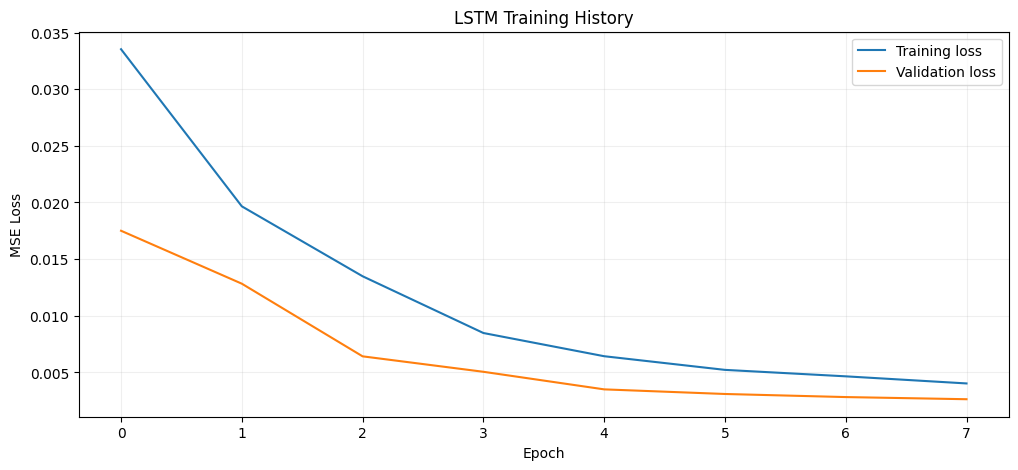

In [67]:
# ============================================================
# LSTM LOSS CURVE
# ============================================================

plt.figure(figsize=(12, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# **Complete Model Comparison — One Project, Different Model Families**

We now bring every experiment into one comparison.

**Important:** The table is for analysis, not an automatic winner-takes-all competition. ML/XGBoost can be numerically strong on engineered features, but this project is specifically an hourly time-series forecasting system. Therefore the **production model is selected only from the classical time-series family**.

This gives a clear review story:

> “I compared classical time-series, machine-learning, PCA and LSTM approaches. XGBoost was included as a strong benchmark, but for the final deployable forecasting system I selected the best-performing classical time-series model based on chronological validation.”

In [68]:
# ============================================================
# COMPLETE MODEL COMPARISON TABLE
# ============================================================

# Classical time-series validation results
ts_results = pd.DataFrame([
    naive_result,
    hw_result,
    arima_result,
    sarima_result
]).copy()
ts_results["Family"] = "Classical Time-Series"
ts_results["Selection"] = "Eligible for production"

# LSTM is a sequential/deep-learning benchmark.
dl_results = pd.DataFrame([lstm_result]).copy()
dl_results["Family"] = "Deep Learning"
dl_results["Selection"] = "Benchmark only"

# ML models were evaluated on the untouched last-year test set.
ml_results = pd.DataFrame([
    linear_final, dt_final, rf_final, gb_final, xgb_final, pca_final
]).copy()
ml_results["Family"] = "Machine Learning / PCA"
ml_results["Selection"] = "Benchmark only"

all_model_results = pd.concat(
    [ts_results, dl_results, ml_results],
    ignore_index=True,
    sort=False
)

display(all_model_results[["Model", "Family", "Period", "MAE", "RMSE", "MAPE (%)", "Selection"]])


,Model,Family,Period,MAE,RMSE,MAPE (%),Selection
0,Seasonal Naive (24h),Classical Time-Series,30-day validation,429.025000,536.050635,7.454927,Eligible for production
1,Holt-Winters,Classical Time-Series,30-day validation,495.945842,647.397829,8.821207,Eligible for production
2,"ARIMA(2,1,2)",Classical Time-Series,30-day validation,920.537687,1083.132267,16.563400,Eligible for production
3,"SARIMA(1,1,1)x(1,1,1,24)",Classical Time-Series,30-day validation,947.700686,1169.223434,17.562861,Eligible for production
4,LSTM,Deep Learning,30-day validation,1079.494305,1354.183550,16.969603,Benchmark only
5,Linear Regression,Machine Learning / PCA,Final last-year test,128.345793,164.012589,2.214795,Benchmark only
6,Decision Tree,Machine Learning / PCA,Final last-year test,75.207829,101.236492,1.310594,Benchmark only
7,Random Forest,Machine Learning / PCA,Final last-year test,80.167963,108.737514,1.370113,Benchmark only
8,Gradient Boosting,Machine Learning / PCA,Final last-year test,75.037589,96.577922,1.312145,Benchmark only
9,XGBoost,Machine Learning / PCA,Final last-year test,54.477295,74.110856,0.939797,Benchmark only


## **Model Comparison Graph**

The graph below makes the numerical comparison easy to present. Remember that the lowest number is not the only project decision: the production eligibility column above separates time-series candidates from benchmark models.

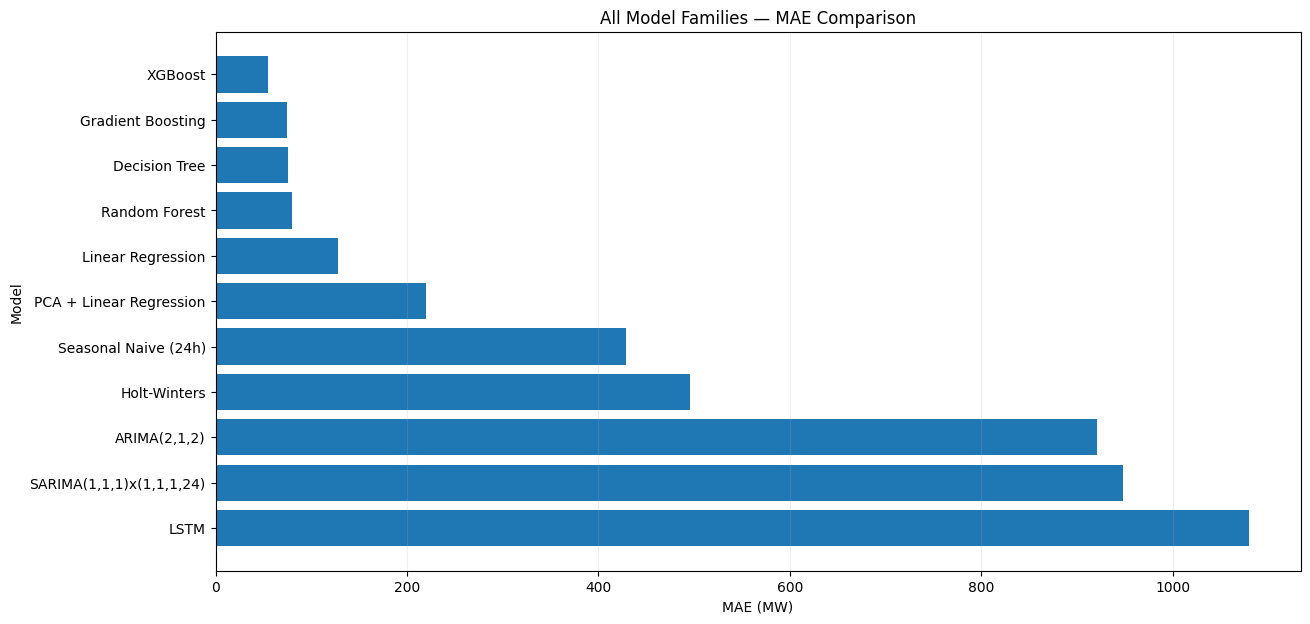

In [69]:
# ============================================================
# MODEL COMPARISON GRAPH
# ============================================================

comparison_plot = all_model_results.sort_values("MAE", ascending=True).copy()

plt.figure(figsize=(14, 7))
plt.barh(comparison_plot["Model"], comparison_plot["MAE"])
plt.xlabel("MAE (MW)")
plt.ylabel("Model")
plt.title("All Model Families — MAE Comparison")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.2)
plt.show()


# **Time-Series Model Selection**

The production model is now selected **only from the classical time-series candidates**:

- Seasonal Naive
- Holt-Winters
- ARIMA
- SARIMA/SARIMAX

We use the chronological 30-day development validation because it compares these models under the same forecasting horizon. XGBoost, Random Forest, Decision Tree, Linear Regression, PCA and LSTM remain valuable benchmark results but are not allowed to override the time-series production decision.

In [70]:
# ============================================================
# SELECT THE FINAL TIME-SERIES MODEL
# ============================================================

production_candidates = ts_results.sort_values("MAE").reset_index(drop=True)

selected_ts_row = production_candidates.iloc[0]
final_model_name = selected_ts_row["Model"]

print("PRODUCTION MODEL SELECTION")
print("=" * 60)
print("Selected time-series model:", final_model_name)
print("Validation MAE :", round(selected_ts_row["MAE"], 3), "MW")
print("Validation RMSE:", round(selected_ts_row["RMSE"], 3), "MW")
print("Validation MAPE:", round(selected_ts_row["MAPE (%)"], 3), "%")

print("\nAll eligible time-series candidates:")
display(production_candidates[["Model", "MAE", "RMSE", "MAPE (%)"]])


PRODUCTION MODEL SELECTION
Selected time-series model: Seasonal Naive (24h)
Validation MAE : 429.025 MW
Validation RMSE: 536.051 MW
Validation MAPE: 7.455 %

All eligible time-series candidates:


,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive (24h),429.025000,536.050635,7.454927
1,Holt-Winters,495.945842,647.397829,8.821207
2,"ARIMA(2,1,2)",920.537687,1083.132267,16.563400
3,"SARIMA(1,1,1)x(1,1,1,24)",947.700686,1169.223434,17.562861


In [71]:
# ============================================================
# TIME-SERIES MODEL OBJECT LOOKUP
# ============================================================

# These are the already-fitted development models. They are kept here
# for inspection; a fresh model will be fitted later using the full
# available historical training data for the final 30-day forecast.

ts_model_objects = {
    "Holt-Winters": hw_model,
    "ARIMA(2,1,2)": arima_model,
    "SARIMA(1,1,1)x(1,1,1,24)": sarima_model,
    "Seasonal Naive (24h)": None
}

selected_development_model = ts_model_objects[final_model_name]

print("Selected model family: Classical Time-Series")
print("Selected model:", final_model_name)


Selected model family: Classical Time-Series
Selected model: Seasonal Naive (24h)


# **Deep Dive into the Selected Time-Series Model**

Now we do not stop at the score. The selected model gets a separate analysis section covering:

1. model structure and parameters
2. validation forecast behavior
3. actual vs predicted graph
4. residual/error distribution
5. error by hour of day
6. error by weekday
7. rolling error behavior
8. residual autocorrelation
9. final last-year rolling validation
10. final 30-day production forecast

This is the section to use during the project review when the reviewer asks, **“Why did you select this forecasting model?”**

In [72]:
# ============================================================
# SELECTED MODEL — TECHNICAL SUMMARY
# ============================================================

print("Selected production model:", final_model_name)
print("Model family: Classical time-series forecasting")

if final_model_name == "Seasonal Naive (24h)":
    print("Method: forecast each hour using the observed value from 24 hours earlier.")
elif final_model_name == "Holt-Winters":
    print("Components: additive level/trend + damped trend + 24-hour seasonality.")
    print("Fitted parameters:")
    display(pd.Series(selected_development_model.params))
elif final_model_name == "ARIMA(2,1,2)":
    print("Order: p=2, d=1, q=2")
    print(selected_development_model.summary())
elif final_model_name == "SARIMA(1,1,1)x(1,1,1,24)":
    print("Non-seasonal order: (1,1,1)")
    print("Seasonal order: (1,1,1,24)")
    print(selected_development_model.summary())


Selected production model: Seasonal Naive (24h)
Model family: Classical time-series forecasting
Method: forecast each hour using the observed value from 24 hours earlier.


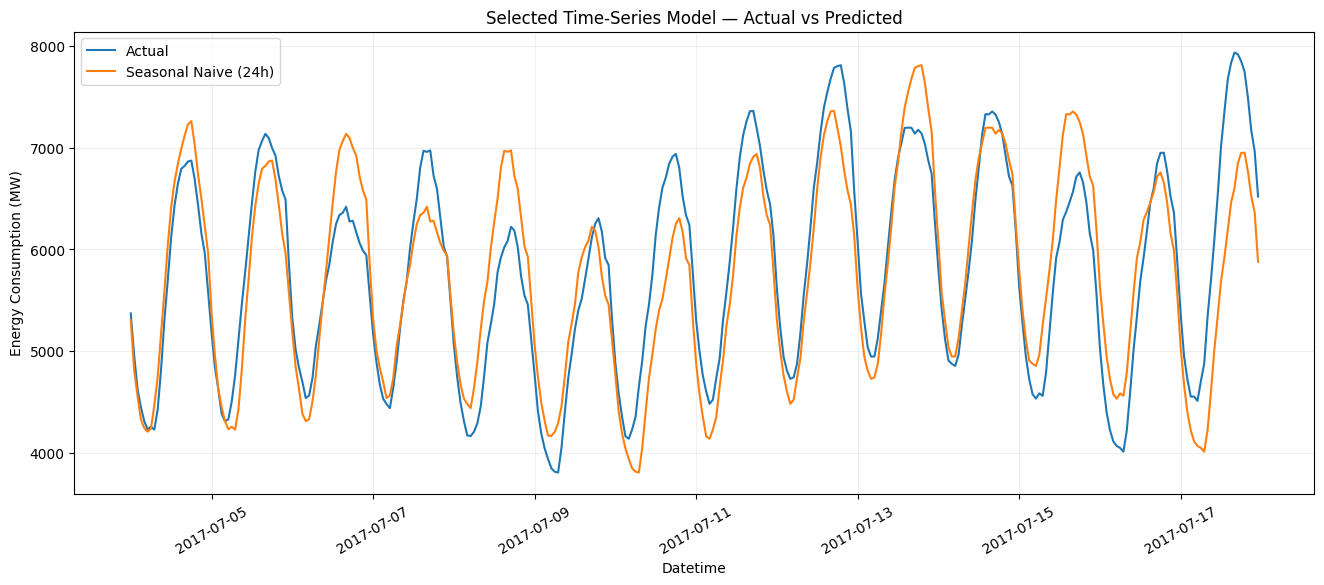

In [73]:
# ============================================================
# SELECTED MODEL — VALIDATION ACTUAL VS PREDICTED
# ============================================================

selected_validation_predictions = {
    "Seasonal Naive (24h)": valid_naive["Prediction"].values,
    "Holt-Winters": hw_pred.values,
    "ARIMA(2,1,2)": arima_pred.values,
    "SARIMA(1,1,1)x(1,1,1,24)": sarima_pred.values
}[final_model_name]

# Align the naive timestamps because its first rows can be dropped if a lag is unavailable.
if final_model_name == "Seasonal Naive (24h)":
    selected_validation_actual = valid_naive["PJMW_MW"].values
    selected_validation_dates = valid_naive["Datetime"].values
else:
    selected_validation_actual = model_valid["PJMW_MW"].values
    selected_validation_dates = model_valid["Datetime"].values

plot_n = min(24 * 14, len(selected_validation_actual))

plt.figure(figsize=(16, 6))
plt.plot(selected_validation_dates[:plot_n], selected_validation_actual[:plot_n], label="Actual")
plt.plot(selected_validation_dates[:plot_n], selected_validation_predictions[:plot_n], label=final_model_name)
plt.title("Selected Time-Series Model — Actual vs Predicted")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.show()


Mean residual: 14.575 MW
Residual standard deviation: 536.225 MW
Maximum absolute error: 1484 MW


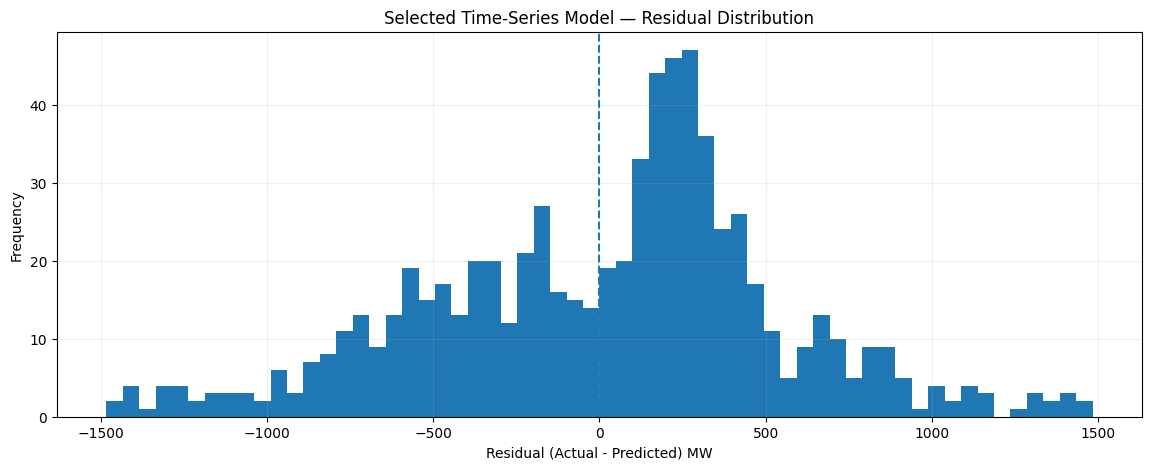

In [74]:
# ============================================================
# SELECTED MODEL — RESIDUAL AND ERROR ANALYSIS
# ============================================================

selected_error_df = pd.DataFrame({
    "Datetime": pd.to_datetime(selected_validation_dates),
    "Actual_MW": selected_validation_actual,
    "Predicted_MW": selected_validation_predictions
})
selected_error_df["Residual_MW"] = selected_error_df["Actual_MW"] - selected_error_df["Predicted_MW"]
selected_error_df["Absolute_Error_MW"] = selected_error_df["Residual_MW"].abs()
selected_error_df["Hour"] = selected_error_df["Datetime"].dt.hour
selected_error_df["DayOfWeek"] = selected_error_df["Datetime"].dt.dayofweek

print("Mean residual:", round(selected_error_df["Residual_MW"].mean(), 3), "MW")
print("Residual standard deviation:", round(selected_error_df["Residual_MW"].std(), 3), "MW")
print("Maximum absolute error:", round(selected_error_df["Absolute_Error_MW"].max(), 3), "MW")

plt.figure(figsize=(14, 5))
plt.hist(selected_error_df["Residual_MW"], bins=60)
plt.axvline(0, linestyle="--")
plt.title("Selected Time-Series Model — Residual Distribution")
plt.xlabel("Residual (Actual - Predicted) MW")
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.show()


Average absolute error by hour:


,MAE_MW
Hour,
0,317.333333
1,286.833333
2,270.300000
3,253.833333
4,240.866667
5,260.766667
6,302.500000
7,393.066667
8,426.466667


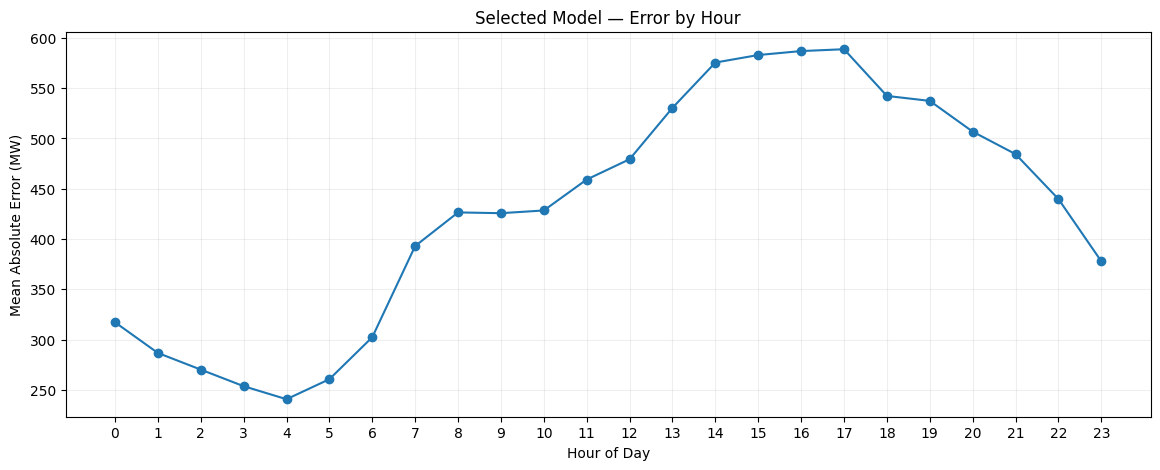

Average absolute error by weekday:


,MAE_MW
Monday,711.614583
Tuesday,354.658333
Wednesday,288.450000
Thursday,312.125000
Friday,250.739583
Saturday,709.447917
Sunday,429.875000


In [75]:
# ============================================================
# SELECTED MODEL — ERROR BY HOUR AND WEEKDAY
# ============================================================

hour_error_selected = selected_error_df.groupby("Hour")["Absolute_Error_MW"].mean()
weekday_error_selected = selected_error_df.groupby("DayOfWeek")["Absolute_Error_MW"].mean()

print("Average absolute error by hour:")
display(hour_error_selected.to_frame("MAE_MW"))

plt.figure(figsize=(14, 5))
plt.plot(hour_error_selected.index, hour_error_selected.values, marker="o")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (MW)")
plt.title("Selected Model — Error by Hour")
plt.xticks(range(24))
plt.grid(alpha=0.2)
plt.show()

print("Average absolute error by weekday:")
weekday_error_selected.index = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
display(weekday_error_selected.to_frame("MAE_MW"))


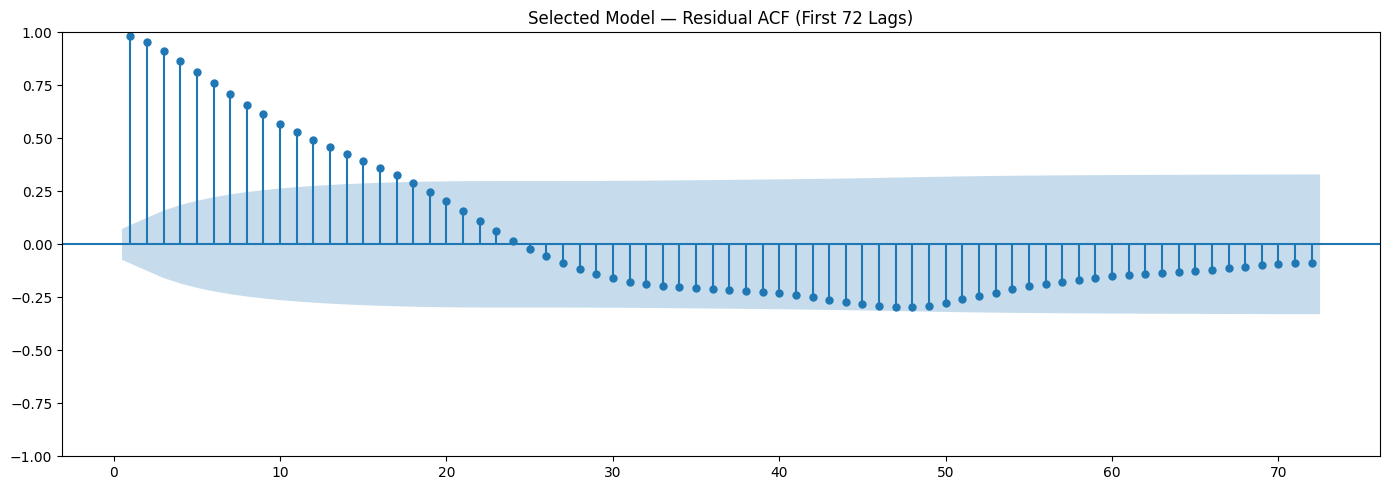

Interpretation: ideally, residual autocorrelation should be small. Strong remaining structure suggests the model has not captured all temporal information.


In [76]:
# ============================================================
# SELECTED MODEL — RESIDUAL AUTOCORRELATION
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(selected_error_df["Residual_MW"].dropna(), lags=72, zero=False, ax=ax)
ax.set_title("Selected Model — Residual ACF (First 72 Lags)")
plt.tight_layout()
plt.show()

print("Interpretation: ideally, residual autocorrelation should be small. Strong remaining structure suggests the model has not captured all temporal information.")


# **Final Last-Year Evaluation — Time-Series Model Only**

The last year remains the final unseen period. To avoid a single long open-loop ARIMA/SARIMA forecast dominating runtime, we evaluate the selected model using several chronological **30-day rolling windows distributed across the final year**.

For each window:
- only data before the window is used for fitting
- the model forecasts the next 30 days
- no future observations from that window are used

This gives a more realistic picture of how the selected forecasting method behaves at different points in the final year.

In [77]:
# ============================================================
# ROLLING 30-DAY EVALUATION ACROSS THE FINAL TEST YEAR
# ============================================================

CLASSICAL_TRAIN_HOURS = 90 * 24
ROLLING_HORIZON = 30 * 24

def fit_and_forecast_ts(model_name, train_series, horizon):
    train_series = train_series.astype(float).tail(CLASSICAL_TRAIN_HOURS)
    if model_name == "Seasonal Naive (24h)":
        values = train_series.values
        return np.array([values[-24 + (i % 24)] for i in range(horizon)], dtype=float)
    if model_name == "Holt-Winters":
        model = ExponentialSmoothing(
            train_series, trend="add", damped_trend=True,
            seasonal="add", seasonal_periods=24,
            initialization_method="estimated"
        ).fit(optimized=True)
        return np.asarray(model.forecast(horizon), dtype=float)
    if model_name == "ARIMA(2,1,2)":
        model = ARIMA(train_series, order=(2,1,2)).fit()
        return np.asarray(model.forecast(horizon), dtype=float)
    if model_name == "SARIMA(1,1,1)x(1,1,1,24)":
        model = SARIMAX(
            train_series, order=(1,1,1), seasonal_order=(1,1,1,24),
            enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False)
        return np.asarray(model.forecast(horizon), dtype=float)
    raise ValueError("Unknown time-series model")

# Four 30-day windows spread across the final year.
test_start_ts = test_df["Datetime"].min()
test_end_ts = test_df["Datetime"].max()
window_starts = [
    test_start_ts,
    test_start_ts + pd.Timedelta(days=90),
    test_start_ts + pd.Timedelta(days=180),
    test_start_ts + pd.Timedelta(days=270)
]

rolling_records = []
rolling_forecasts = []

for window_start in window_starts:
    window_end = window_start + pd.Timedelta(hours=ROLLING_HORIZON - 1)
    if window_end > test_end_ts:
        continue

    fit_end = window_start - pd.Timedelta(hours=1)
    fit_series = clean_df[clean_df["Datetime"] <= fit_end].set_index("Datetime")[target]
    actual_window = clean_df[
        (clean_df["Datetime"] >= window_start) &
        (clean_df["Datetime"] <= window_end)
    ][["Datetime", target]].copy()

    pred = fit_and_forecast_ts(final_model_name, fit_series, len(actual_window))
    actual = actual_window[target].values

    result = evaluate_forecast(
        actual, pred, final_model_name,
        f"Final-year window {window_start.date()} to {window_end.date()}"
    )
    result["Window Start"] = window_start
    rolling_records.append(result)

    tmp = actual_window.copy()
    tmp["Predicted_MW"] = pred
    tmp["Window_Start"] = window_start
    rolling_forecasts.append(tmp)

rolling_results = pd.DataFrame(rolling_records)
rolling_forecast_df = pd.concat(rolling_forecasts, ignore_index=True)

display(rolling_results[["Window Start", "Model", "MAE", "RMSE", "MAPE (%)"]])

print("\nAverage final-year rolling performance:")
display(rolling_results[["MAE", "RMSE", "MAPE (%)"]].mean().to_frame("Average"))


,Window Start,Model,MAE,RMSE,MAPE (%)
0,2017-08-03,Seasonal Naive (24h),747.913889,963.198090,13.868095
1,2017-11-01,Seasonal Naive (24h),437.726768,511.367928,7.975414
2,2018-01-30,Seasonal Naive (24h),659.556944,774.071852,11.098434
3,2018-04-30,Seasonal Naive (24h),555.551389,761.470129,9.756954



Average final-year rolling performance:


,Average
MAE,600.187248
RMSE,752.527000
MAPE (%),10.674724


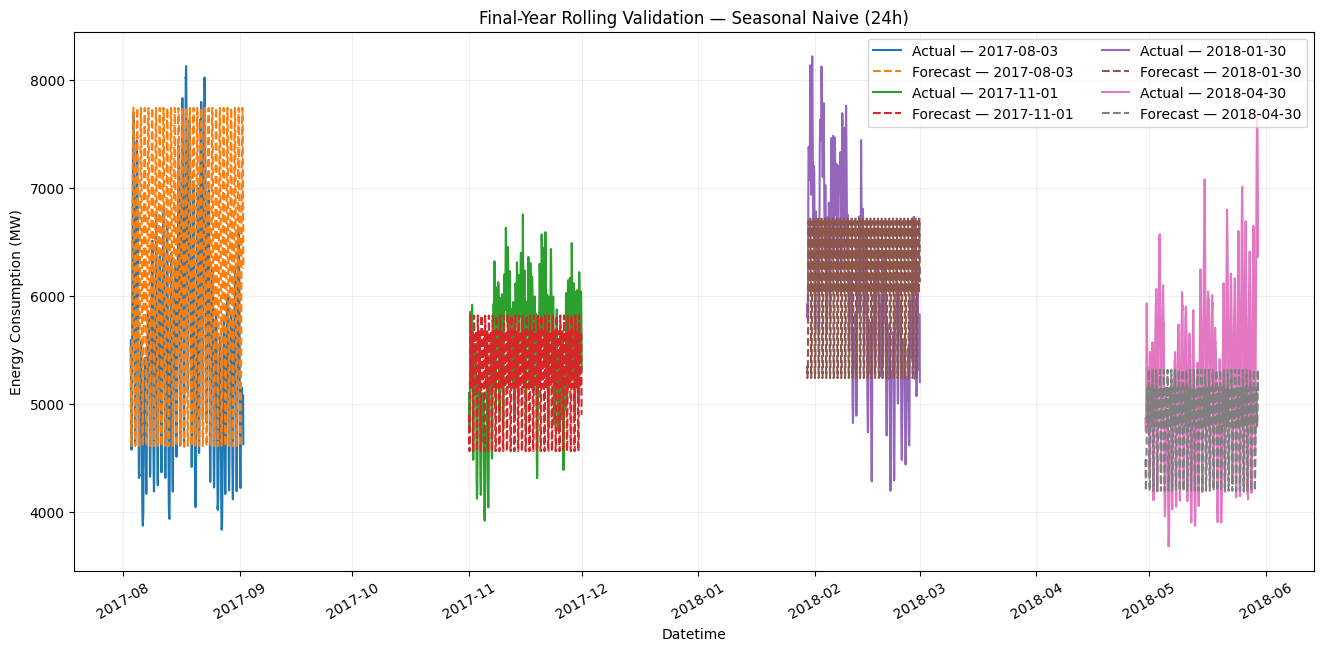

In [78]:
# ============================================================
# FINAL-YEAR ROLLING FORECAST GRAPH
# ============================================================

plt.figure(figsize=(16, 7))
for start, group in rolling_forecast_df.groupby("Window_Start"):
    plt.plot(group["Datetime"], group[target], label=f"Actual — {start.date()}")
    plt.plot(group["Datetime"], group["Predicted_MW"], linestyle="--", label=f"Forecast — {start.date()}")

plt.title(f"Final-Year Rolling Validation — {final_model_name}")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend(ncol=2)
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.show()


# **30-Day / 720-Hour Production Forecast**

After selecting the time-series model, we retrain **that same forecasting approach** using the latest available historical demand and generate the next 30 days.

This is intentionally different from the ML recursive feature builder: a classical time-series model forecasts directly from the historical sequence and its fitted temporal structure.

In [79]:
# ============================================================
# FIT FINAL PRODUCTION TIME-SERIES MODEL
# ============================================================

production_series = clean_df.set_index("Datetime")[target].astype(float).tail(CLASSICAL_TRAIN_HOURS)

if final_model_name == "Seasonal Naive (24h)":
    final_ts_model = None
    future_predictions = np.array([
        production_series.values[-24 + (i % 24)] for i in range(720)
    ], dtype=float)
else:
    if final_model_name == "Holt-Winters":
        final_ts_model = ExponentialSmoothing(
            production_series, trend="add", damped_trend=True,
            seasonal="add", seasonal_periods=24,
            initialization_method="estimated"
        ).fit(optimized=True)
    elif final_model_name == "ARIMA(2,1,2)":
        final_ts_model = ARIMA(production_series, order=(2,1,2)).fit()
    elif final_model_name == "SARIMA(1,1,1)x(1,1,1,24)":
        final_ts_model = SARIMAX(
            production_series, order=(1,1,1), seasonal_order=(1,1,1,24),
            enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False)
    future_predictions = np.asarray(final_ts_model.forecast(720), dtype=float)

future_dates = pd.date_range(
    start=clean_df["Datetime"].max() + pd.Timedelta(hours=1),
    periods=720, freq="h"
)

future_df = pd.DataFrame({
    "Datetime": future_dates,
    "Predicted_MW": future_predictions
})

print("Final production model:", final_model_name)
print("Forecast start:", future_df["Datetime"].min())
print("Forecast end:", future_df["Datetime"].max())
print("Forecast hours:", len(future_df))
display(future_df.head(24))


Final production model: Seasonal Naive (24h)
Forecast start: 2018-08-03 01:00:00
Forecast end: 2018-09-02 00:00:00
Forecast hours: 720


,Datetime,Predicted_MW
0,2018-08-03 01:00:00,5100.0
1,2018-08-03 02:00:00,4840.0
2,2018-08-03 03:00:00,4745.0
3,2018-08-03 04:00:00,4572.0
4,2018-08-03 05:00:00,4594.0
5,2018-08-03 06:00:00,4826.0
6,2018-08-03 07:00:00,5114.0
7,2018-08-03 08:00:00,5333.0
8,2018-08-03 09:00:00,5597.0
9,2018-08-03 10:00:00,5775.0


In [80]:
# ============================================================
# 30-DAY FORECAST QUALITY CHECKS
# ============================================================

print("Rows:", len(future_df))
print("Missing predictions:", future_df["Predicted_MW"].isna().sum())
print("Minimum forecast:", round(future_df["Predicted_MW"].min(), 2), "MW")
print("Maximum forecast:", round(future_df["Predicted_MW"].max(), 2), "MW")
print("Average forecast:", round(future_df["Predicted_MW"].mean(), 2), "MW")

assert len(future_df) == 720
assert future_df["Predicted_MW"].notna().all()


Rows: 720
Missing predictions: 0
Minimum forecast: 4572.0 MW
Maximum forecast: 6758.0 MW
Average forecast: 5810.29 MW


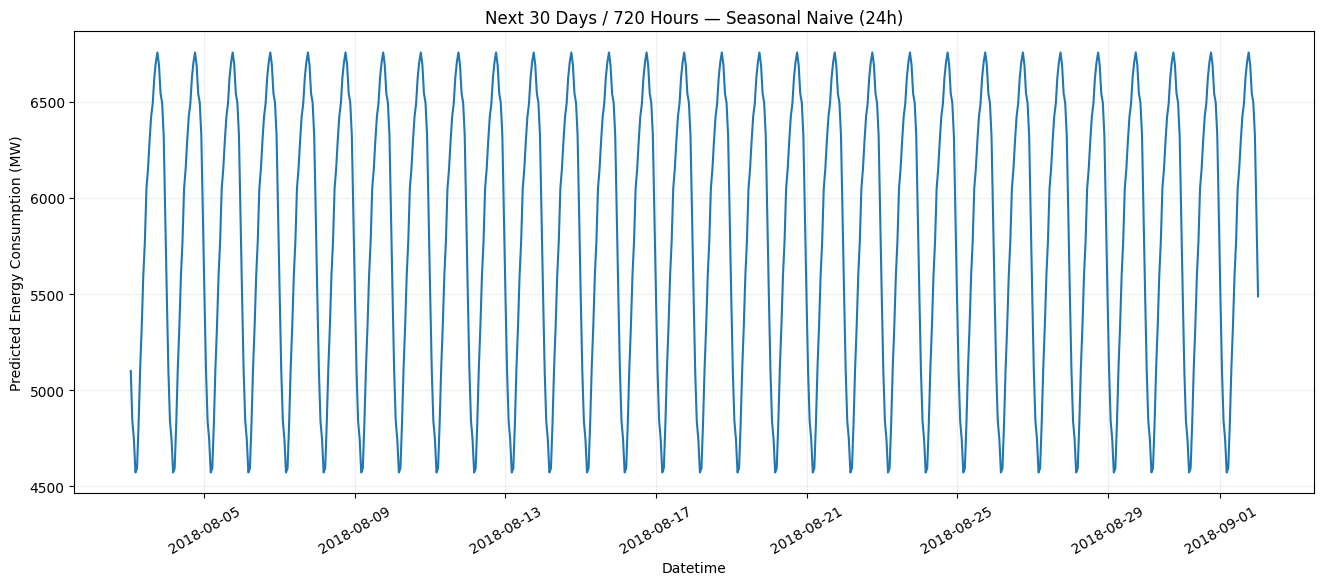

In [81]:
# ============================================================
# NEXT 30 DAYS — HOURLY FORECAST GRAPH
# ============================================================

plt.figure(figsize=(16, 6))
plt.plot(future_df["Datetime"], future_df["Predicted_MW"])
plt.title(f"Next 30 Days / 720 Hours — {final_model_name}")
plt.xlabel("Datetime")
plt.ylabel("Predicted Energy Consumption (MW)")
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.show()


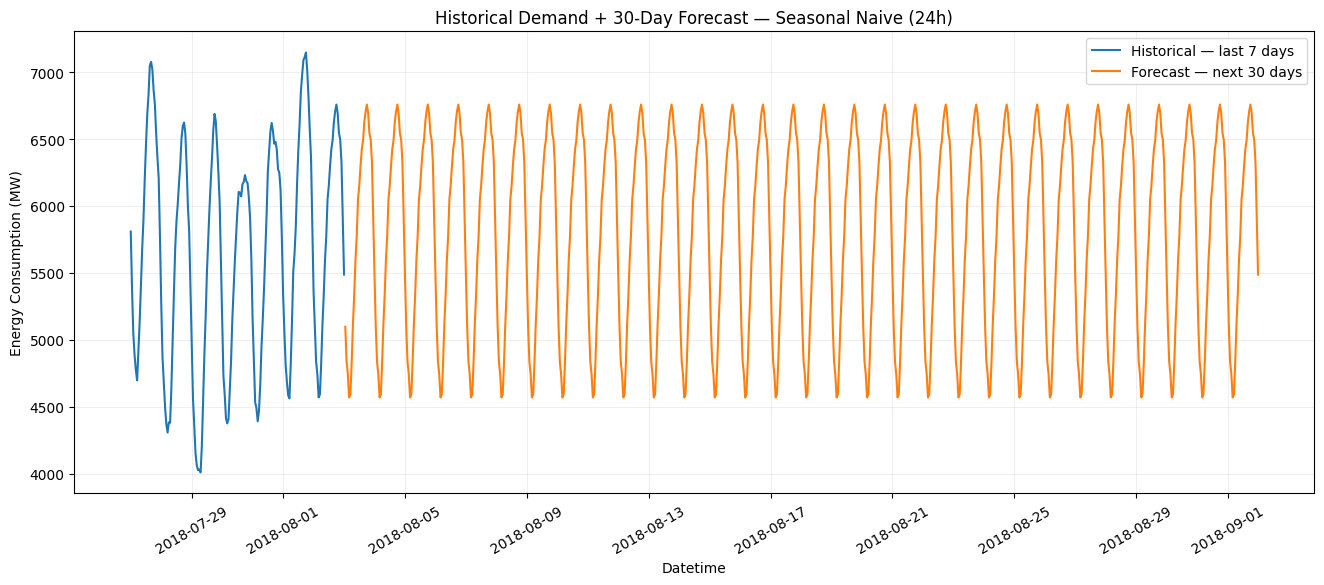

In [82]:
# ============================================================
# HISTORICAL + FUTURE FORECAST
# ============================================================

recent_history = clean_df[
    clean_df["Datetime"] >= clean_df["Datetime"].max() - pd.Timedelta(days=7)
]

plt.figure(figsize=(16, 6))
plt.plot(recent_history["Datetime"], recent_history[target], label="Historical — last 7 days")
plt.plot(future_df["Datetime"], future_df["Predicted_MW"], label="Forecast — next 30 days")
plt.title(f"Historical Demand + 30-Day Forecast — {final_model_name}")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (MW)")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=30)
plt.show()


In [83]:
daily_forecast = (
    future_df.set_index("Datetime")["Predicted_MW"]
    .resample("D")
    .agg(["mean", "min", "max"])
    .reset_index()
)

daily_forecast.columns = [
    "Date", "Average_Predicted_MW",
    "Minimum_Predicted_MW", "Maximum_Predicted_MW"
]

daily_forecast["Peak_Hour"] = (
    future_df.set_index("Datetime")["Predicted_MW"]
    .resample("D").apply(lambda x: x.idxmax()).dt.hour.values
)

display(daily_forecast)

,Date,Average_Predicted_MW,Minimum_Predicted_MW,Maximum_Predicted_MW,Peak_Hour
0,2018-08-03,5824.260870,4572.0,6758.0,18
1,2018-08-04,5810.291667,4572.0,6758.0,18
2,2018-08-05,5810.291667,4572.0,6758.0,18
3,2018-08-06,5810.291667,4572.0,6758.0,18
4,2018-08-07,5810.291667,4572.0,6758.0,18
5,2018-08-08,5810.291667,4572.0,6758.0,18
6,2018-08-09,5810.291667,4572.0,6758.0,18
7,2018-08-10,5810.291667,4572.0,6758.0,18
8,2018-08-11,5810.291667,4572.0,6758.0,18
9,2018-08-12,5810.291667,4572.0,6758.0,18


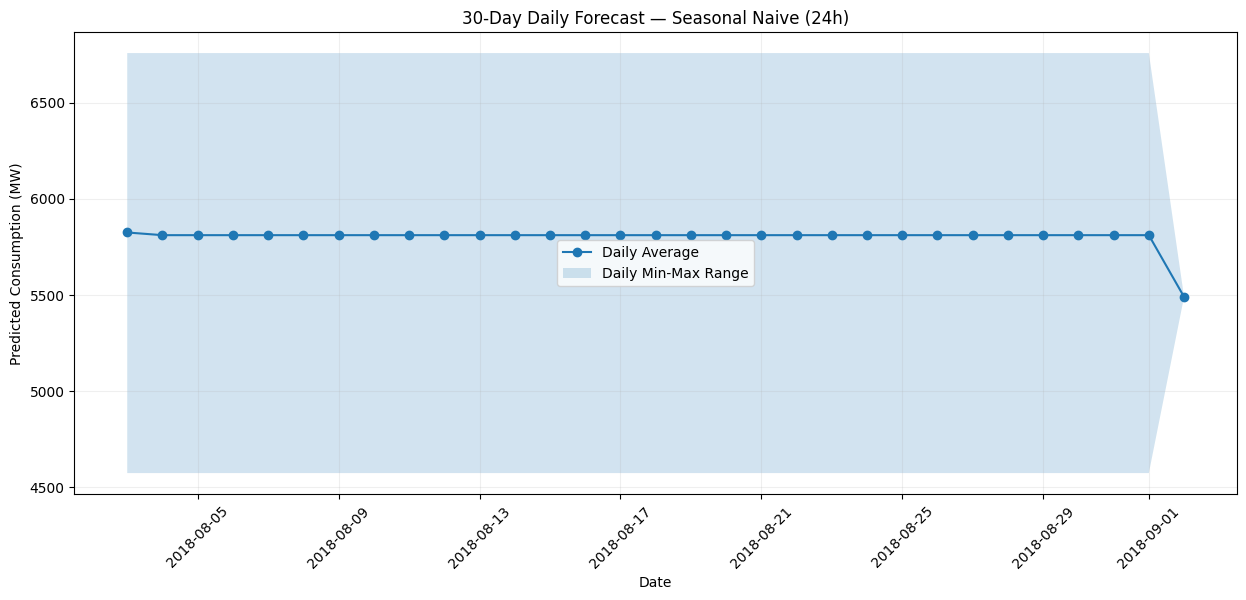

In [84]:
# ============================================================
# DAILY FORECAST VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 6))
plt.plot(daily_forecast["Date"], daily_forecast["Average_Predicted_MW"], marker="o", label="Daily Average")
plt.fill_between(
    daily_forecast["Date"],
    daily_forecast["Minimum_Predicted_MW"],
    daily_forecast["Maximum_Predicted_MW"],
    alpha=0.2, label="Daily Min-Max Range"
)
plt.title(f"30-Day Daily Forecast — {final_model_name}")
plt.xlabel("Date")
plt.ylabel("Predicted Consumption (MW)")
plt.legend()
plt.grid(alpha=0.2)
plt.xticks(rotation=45)
plt.show()


# **Project Overview — Final Deliverables**

The completed project now contains four connected layers:

### 1. EDA
Detailed historical analysis explains hourly, weekly, monthly, yearly, seasonal and holiday behavior.

### 2. Forecasting experiments
Classical time-series, ML, PCA and LSTM models are compared without random shuffling.

### 3. Production forecasting decision
The best **classical time-series** model is selected for deployment, even if a benchmark ML model has a lower raw error.

### 4. Business-ready outputs
The notebook produces:
- model comparison table
- comparison graph
- selected-model metrics
- actual vs predicted validation graph
- residual/error analysis
- final-year rolling validation
- next 30-day / 720-hour hourly forecast
- historical + future forecast graph
- daily forecast summary
- daily min/max range
- deployment model and metadata

This structure is designed so the same selected time-series model can be used later for **GitHub + Hugging Face + Streamlit deployment**.

In [85]:
# ============================================================
# SAVE DEPLOYMENT ARTIFACTS — TIME-SERIES PRODUCTION MODEL
# ============================================================

import joblib
import json

future_df.to_csv("pjm_final_30_day_hourly_forecast.csv", index=False)
daily_forecast.to_csv("pjm_final_30_day_daily_forecast.csv", index=False)
all_model_results.to_csv("pjm_all_model_comparison_results.csv", index=False)
ts_results.to_csv("pjm_time_series_model_comparison.csv", index=False)
rolling_results.to_csv("pjm_final_year_rolling_validation.csv", index=False)

# Save the fitted production time-series model.
# For Seasonal Naive there is no fitted statistical object, so save metadata instead.
if final_ts_model is not None:
    joblib.dump(final_ts_model, "pjm_final_time_series_model.pkl")
else:
    with open("pjm_final_time_series_model.json", "w") as f:
        json.dump({
            "model": final_model_name,
            "seasonal_period_hours": 24,
            "description": "Forecast uses the value from the same hour on the previous day."
        }, f, indent=2)

with open("pjm_forecasting_metadata.json", "w") as f:
    json.dump({
        "project": "P605 - PJM Hourly Energy Consumption Forecasting",
        "production_model": final_model_name,
        "model_family": "Classical Time-Series",
        "forecast_horizon_hours": 720,
        "forecast_horizon_days": 30,
        "training_window_hours": CLASSICAL_TRAIN_HOURS,
        "seasonal_period_hours": 24,
        "selection_rule": "Lowest MAE among classical time-series models on chronological validation"
    }, f, indent=2)

clean_df[["Datetime", target]].tail(168).to_csv(
    "pjm_forecast_history_168.csv", index=False
)

print("Deployment artifacts saved successfully.")


Deployment artifacts saved successfully.


In [86]:
# ============================================================
# FINAL PROJECT VALIDATION / PRESENTATION SUMMARY
# ============================================================

print("=" * 70)
print("P605 — FINAL PJM ENERGY FORECASTING PROJECT")
print("=" * 70)

print("\nDATA")
print("Rows after cleaning:", len(clean_df))
print("Date range:", clean_df["Datetime"].min(), "to", clean_df["Datetime"].max())
print("Missing values:", int(clean_df.isna().sum().sum()))
print("Duplicate timestamps:", int(clean_df["Datetime"].duplicated().sum()))

print("\nMODEL COMPARISON")
print("All models tested:", len(all_model_results))
print("Production-eligible family: Classical Time-Series")

print("\nSELECTED PRODUCTION MODEL")
print("Model:", final_model_name)
print("Development MAE:", round(selected_ts_row["MAE"], 3), "MW")
print("Development RMSE:", round(selected_ts_row["RMSE"], 3), "MW")
print("Development MAPE:", round(selected_ts_row["MAPE (%)"], 3), "%")

print("\nFINAL-YEAR ROLLING VALIDATION")
print("Average MAE:", round(rolling_results["MAE"].mean(), 3), "MW")
print("Average RMSE:", round(rolling_results["RMSE"].mean(), 3), "MW")
print("Average MAPE:", round(rolling_results["MAPE (%)"].mean(), 3), "%")

print("\nNEXT 30 DAYS")
print("Hourly forecasts:", len(future_df))
print("Forecast period:", future_df["Datetime"].min(), "to", future_df["Datetime"].max())
print("Average forecast:", round(future_df["Predicted_MW"].mean(), 2), "MW")

print("\nDEPLOYMENT FILES")
for filename in [
    "pjm_final_30_day_hourly_forecast.csv",
    "pjm_final_30_day_daily_forecast.csv",
    "pjm_all_model_comparison_results.csv",
    "pjm_time_series_model_comparison.csv",
    "pjm_final_year_rolling_validation.csv",
    "pjm_final_time_series_model.pkl",
    "pjm_forecasting_metadata.json",
    "pjm_forecast_history_168.csv"
]:
    if os.path.exists(filename):
        print("-", filename)


P605 — FINAL PJM ENERGY FORECASTING PROJECT

DATA
Rows after cleaning: 143038
Date range: 2002-04-08 02:00:00 to 2018-08-03 00:00:00
Missing values: 0
Duplicate timestamps: 4

MODEL COMPARISON
All models tested: 11
Production-eligible family: Classical Time-Series

SELECTED PRODUCTION MODEL
Model: Seasonal Naive (24h)
Development MAE: 429.025 MW
Development RMSE: 536.051 MW
Development MAPE: 7.455 %

FINAL-YEAR ROLLING VALIDATION
Average MAE: 600.187 MW
Average RMSE: 752.527 MW
Average MAPE: 10.675 %

NEXT 30 DAYS
Hourly forecasts: 720
Forecast period: 2018-08-03 01:00:00 to 2018-09-02 00:00:00
Average forecast: 5810.29 MW

DEPLOYMENT FILES
- pjm_final_30_day_hourly_forecast.csv
- pjm_final_30_day_daily_forecast.csv
- pjm_all_model_comparison_results.csv
- pjm_time_series_model_comparison.csv
- pjm_final_year_rolling_validation.csv
- pjm_forecasting_metadata.json
- pjm_forecast_history_168.csv


In [87]:
# ============================================================
# EXPORT FULL CLEANED DATASET FOR STREAMLIT EDA
# ============================================================

clean_df[["Datetime", "PJMW_MW"]].to_csv(
    "pjm_clean_hourly_data.csv",
    index=False
)

print("Full cleaned deployment dataset exported successfully.")

Full cleaned deployment dataset exported successfully.


In [134]:
# ============================================================
# FINAL PROJECT SUMMARY
# ============================================================

print("=" * 75)
print("P605 - PJM HOURLY ENERGY CONSUMPTION FORECASTING")
print("=" * 75)

print("\nDATASET")
print("-" * 75)
print("Historical PJM hourly electricity consumption data")

print("\nMODELS EVALUATED")
print("-" * 75)
print("1. Seasonal Naive (24h)")
print("2. Holt-Winters")
print("3. ARIMA(2,1,2)")
print("4. SARIMA(1,1,1)x(1,1,1,24)")
print("5. XGBoost")

print("\nXGBOOST VALIDATION RESULTS")
print("-" * 75)
print(f"MAE  : {mae:.2f} MW")
print(f"RMSE : {rmse:.2f} MW")
print(f"MAPE : {mape:.2f}%")

print("\nXGBOOST FORECAST")
print("-" * 75)
print("Forecast horizon : 720 hours")
print("Forecast period  : 30 days")
print(f"Start            : {xgb_30_day_forecast['Datetime'].min()}")
print(f"End              : {xgb_30_day_forecast['Datetime'].max()}")

print("\nPRODUCTION MODEL")
print("-" * 75)
print("Seasonal Naive (24h)")
print("Model family: Classical Time-Series")

print("\nXGBOOST ROLE")
print("-" * 75)
print("XGBoost is included as a machine-learning benchmark.")

print("\nOUTPUT FILES")
print("-" * 75)
for file in required_files:
    if os.path.exists(file):
        print("✓", file)

print("\n" + "=" * 75)
print("PROJECT MODELING SECTION COMPLETED")
print("=" * 75)

P605 - PJM HOURLY ENERGY CONSUMPTION FORECASTING

DATASET
---------------------------------------------------------------------------
Historical PJM hourly electricity consumption data

MODELS EVALUATED
---------------------------------------------------------------------------
1. Seasonal Naive (24h)
2. Holt-Winters
3. ARIMA(2,1,2)
4. SARIMA(1,1,1)x(1,1,1,24)
5. XGBoost

XGBOOST VALIDATION RESULTS
---------------------------------------------------------------------------
MAE  : 72.60 MW
RMSE : 119.68 MW
MAPE : 1.27%

XGBOOST FORECAST
---------------------------------------------------------------------------
Forecast horizon : 720 hours
Forecast period  : 30 days
Start            : 2018-08-03 01:00:00
End              : 2018-09-02 00:00:00

PRODUCTION MODEL
---------------------------------------------------------------------------
Seasonal Naive (24h)
Model family: Classical Time-Series

XGBOOST ROLE
---------------------------------------------------------------------------
XGBoost